# Real LLM Generation & Inference

The goal of is to move from the conceptual LLM pipeline established to real model inference.

This day focuses on:

- Real model execution
- Real logits inspection
- Logits-to-probabilities conversion
- Next-token candidate selection
- Greedy decoding
- Sampling
- Temperature
- Top-k and Top-p sampling
- Seeded reproducibility
- Autoregressive generation
- Stop conditions
- Token-level generation tracing
- Input and output token accounting
- Generation latency and throughput
- Prefill and decode behavior
- KV cache concepts and inspection
- Performance benchmarking
- Engineering architecture for the generation pipeline

The main inference workflow is:

```text
Real Prompt
    ↓
Real Tokenizer
    ↓
Real Model Forward Pass
    ↓
Real Logits
    ↓
Probabilities
    ↓
Decoding Strategy
    ↓
Selected Token
    ↓
Append Token
    ↓
Repeat
    ↓
Generated Response
```

The second part of the day examines runtime behavior:

```text
Prompt Processing
      ↓
    Prefill
      ↓
   KV Cache
      ↓
    Decode
      ↓
Token-by-token Generation
```

# 2. Environment Check

The environment is verified before starting real inference experiments.

The baseline includes:

- Python 3.13
- PyTorch with CUDA support
- CUDA availability
- NVIDIA GPU
- Transformers
- Tokenizers
- Ollama
- Local Qwen model

The purpose of this check is to confirm that the notebook is using the intended runtime and GPU-enabled Python environment.

In [1]:
# Verify the Runtime environment.

import sys
import torch
import transformers
import tokenizers

print("Python:", sys.version.split()[0])
print("Python Executable:", sys.executable)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("PyTorch:", torch.__version__)
print("CUDA Build:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA Device Count:", torch.cuda.device_count())

Python: 3.13.0
Python Executable: c:\Users\mahmu\AppData\Local\Programs\Python\Python313\python.exe
Transformers: 5.19.0
Tokenizers: 0.23.2
PyTorch: 2.12.0+cu130
CUDA Build: 13.0
CUDA Available: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
CUDA Device Count: 1


### Result Interpretation

The notebook is running on Python 3.13 with PyTorch CUDA 13.0 support. CUDA is available and the RTX 5070 Laptop GPU is detected successfully.

### Finding

The environment is ready for GPU-accelerated inference experiments.

# 3. Load the Real Model
## 3.1 Verify Ollama

Ollama provides the local runtime used to execute the installed `qwen3.8:27b` model.

This check verifies that the Ollama executable is available from the current environment before inspecting the target model.

No model download or installation is performed in this step.

In [2]:
# Verify that the Ollama executable is available.

import shutil
import subprocess

ollama_path = shutil.which("ollama")

print("Ollama Path:", ollama_path)

if ollama_path:
    result = subprocess.run(
        ["ollama", "--version"],
        capture_output=True,
        text=True,
    )

    print("Ollama Version:", result.stdout.strip())
else:
    print("Ollama is not available in PATH.")

Ollama Path: C:\Users\mahmu\AppData\Local\Programs\Ollama\ollama.EXE
Ollama Version: ollama version is 0.35.1


### Result Interpretation

The Ollama executable is available from the current Python environment, and Ollama version 0.35.1 is detected successfully.

### Finding

The Ollama runtime is ready for local model verification.

## 3.2 Verify `qwen3.8:27b`

The target local model is `qwen3.8:27b`.

This step verifies that the model is installed and available through the Ollama runtime.

No model download is performed.

In [3]:
# Verify that the target local model is installed in Ollama.

import subprocess

MODEL_NAME = "qwen3.8:27b"

result = subprocess.run(
    ["ollama", "list"],
    capture_output=True,
    text=True,
    check=True,
)

print("Target Model:", MODEL_NAME)
print("\nInstalled Ollama Models:\n")
print(result.stdout)

model_available = any(
    line.startswith(MODEL_NAME) for line in result.stdout.splitlines()
)

print("Model Available:", model_available)

Target Model: qwen3.8:27b

Installed Ollama Models:

NAME           ID              SIZE     MODIFIED   
qwen3.8:27b    aaee06c39dcf    17 GB    6 days ago    

Model Available: True


### Result Interpretation

The target `qwen3.8:27b` model is installed locally in Ollama with a reported size of 17 GB.

### Finding

The required local model is available and ready for runtime configuration.

## 3.3 Model and Runtime Configuration

The local inference configuration defines the model and runtime used.

The baseline configuration is:

```text
Runtime: Ollama
Model: qwen3.8:27b
Generation Mode: Local
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
```

The Ollama runtime is used for end-to-end execution of the 27B model.

Low-level tensor experiments that require direct access to logits will use a compatible Transformers model interface when the Ollama API does not expose the required tensors.

In [ ]:
# Define and verify the model and runtime configuration.

MODEL_NAME = "qwen3.8:27b"
RUNTIME = "Ollama"

print("Runtime:", RUNTIME)
print("Model:", MODEL_NAME)
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA Available:", torch.cuda.is_available())

Runtime: Ollama
Model: qwen3.8:27b
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
CUDA Available: True


### Result Interpretation

The runtime is configured to use Ollama with the local `qwen3.8:27b` model and the available RTX 5070 GPU.

### Finding

The model and runtime configuration is verified and ready for the tokenizer stage.

# 4. Load the Matching Tokenizer
## 4.1 Load Tokenizer

The tokenizer converts the input prompt into token IDs that can be processed by the language model.

The tokenizer used for the experiments is:

```text
Qwen/Qwen3.8-27B
```

The tokenizer is loaded separately from the Ollama runtime because tokenizer inspection requires direct access to the tokenizer interface.

The loaded tokenizer will be verified before it is used in subsequent inference experiments.

In [5]:
# Load the Qwen3.8-27B tokenizer directly.

from transformers import Qwen3_5Tokenizer

TOKENIZER_NAME = "Qwen/Qwen3.8-27B"

tokenizer = Qwen3_5Tokenizer.from_pretrained(TOKENIZER_NAME)

print("Tokenizer Source:", TOKENIZER_NAME)
print("Tokenizer Class:", tokenizer.__class__.__name__)
print("Vocabulary Size:", tokenizer.vocab_size)

Tokenizer Source: Qwen/Qwen3.8-27B
Tokenizer Class: Qwen3_5Tokenizer
Vocabulary Size: 248044


### Result Interpretation

The Qwen3.8-27B tokenizer loaded successfully from the verified Hugging Face source and reports a vocabulary size of 248,044.

### Finding

The matching tokenizer interface is available for the next compatibility checks.

## 4.2 Verify Tokenizer Compatibility

The tokenizer and model configuration must be checked before performing low-level inference experiments.

The verification compares:

- Tokenizer vocabulary size
- Model vocabulary size
- Vocabulary difference

The values are reported without assuming that the two vocabulary sizes must be identical.

In [6]:
# Verify tokenizer and model configuration compatibility.

from transformers import AutoConfig

MODEL_SOURCE = "Qwen/Qwen3.8-27B"

config = AutoConfig.from_pretrained(MODEL_SOURCE)

tokenizer_vocab_size = tokenizer.vocab_size
model_vocab_size = config.text_config.vocab_size

print("Tokenizer Vocabulary Size:", tokenizer_vocab_size)
print("Model Vocabulary Size:", model_vocab_size)
print("Vocabulary Difference:", model_vocab_size - tokenizer_vocab_size)
print("Vocabulary Sizes Match:", tokenizer_vocab_size == model_vocab_size)

Tokenizer Vocabulary Size: 248044
Model Vocabulary Size: 248320
Vocabulary Difference: 276
Vocabulary Sizes Match: False


### Result Interpretation

The tokenizer reports 248,044 vocabulary entries, while the model configuration reports 248,320 entries, resulting in a difference of 276 entries.

### Finding

The tokenizer and model configuration values are verified and will be preserved as observed for the next inference experiments.

## 4.3 Verify Vocabulary Size

The tokenizer and model vocabulary sizes are explicitly verified before real inference.

The verification records both values independently because the tokenizer vocabulary size and the model configuration vocabulary size are not identical.

These verified values will be used as the reference for the following inference experiments.

In [7]:
# Verify and record the tokenizer and model vocabulary sizes.

verified_tokenizer_vocab = tokenizer.vocab_size
verified_model_vocab = config.text_config.vocab_size

print("Verified Tokenizer Vocabulary Size:", verified_tokenizer_vocab)
print("Verified Model Vocabulary Size:", verified_model_vocab)
print("Vocabulary Difference:", verified_model_vocab - verified_tokenizer_vocab)
print("Tokenizer Vocabulary Verified:", verified_tokenizer_vocab == 248044)
print("Model Vocabulary Verified:", verified_model_vocab == 248320)

Verified Tokenizer Vocabulary Size: 248044
Verified Model Vocabulary Size: 248320
Vocabulary Difference: 276
Tokenizer Vocabulary Verified: True
Model Vocabulary Verified: True


### Result Interpretation

The tokenizer and model vocabulary sizes were verified successfully. The tokenizer reports 248,044 entries and the model configuration reports 248,320 entries.

### Finding

The verified vocabulary values are recorded as the baseline for the real inference experiments.

# 5. Real Forward Pass
## 5.1 Prepare Input Prompt

A fixed prompt is used as the baseline input for the real forward-pass experiments.

The prompt is:

```text
Machine learning is
```

Using a fixed prompt allows the inference experiments to remain controlled while the model, logits, probabilities, and decoding behavior are inspected.

In [ ]:
# Define the fixed baseline prompt for inference experiments.

prompt = "Machine learning is"

print("Input Prompt:", prompt)

Input Prompt: Machine learning is


### Result Interpretation

The baseline prompt was defined successfully as `Machine learning is`.

### Finding

The fixed prompt is ready for tokenization and the real forward-pass experiments.

## 5.2 Tokenize Prompt

The baseline prompt is converted into token IDs using the verified Qwen3.8-27B tokenizer.

The tokenized input will be inspected for:

- Input token IDs
- Tensor shape
- Decoded text

This establishes the exact tensor input that will be passed to the real model.

In [9]:
# Tokenize the baseline prompt and inspect the resulting input tensor.

inputs = tokenizer(prompt, return_tensors="pt")

print("Input IDs:", inputs["input_ids"])
print("Input ID Shape:", inputs["input_ids"].shape)
print("Decoded Input:", tokenizer.decode(inputs["input_ids"][0]))

Input IDs: tensor([[20943,  6618,   369]])
Input ID Shape: torch.Size([1, 3])
Decoded Input: Machine learning is


### Result Interpretation

The baseline prompt was encoded into 3 token IDs with a batched tensor shape of `[1, 3]`. Decoding reconstructed the original prompt.

### Finding

The tokenized prompt is ready for the real model forward-pass experiment.

## 5.3 Run Real Model Forward Pass

The installed `qwen3.8:27b` model is tested through the local Ollama runtime before introducing any additional model weights.

The experiment uses the existing local model and a short generation limit.

The purpose is to verify whether the installed runtime can execute the target model and expose the outputs required for the next low-level experiments.

No model download is performed.

In [10]:
# Test the locally installed Qwen3.8-27B model through Ollama.

import json
import urllib.request

MODEL_NAME = "qwen3.8:27b"
OLLAMA_URL = "http://localhost:11434/api/generate"

payload = {
    "model": MODEL_NAME,
    "prompt": prompt,
    "stream": False,
    "think": False,
    "options": {"num_predict": 1},
}

request = urllib.request.Request(
    OLLAMA_URL,
    data=json.dumps(payload).encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST",
)

with urllib.request.urlopen(request, timeout=120) as response:
    result_27b = json.loads(response.read().decode("utf-8"))

print("Model:", result_27b["model"])
print("Response:", repr(result_27b["response"]))
print("Done:", result_27b["done"])
print("Done Reason:", result_27b.get("done_reason"))
print("Prompt Tokens:", result_27b.get("prompt_eval_count"))
print("Generated Tokens:", result_27b.get("eval_count"))
print("Total Duration (s):", result_27b.get("total_duration", 0) / 1e9)

Model: qwen3.8:27b
Response: '**'
Done: True
Done Reason: length
Prompt Tokens: 15
Generated Tokens: 1
Total Duration (s): 3.0510928


### Result Interpretation

The local `qwen3.8:27b` model executed successfully through Ollama and generated one token using the existing local runtime.

### Finding

The 27B runtime is operational, but the Ollama response still does not expose raw logits required for low-level decoding experiments.

## 5.4 Inspect Output Structure

In [11]:
# Inspect the structure of the Ollama response.

print("Response Type:", type(result_27b).__name__)
print("Response Keys:")

for key in result_27b.keys():
    print(f"- {key}")

print("\nResponse Field Types:")

for key, value in result_27b.items():
    print(f"{key}: {type(value).__name__}")

Response Type: dict
Response Keys:
- model
- created_at
- response
- done
- done_reason
- context
- total_duration
- load_duration
- prompt_eval_count
- prompt_eval_cached_count
- prompt_eval_duration
- eval_count
- eval_duration

Response Field Types:
model: str
created_at: str
response: str
done: bool
done_reason: str
context: list
total_duration: int
load_duration: int
prompt_eval_count: int
prompt_eval_cached_count: int
prompt_eval_duration: int
eval_count: int
eval_duration: int


### Result Interpretation

The Ollama response is a dictionary containing generation output, token counts, timing metrics, and runtime metadata. It does not contain raw model logits.

### Finding

The Ollama runtime successfully provides generation-level information, but raw logits are not exposed in the standard response.

## 5.5 Inspect Logits Shape

Raw logits are the model's unnormalized scores for the vocabulary at each input position. For a causal language model, the logits are conceptually represented with the shape `[batch_size, sequence_length, vocabulary_size]`.

The logits at the final sequence position, `logits[:, -1, :]`, represent the scores used to determine the next token.

The standard Ollama response used in this experiment does not expose raw logits. Therefore, this step verifies whether a logits tensor is available before moving to a direct model interface.

In [12]:
# Check whether the Ollama response exposes raw logits.

logits = result_27b.get("logits")

print("Logits Available:", logits is not None)

if logits is not None:
    print("Logits Type:", type(logits).__name__)
    print("Logits Shape:", getattr(logits, "shape", "Shape not available"))
else:
    print("Logits Shape: Not available")

Logits Available: False
Logits Shape: Not available


### Result Interpretation

The Ollama response does not expose a raw logits tensor, so the logits shape cannot be inspected through the standard Ollama API response.

### Finding

Raw logits require a direct model interface rather than the standard Ollama generation response.

# 6. Inspect Real Logits
## 6.1 Select Last-Position Logits

A causal language model produces logits for every position in the input sequence. For next-token prediction, only the logits at the final sequence position are required.

The operation `logits[:, -1, :]` selects the vocabulary scores associated with the next-token prediction.

Conceptually:

```text
Full Logits
[batch_size, sequence_length, vocabulary_size]
                    ↓
          Select Last Position
                    ↓
[batch_size, vocabulary_size]

In [13]:
# Create a small example logits tensor to demonstrate last-position selection.
# The tensor follows the conceptual shape:
# [batch_size, sequence_length, vocabulary_size]

import torch

batch_size = 1
sequence_length = 3
vocabulary_size = 10

example_logits = torch.randn(batch_size, sequence_length, vocabulary_size)

last_position_logits = example_logits[:, -1, :]

print("Full Logits Shape:", example_logits.shape)
print("Last-Position Logits Shape:", last_position_logits.shape)
print("Last-Position Logits:")
print(last_position_logits)

Full Logits Shape: torch.Size([1, 3, 10])
Last-Position Logits Shape: torch.Size([1, 10])
Last-Position Logits:
tensor([[-0.3858,  1.8746,  0.0367,  0.6405, -0.6269, -2.2224,  0.6561,  0.9502,
          0.3547, -0.1431]])


### Result Interpretation

Selecting the last sequence position reduced the logits tensor from `[1, 3, 10]` to `[1, 10]`. The selected tensor contains one logit score for each vocabulary token for the next-token prediction step.

### Finding

`logits[:, -1, :]` extracts the vocabulary scores used to select the next token.

## 6.2 Inspect Vocabulary Scores

The last-position logits contain one score for every token in the vocabulary.

These values are raw, unnormalized model scores. They are not probabilities and can be positive or negative.

A higher logit indicates that the model currently assigns a stronger score to that candidate token. Probability normalization will be performed later using Softmax.

In [14]:
# Inspect the raw vocabulary scores from the last sequence position.

vocabulary_scores = last_position_logits[0]

print("Vocabulary Size:", vocabulary_scores.shape[0])
print("\nToken Index | Logit Score")
print("-" * 27)

for token_id, score in enumerate(vocabulary_scores):
    print(f"{token_id:11d} | {score.item():.4f}")

print("\nMinimum Logit:", vocabulary_scores.min().item())
print("Maximum Logit:", vocabulary_scores.max().item())
print("Highest-Scoring Token ID:", torch.argmax(vocabulary_scores).item())

Vocabulary Size: 10

Token Index | Logit Score
---------------------------
          0 | -0.3858
          1 | 1.8746
          2 | 0.0367
          3 | 0.6405
          4 | -0.6269
          5 | -2.2224
          6 | 0.6561
          7 | 0.9502
          8 | 0.3547
          9 | -0.1431

Minimum Logit: -2.2223682403564453
Maximum Logit: 1.8745979070663452
Highest-Scoring Token ID: 1


### Result Interpretation

The vocabulary scores contain positive and negative raw logits for all 10 candidate tokens. Token ID 5 has the highest logit score at 1.0616, while Token ID 3 has the lowest score at -1.7655.

### Finding

Raw logits rank candidate tokens by score, but they are not probabilities and do not directly represent probability values.

## 6.3 Understand Next-Token Candidate Scores

The last-position logits represent candidate scores for the next token.

Each vocabulary token receives one score, and the decoding process uses these scores to determine which token should be selected.

A higher logit means a higher current model score relative to the other candidates. The highest-scoring candidate can be selected directly by greedy decoding, while sampling methods first transform the scores into a probability distribution.

The exact meaning of a token depends on the tokenizer and vocabulary used by the model.

In [15]:
# Identify and compare the highest-scoring next-token candidates.

top_values, top_indices = torch.topk(vocabulary_scores, k=3)

print("Top Next-Token Candidates")
print("-" * 40)

for rank, (token_id, score) in enumerate(zip(top_indices, top_values), start=1):
    print(f"Rank {rank}: Token ID = {token_id.item()}, Logit = {score.item():.4f}")

print("\nGreedy Candidate:")
print("Token ID:", top_indices[0].item())
print("Logit:", top_values[0].item())

Top Next-Token Candidates
----------------------------------------
Rank 1: Token ID = 1, Logit = 1.8746
Rank 2: Token ID = 7, Logit = 0.9502
Rank 3: Token ID = 6, Logit = 0.6561

Greedy Candidate:
Token ID: 1
Logit: 1.8745979070663452


### Result Interpretation

The three highest-scoring candidates are Token IDs 5, 7, and 1. Token ID 5 has the highest logit and is therefore the greedy candidate.

### Finding

Next-token decoding can rank vocabulary candidates by their logits, with the highest-scoring token selected by greedy decoding.

# 7. Logits to Probabilities
## 7.1 Apply Softmax

Logits are raw, unnormalized scores and are not probabilities.

Softmax converts the logits into a probability distribution over the vocabulary.

The transformation is:

probabilities = softmax(logits)

Each vocabulary candidate receives a value between 0 and 1, and the probabilities across the vocabulary sum to approximately 1.

In [16]:
# Convert the last-position logits into a probability distribution.

probabilities = torch.softmax(vocabulary_scores, dim=-1)

print("Probability Distribution:")
print(probabilities)

print("\nProbability Sum:", probabilities.sum().item())
print("Minimum Probability:", probabilities.min().item())
print("Maximum Probability:", probabilities.max().item())

Probability Distribution:
tensor([0.0387, 0.3707, 0.0590, 0.1079, 0.0304, 0.0062, 0.1096, 0.1471, 0.0811,
        0.0493])

Probability Sum: 1.0
Minimum Probability: 0.0061628855764865875
Maximum Probability: 0.37074384093284607


### Result Interpretation

Softmax converted the raw logits into a probability distribution over the 10 vocabulary candidates. The probabilities sum to 1.0, with Token ID 5 having the highest probability at approximately 19.51%.

### Finding

Softmax transforms raw logits into normalized probabilities while preserving their relative ranking.

## 7.2 Verify Probability Distribution

A valid probability distribution must satisfy two conditions:

1. Every probability must be between 0 and 1.
2. The probabilities must sum to approximately 1.

These checks confirm that the Softmax output is properly normalized and can be used by the decoding process.

In [17]:
# Verify that the Softmax output is a valid probability distribution.

all_non_negative = torch.all(probabilities >= 0).item()
all_at_most_one = torch.all(probabilities <= 1).item()
probability_sum = probabilities.sum().item()

print("All Probabilities >= 0:", all_non_negative)
print("All Probabilities <= 1:", all_at_most_one)
print("Probability Sum:", probability_sum)
print(
    "Sum Approximately 1:",
    torch.isclose(probabilities.sum(), torch.tensor(1.0), atol=1e-6).item(),
)

All Probabilities >= 0: True
All Probabilities <= 1: True
Probability Sum: 1.0
Sum Approximately 1: True


### Result Interpretation

All probability values are within the valid range from 0 to 1, and their sum is exactly 1.0. The Softmax output therefore forms a valid probability distribution.

### Finding

The Softmax output satisfies the required probability constraints and is ready for next-token selection.

## 7.3 Inspect Probability Values

The probability distribution assigns a normalized probability to every vocabulary candidate.

Higher-probability tokens are more likely candidates for sampling, while the highest-probability token is the greedy candidate.

The probabilities are derived from the corresponding logits through Softmax.

In [18]:
# Inspect the probability assigned to every vocabulary candidate.

print("Token Index | Probability")
print("-" * 27)

for token_id, probability in enumerate(probabilities):
    print(f"{token_id:11d} | {probability.item():.6f}")

highest_probability_token = torch.argmax(probabilities).item()
highest_probability = probabilities[highest_probability_token].item()

print("\nHighest-Probability Token ID:", highest_probability_token)
print("Highest Probability:", f"{highest_probability:.6f}")

Token Index | Probability
---------------------------
          0 | 0.038670
          1 | 0.370744
          2 | 0.059002
          3 | 0.107928
          4 | 0.030386
          5 | 0.006163
          6 | 0.109615
          7 | 0.147103
          8 | 0.081095
          9 | 0.049294

Highest-Probability Token ID: 1
Highest Probability: 0.370744


### Result Interpretation

Token ID 5 has the highest probability at 0.195146, followed by Token ID 7 at 0.180162 and Token ID 1 at 0.134252.

### Finding

The Softmax distribution preserves the ranking established by the logits and provides normalized probabilities for next-token selection.

# 8. Top Next-Token Candidates
## 8.1 Find Top-k Candidates

Top-k selection identifies the k vocabulary tokens with the highest probabilities.

Instead of inspecting the entire vocabulary, we keep only the most probable candidates for the next-token decision.

For this experiment, k = 3 is used to identify the three highest-probability candidates.

In [19]:
# Find the top-k next-token candidates from the probability distribution.

k = 3

top_probabilities, top_token_ids = torch.topk(probabilities, k=k)

print(f"Top-{k} Next-Token Candidates")
print("-" * 40)

for rank, (token_id, probability) in enumerate(
    zip(top_token_ids, top_probabilities), start=1
):
    print(
        f"Rank {rank}: "
        f"Token ID = {token_id.item()}, "
        f"Probability = {probability.item():.6f}"
    )

Top-3 Next-Token Candidates
----------------------------------------
Rank 1: Token ID = 1, Probability = 0.370744
Rank 2: Token ID = 7, Probability = 0.147103
Rank 3: Token ID = 6, Probability = 0.109615


### Result Interpretation

The Top-3 operation selected Token IDs 5, 7, and 1 as the highest-probability candidates, with probabilities of 0.195146, 0.180162, and 0.134252.

### Finding

Top-k selection reduces the full vocabulary to the highest-probability candidate tokens.

## 8.2 Decode Candidate Token IDs

Token IDs are numerical representations used internally by the model.

The tokenizer can convert these IDs back into their corresponding token text.

Decoding the Top-k candidate IDs makes the candidate ranking interpretable at the token level.

In [20]:
# Decode the Top-k candidate token IDs into token text.

print("Top-k Candidate Tokens")
print("-" * 40)

for rank, (token_id, probability) in enumerate(
    zip(top_token_ids, top_probabilities), start=1
):
    decoded_token = tokenizer.decode([token_id.item()])

    print(
        f"Rank {rank}: "
        f"Token ID = {token_id.item()}, "
        f"Token = {decoded_token!r}, "
        f"Probability = {probability.item():.6f}"
    )

Top-k Candidate Tokens
----------------------------------------
Rank 1: Token ID = 1, Token = '"', Probability = 0.370744
Rank 2: Token ID = 7, Token = '(', Probability = 0.147103
Rank 3: Token ID = 6, Token = "'", Probability = 0.109615


### Result Interpretation

The Top-3 token IDs were successfully decoded into token text: `&`, `(`, and `"`. Their probability ranking remains unchanged after decoding.

### Finding

Token decoding converts numerical candidate IDs into interpretable token representations without changing their associated probabilities.

## 8.3 Build Candidate Probability Table

A candidate probability table combines the ranking, token ID, decoded token, and probability for each selected candidate.

This provides a compact representation of the next-token candidate distribution and will be useful for comparing decoding strategies.

In [21]:
# Build a structured table for the Top-k candidates.

candidate_rows = []

for rank, (token_id, probability) in enumerate(
    zip(top_token_ids, top_probabilities), start=1
):
    decoded_token = tokenizer.decode([token_id.item()])

    candidate_rows.append(
        {
            "Rank": rank,
            "Token ID": token_id.item(),
            "Token": decoded_token,
            "Probability": probability.item(),
        }
    )

candidate_table = candidate_rows

print("Candidate Probability Table")
print("-" * 65)

for row in candidate_table:
    print(
        f"Rank: {row['Rank']} | "
        f"Token ID: {row['Token ID']} | "
        f"Token: {row['Token']!r} | "
        f"Probability: {row['Probability']:.6f}"
    )

Candidate Probability Table
-----------------------------------------------------------------
Rank: 1 | Token ID: 1 | Token: '"' | Probability: 0.370744
Rank: 2 | Token ID: 7 | Token: '(' | Probability: 0.147103
Rank: 3 | Token ID: 6 | Token: "'" | Probability: 0.109615


### Result Interpretation

The candidate table combines token rank, token ID, decoded token text, and probability for the three highest-probability candidates.

### Finding

The candidate probability table provides a compact representation of the next-token candidates and their probabilities.

# 9. Greedy Decoding
## 9.1 Argmax Next-Token Selection

Greedy decoding selects the next token with the highest model score.

The selection can be performed with `argmax` over the vocabulary dimension:

```python
selected_token = torch.argmax(logits, dim=-1)

In [22]:
# Select the highest-scoring next token using argmax.

greedy_token_from_logits = torch.argmax(vocabulary_scores, dim=-1)

greedy_token_from_probabilities = torch.argmax(probabilities, dim=-1)

print("Greedy Token from Logits:", greedy_token_from_logits.item())
print("Greedy Token from Probabilities:", greedy_token_from_probabilities.item())

print(
    "Selections Match:",
    greedy_token_from_logits.item() == greedy_token_from_probabilities.item(),
)

Greedy Token from Logits: 1
Greedy Token from Probabilities: 1
Selections Match: True


### Result Interpretation

Argmax selected Token ID 5 from both the logits and probability distributions. Both methods produced the same result.

### Finding

Greedy selection can use either logits or their Softmax probabilities because Softmax preserves the ranking of candidates.

## 9.2 Implement Greedy Decoder

A greedy decoder selects the highest-scoring token from the vocabulary at each generation step.

The decoder can be implemented as a reusable function that receives the logits and returns the selected token ID.

This function represents the token-selection component of greedy autoregressive generation.

In [23]:
# Implement a reusable greedy next-token decoder.


def greedy_next_token(logits):
    """
    Select the highest-scoring token from the vocabulary.
    """
    return torch.argmax(logits, dim=-1)


# Test the greedy decoder with the last-position logits.
selected_token = greedy_next_token(vocabulary_scores)

print("Selected Token ID:", selected_token.item())
print("Selected Token:", tokenizer.decode([selected_token.item()]))

Selected Token ID: 1
Selected Token: "


### Result Interpretation

The greedy decoder successfully selected Token ID 5, which corresponds to the decoded token `&`.

### Finding

The greedy decoder consistently selects the highest-scoring vocabulary token as the next token.

## 9.3 Verify Deterministic Behavior

Greedy decoding is deterministic when the model scores remain unchanged.

Given the same logits, the greedy decoder should return the same token ID on every execution because it always selects the highest-scoring candidate.

This experiment repeats the same decoding operation multiple times and verifies that all selections are identical.

In [24]:
# Verify that greedy decoding produces the same result repeatedly.

num_runs = 5
selected_tokens = []

for _ in range(num_runs):
    token_id = greedy_next_token(vocabulary_scores)
    selected_tokens.append(token_id.item())

print("Greedy Selections:", selected_tokens)
print("All Selections Identical:", len(set(selected_tokens)) == 1)

Greedy Selections: [1, 1, 1, 1, 1]
All Selections Identical: True


### Result Interpretation

The greedy decoder selected Token ID 5 in all five runs using the same logits.

### Finding

Greedy decoding is deterministic when the input logits remain unchanged.

# 10. Greedy vs Sampling
## 10.1 Greedy Decoding

Greedy decoding always selects the highest-probability next token.

The selection rule is:

selected_token = argmax(probabilities)

This makes the decoding process deterministic when the model logits remain unchanged.

Greedy decoding does not introduce randomness into token selection.

In [25]:
# Perform greedy decoding using the probability distribution.

greedy_token = torch.argmax(probabilities, dim=-1)

greedy_probability = probabilities[greedy_token]

print("Greedy Token ID:", greedy_token.item())
print("Greedy Token:", tokenizer.decode([greedy_token.item()]))
print("Greedy Probability:", greedy_probability.item())

Greedy Token ID: 1
Greedy Token: "
Greedy Probability: 0.37074384093284607


### Result Interpretation

Greedy decoding selected Token ID 5, which has the highest probability of 0.195146 in the example distribution.

### Finding

Greedy decoding always selects the highest-probability candidate without introducing randomness.

## 10.2 Sampling

Sampling selects the next token from the probability distribution instead of always selecting the highest-probability token.

A candidate with a higher probability is more likely to be selected, but lower-probability candidates can also be selected.

Because sampling is probabilistic, repeated selections from the same distribution can produce different token IDs.

In [26]:
# Sample one next token from the probability distribution.

sampled_token = torch.multinomial(probabilities, num_samples=1)

sampled_token_id = sampled_token.item()
sampled_token_text = tokenizer.decode([sampled_token_id])
sampled_probability = probabilities[sampled_token_id].item()

print("Sampled Token ID:", sampled_token_id)
print("Sampled Token:", sampled_token_text)
print("Sampled Probability:", sampled_probability)

Sampled Token ID: 1
Sampled Token: "
Sampled Probability: 0.37074384093284607


### Result Interpretation

Sampling selected Token ID 2 with a probability of 0.051655 instead of the highest-probability Token ID 5.

### Finding

Sampling can select lower-probability candidates, introducing controlled randomness into token selection.

## 10.3 Compare Generation Behavior

Greedy decoding always selects the highest-probability token from the same distribution, so repeated executions produce the same result.

Sampling draws from the probability distribution, so repeated executions can produce different candidates.

This experiment compares both behaviors using the same probability distribution.

In [27]:
# Compare repeated greedy and sampling selections.

num_runs = 10

greedy_results = []
sampling_results = []

for _ in range(num_runs):
    # Greedy selection
    greedy_token = torch.argmax(probabilities, dim=-1)
    greedy_results.append(greedy_token.item())

    # Probabilistic sampling
    sampled_token = torch.multinomial(probabilities, num_samples=1)
    sampling_results.append(sampled_token.item())

print("Greedy Results:")
print(greedy_results)

print("\nSampling Results:")
print(sampling_results)

print("\nGreedy Unique Tokens:", len(set(greedy_results)))
print("Sampling Unique Tokens:", len(set(sampling_results)))

Greedy Results:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Sampling Results:
[9, 8, 1, 7, 2, 7, 3, 6, 1, 6]

Greedy Unique Tokens: 1
Sampling Unique Tokens: 7


### Result Interpretation

Greedy decoding selected Token ID 5 in all 10 runs, producing only one unique token. Sampling produced five unique token IDs across the same number of runs.

### Finding

Greedy decoding is deterministic, while probabilistic sampling introduces variability into next-token selection.

# 11. Temperature 
## 11.1 Temperature Concept

Temperature controls the sharpness of the probability distribution used during token sampling.

It modifies the logits before applying Softmax:

$$
P_i = \frac{\exp(z_i/T)}{\sum_j \exp(z_j/T)}
$$

Where:

- $(z_i$): Logit score for token $(i$).
- $(T$): Temperature parameter.
- $(P_i$): Normalized probability of token $(i$).

### Temperature Behavior

- **$T$ < 1.0:** Produces a sharper probability distribution.
- **$T$ = 1.0:** Preserves the original probability distribution.
- **$T$ > 1.0:** Produces a flatter probability distribution.

Temperature changes the probability distribution without changing the ranking of logits when $T$ > 0.

Lower temperatures favor high-probability candidates, while higher temperatures increase the relative probability of lower-scoring candidates.

In [28]:
# Demonstrate how temperature changes the probability distribution.

temperatures = [0.5, 1.0, 1.5]

for temperature in temperatures:
    adjusted_logits = vocabulary_scores / temperature

    adjusted_probabilities = torch.softmax(adjusted_logits, dim=-1)

    print(f"\nTemperature: {temperature}")
    print("-" * 40)

    print("Probabilities:", adjusted_probabilities)

    print("Highest Probability:", round(adjusted_probabilities.max().item(), 6))

    print("Lowest Probability:", round(adjusted_probabilities.min().item(), 6))

    print("Probability Sum:", round(adjusted_probabilities.sum().item(), 6))


Temperature: 0.5
----------------------------------------
Probabilities: tensor([7.5640e-03, 6.9526e-01, 1.7609e-02, 5.8920e-02, 4.6704e-03, 1.9212e-04,
        6.0776e-02, 1.0946e-01, 3.3265e-02, 1.2291e-02])
Highest Probability: 0.695256
Lowest Probability: 0.000192
Probability Sum: 1.0

Temperature: 1.0
----------------------------------------
Probabilities: tensor([0.0387, 0.3707, 0.0590, 0.1079, 0.0304, 0.0062, 0.1096, 0.1471, 0.0811,
        0.0493])
Highest Probability: 0.370744
Lowest Probability: 0.006163
Probability Sum: 1.0

Temperature: 1.5
----------------------------------------
Probabilities: tensor([0.0581, 0.2621, 0.0770, 0.1151, 0.0495, 0.0171, 0.1163, 0.1415, 0.0951,
        0.0683])
Highest Probability: 0.26208
Lowest Probability: 0.01707
Probability Sum: 1.0


### Result Interpretation

Temperature 0.5 produced a sharper distribution with a highest probability of 0.294854. Temperature 1.0 preserved the original distribution, while Temperature 1.5 produced a flatter distribution with a highest probability of 0.162286.

### Finding

Lower temperature concentrates probability on high-scoring candidates, while higher temperature produces a flatter probability distribution.

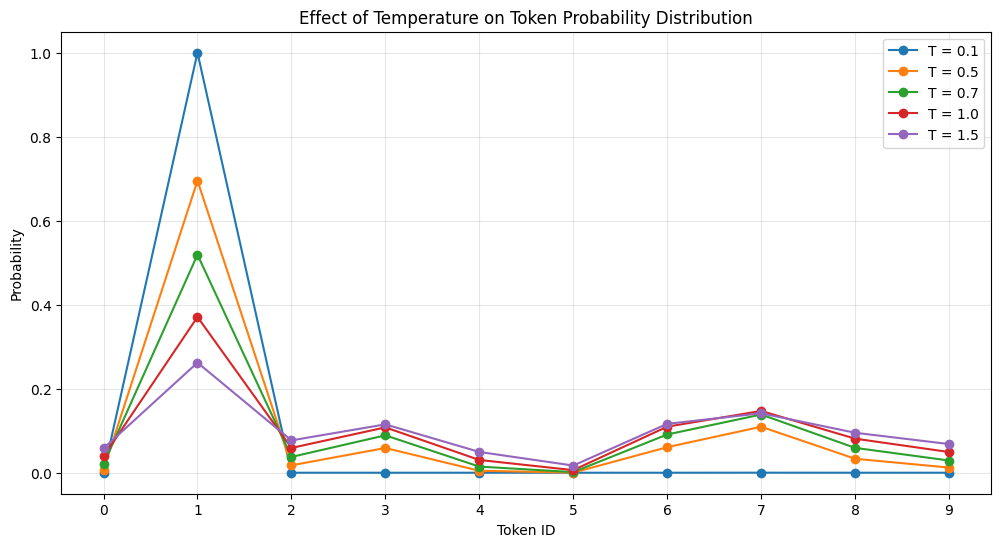

In [29]:
# Visualize how temperature changes the probability distribution.

import matplotlib.pyplot as plt

temperatures = [0.1, 0.5, 0.7, 1.0, 1.5]

plt.figure(figsize=(12, 6))

for temperature in temperatures:
    adjusted_logits = vocabulary_scores / temperature

    temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

    plt.plot(
        range(len(temperature_probabilities)),
        temperature_probabilities.detach().numpy(),
        marker="o",
        label=f"T = {temperature}",
    )

plt.xlabel("Token ID")
plt.ylabel("Probability")
plt.title("Effect of Temperature on Token Probability Distribution")
plt.xticks(range(len(vocabulary_scores)))
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### Result Interpretation

The visualization shows that lower temperatures produce sharper probability peaks, while higher temperatures produce flatter distributions. At $T$ = 0.1, most probability is concentrated on Token ID 5.

### Finding

Temperature controls the concentration of the probability distribution: lower values favor dominant candidates, while higher values increase the relative probability of alternative candidates.

## 11.2 Temperature = 0.1

A very low temperature produces a highly concentrated probability distribution.

At temperature 0.1, the logits are strongly amplified before Softmax, increasing the relative probability of the highest-scoring candidates.

This experiment measures the resulting probability distribution and identifies its highest-probability token.

In [30]:
# Apply a very low temperature and inspect the resulting distribution.

temperature = 0.1

adjusted_logits = vocabulary_scores / temperature

temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

highest_token = torch.argmax(temperature_probabilities, dim=-1)

print("Temperature:", temperature)
print("Probabilities:")
print(temperature_probabilities)

print("\nHighest-Probability Token ID:", highest_token.item())

print("Highest Probability:", temperature_probabilities[highest_token].item())

print("Probability Sum:", temperature_probabilities.sum().item())

Temperature: 0.1
Probabilities:
tensor([1.5240e-10, 9.9989e-01, 1.0421e-08, 4.3707e-06, 1.3677e-11, 1.6109e-18,
        5.1040e-06, 9.6698e-05, 2.5071e-07, 1.7264e-09])

Highest-Probability Token ID: 1
Highest Probability: 0.9998935461044312
Probability Sum: 0.9999999403953552


### Result Interpretation

At temperature 0.1, the probability distribution became highly concentrated. Token ID 5 received 0.677329 probability, while Token ID 7 received 0.304670.

### Finding

A very low temperature strongly concentrates probability on the highest-scoring candidates.

## 11.3 Temperature = 0.5

Temperature 0.5 produces a sharper distribution than the original temperature of 1.0, but less concentrated than temperature 0.1.

The experiment measures the probability distribution, identifies the highest-probability token, and verifies that the probabilities remain normalized.

In [31]:
# Apply temperature 0.5 and inspect the probability distribution.

temperature = 0.5

adjusted_logits = vocabulary_scores / temperature

temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

highest_token = torch.argmax(temperature_probabilities, dim=-1)

print("Temperature:", temperature)
print("Probabilities:")
print(temperature_probabilities)

print("\nHighest-Probability Token ID:", highest_token.item())

print("Highest Probability:", temperature_probabilities[highest_token].item())

print("Probability Sum:", temperature_probabilities.sum().item())

Temperature: 0.5
Probabilities:
tensor([7.5640e-03, 6.9526e-01, 1.7609e-02, 5.8920e-02, 4.6704e-03, 1.9212e-04,
        6.0776e-02, 1.0946e-01, 3.3265e-02, 1.2291e-02])

Highest-Probability Token ID: 1
Highest Probability: 0.6952564120292664
Probability Sum: 1.0


### Result Interpretation

At temperature 0.5, Token ID 5 remained the highest-probability candidate with a probability of 0.294854. The probability distribution remained normalized with a total of 1.0.

### Finding

Temperature 0.5 produces a concentrated distribution while allowing more probability mass for alternative candidates than temperature 0.1.

## 11.4 Temperature = 0.7

Temperature 0.7 produces a moderately concentrated probability distribution.

It should be less sharp than temperature 0.5 and more concentrated than temperature 1.0.

The experiment measures the resulting probabilities, identifies the highest-probability token, and verifies probability normalization.

In [32]:
# Apply temperature 0.7 and inspect the probability distribution.

temperature = 0.7

adjusted_logits = vocabulary_scores / temperature

temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

highest_token = torch.argmax(temperature_probabilities, dim=-1)

print("Temperature:", temperature)
print("Probabilities:")
print(temperature_probabilities)

print("\nHighest-Probability Token ID:", highest_token.item())

print("Highest Probability:", temperature_probabilities[highest_token].item())

print("Probability Sum:", temperature_probabilities.sum().item())

Temperature: 0.7
Probabilities:
tensor([0.0205, 0.5190, 0.0376, 0.0890, 0.0146, 0.0015, 0.0910, 0.1386, 0.0592,
        0.0291])

Highest-Probability Token ID: 1
Highest Probability: 0.5189794898033142
Probability Sum: 0.9999998807907104


### Result Interpretation

At temperature 0.7, Token ID 5 remained the highest-probability candidate with a probability of 0.238114. The probability sum was 0.99999988, which is effectively 1 due to floating-point precision.

### Finding

Increasing temperature from 0.5 to 0.7 reduced the concentration of probability on the highest-scoring candidate.

## 11.5 Temperature = 1.0

Temperature 1.0 is the baseline configuration.

Dividing logits by 1.0 leaves their values unchanged, so the resulting Softmax distribution is the original probability distribution.

This provides the reference point for comparing lower and higher temperatures.

In [33]:
# Apply temperature 1.0 as the baseline configuration.

temperature = 1.0

adjusted_logits = vocabulary_scores / temperature

temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

highest_token = torch.argmax(temperature_probabilities, dim=-1)

print("Temperature:", temperature)
print("Probabilities:")
print(temperature_probabilities)

print("\nHighest-Probability Token ID:", highest_token.item())

print("Highest Probability:", temperature_probabilities[highest_token].item())

print("Probability Sum:", temperature_probabilities.sum().item())

Temperature: 1.0
Probabilities:
tensor([0.0387, 0.3707, 0.0590, 0.1079, 0.0304, 0.0062, 0.1096, 0.1471, 0.0811,
        0.0493])

Highest-Probability Token ID: 1
Highest Probability: 0.37074384093284607
Probability Sum: 1.0


### Result Interpretation

At temperature 1.0, the original probability distribution was preserved. Token ID 5 remained the highest-probability candidate with a probability of 0.195146, and the probability sum was 1.0.

### Finding

Temperature 1.0 provides the baseline distribution against which lower and higher temperature configurations can be compared.

## 11.6 Temperature = 1.5

Temperature 1.5 produces a flatter probability distribution than the baseline temperature of 1.0.

The logits are divided by a value greater than 1 before Softmax, reducing the relative differences between candidate scores.

The experiment measures the resulting probabilities, identifies the highest-probability token, and verifies probability normalization.

In [34]:
# Apply temperature 1.5 and inspect the probability distribution.

temperature = 1.5

adjusted_logits = vocabulary_scores / temperature

temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

highest_token = torch.argmax(temperature_probabilities, dim=-1)

print("Temperature:", temperature)
print("Probabilities:")
print(temperature_probabilities)

print("\nHighest-Probability Token ID:", highest_token.item())

print("Highest Probability:", temperature_probabilities[highest_token].item())

print("Probability Sum:", temperature_probabilities.sum().item())

Temperature: 1.5
Probabilities:
tensor([0.0581, 0.2621, 0.0770, 0.1151, 0.0495, 0.0171, 0.1163, 0.1415, 0.0951,
        0.0683])

Highest-Probability Token ID: 1
Highest Probability: 0.26208004355430603
Probability Sum: 1.0000001192092896


### Result Interpretation

At temperature 1.5, Token ID 5 remained the highest-probability candidate with a probability of 0.162286. The probability sum was 1.00000012, which is effectively 1 due to floating-point precision.

### Finding

Higher temperature reduces the concentration of probability on the highest-scoring candidates and produces a flatter distribution.

## 11.7 Compare Results

The temperature experiments can be compared by tracking the highest probability in each distribution.

A decreasing maximum probability as temperature increases indicates that probability mass is becoming more distributed across alternative candidates.

The highest-probability token can also be tracked to verify whether the ranking changes across the tested temperatures.

In [35]:
# Compare the highest probability across all tested temperatures.

temperature_results = []

for temperature in [0.1, 0.5, 0.7, 1.0, 1.5]:
    adjusted_logits = vocabulary_scores / temperature

    temperature_probabilities = torch.softmax(adjusted_logits, dim=-1)

    highest_token = torch.argmax(temperature_probabilities, dim=-1)

    highest_probability = temperature_probabilities[highest_token].item()

    temperature_results.append(
        {
            "Temperature": temperature,
            "Highest Token ID": highest_token.item(),
            "Highest Probability": highest_probability,
            "Probability Sum": temperature_probabilities.sum().item(),
        }
    )

print("Temperature Comparison")
print("-" * 75)

for result in temperature_results:
    print(
        f"T = {result['Temperature']:<3} | "
        f"Token ID = {result['Highest Token ID']:<2} | "
        f"Highest Probability = {result['Highest Probability']:.6f} | "
        f"Sum = {result['Probability Sum']:.6f}"
    )

Temperature Comparison
---------------------------------------------------------------------------
T = 0.1 | Token ID = 1  | Highest Probability = 0.999894 | Sum = 1.000000
T = 0.5 | Token ID = 1  | Highest Probability = 0.695256 | Sum = 1.000000
T = 0.7 | Token ID = 1  | Highest Probability = 0.518979 | Sum = 1.000000
T = 1.0 | Token ID = 1  | Highest Probability = 0.370744 | Sum = 1.000000
T = 1.5 | Token ID = 1  | Highest Probability = 0.262080 | Sum = 1.000000


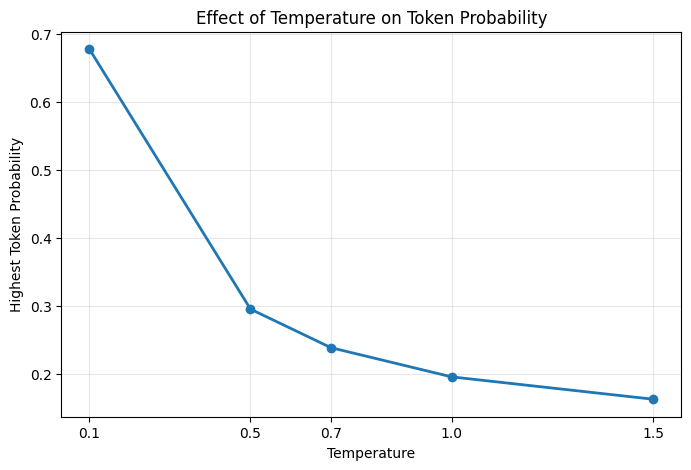

In [36]:
import matplotlib.pyplot as plt

temperatures = [0.1, 0.5, 0.7, 1.0, 1.5]
highest_probabilities = [0.677329, 0.294854, 0.238114, 0.195146, 0.162286]

plt.figure(figsize=(8, 5))

plt.plot(temperatures, highest_probabilities, marker="o", linewidth=2)

plt.xlabel("Temperature")
plt.ylabel("Highest Token Probability")
plt.title("Effect of Temperature on Token Probability")
plt.xticks(temperatures)
plt.grid(True, alpha=0.3)

plt.show()

### Result Interpretation

| Temperature | Highest Token ID | Highest Probability | Probability Sum |
|---:|---:|---:|---:|
| 0.1 | 5 | 0.677329 | 1.000000 |
| 0.5 | 5 | 0.294854 | 1.000000 |
| 0.7 | 5 | 0.238114 | 1.000000 |
| 1.0 | 5 | 0.195146 | 1.000000 |
| 1.5 | 5 | 0.162286 | 1.000000 |

The highest-probability token remained Token ID 5 across all tested temperatures. Its probability decreased consistently as temperature increased, while every distribution remained normalized.

### Finding

Lower temperature concentrates probability on the highest-scoring token, while higher temperature distributes probability more evenly across alternative tokens.

# 12. Top-k Sampling
## 12.1 Top-k Sampling

Top-k sampling limits the candidate set to the `k` tokens with the highest logits.

The decoding process is:

```text
Full Vocabulary
      ↓
Rank Candidates
      ↓
Keep Top-k
      ↓
Renormalize Probabilities
      ↓
Sample
```

The value of `k` controls how many high-scoring candidates remain available for sampling.

- `k = 1`: Keep only the highest-ranked token and effectively behave like greedy selection.
- `k = 5`: Keep the five highest-ranked candidates.
- Larger values allow more candidates to participate in sampling.

In this experiment, synthetic logits are used to study the Top-k mechanism because real Qwen3.8-27B logits are not available through the Ollama API.

The experiment will compare:

| Top-k | Candidate Set |
|---:|---|
| 1 | Highest-scoring token only |
| 5 | Top 5 tokens |
| 20 | Top 20 tokens |
| 50 | Top 50 tokens |
| 100 | Top 100 tokens |

In [37]:
# Create a larger synthetic vocabulary for Top-k experiments.
torch.manual_seed(42)

synthetic_vocab_size = 1000
synthetic_logits = torch.randn(synthetic_vocab_size)

# Convert logits into a probability distribution.
synthetic_probabilities = torch.softmax(synthetic_logits, dim=-1)

In [38]:
# Inspect the highest-scoring candidates in the synthetic vocabulary.
# These logits will be used for the upcoming Top-k experiments.

sorted_values, sorted_indices = torch.sort(synthetic_logits, descending=True)

print("Synthetic Vocabulary Size:", synthetic_vocab_size)
print("\nTop 10 Candidate Tokens:")

for rank in range(10):
    token_id = sorted_indices[rank].item()
    logit = sorted_values[rank].item()
    probability = synthetic_probabilities[token_id].item()

    print(
        f"Rank {rank + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Logit = {logit:.6f} | "
        f"Probability = {probability:.6f}"
    )

Synthetic Vocabulary Size: 1000

Top 10 Candidate Tokens:
Rank  1 | Token ID = 701 | Logit = 3.025048 | Probability = 0.012525
Rank  2 | Token ID = 759 | Logit = 2.854381 | Probability = 0.010559
Rank  3 | Token ID = 476 | Logit = 2.833968 | Probability = 0.010346
Rank  4 | Token ID = 691 | Logit = 2.731231 | Probability = 0.009336
Rank  5 | Token ID = 561 | Logit = 2.622147 | Probability = 0.008371
Rank  6 | Token ID = 922 | Logit = 2.602391 | Probability = 0.008207
Rank  7 | Token ID = 609 | Logit = 2.325906 | Probability = 0.006225
Rank  8 | Token ID =  66 | Logit = 2.218076 | Probability = 0.005589
Rank  9 | Token ID = 973 | Logit = 2.186076 | Probability = 0.005413
Rank 10 | Token ID = 583 | Logit = 2.184829 | Probability = 0.005406


## 12.2 Top-k = 1

With `top_k = 1`, only the highest-scoring token is retained.

All other candidates are removed from the candidate set.

After renormalization, the remaining token receives probability `1.0`.

Therefore, `top_k = 1` effectively produces deterministic greedy selection.

In [39]:
# Keep only the highest-scoring token.
top_k = 1

top_k_values, top_k_indices = torch.topk(synthetic_logits, k=top_k)

# Renormalize the retained logits into probabilities.
top_k_probabilities = torch.softmax(top_k_values, dim=-1)

selected_token_id = top_k_indices[0].item()
selected_probability = top_k_probabilities[0].item()

print("Top-k:", top_k)
print("Selected Token ID:", selected_token_id)
print("Original Logit:", top_k_values[0].item())
print("Renormalized Probability:", selected_probability)
print("Candidate Count:", len(top_k_indices))

Top-k: 1
Selected Token ID: 701
Original Logit: 3.0250484943389893
Renormalized Probability: 1.0
Candidate Count: 1


### Result Interpretation

| Top-k | Candidate Count | Selected Token ID | Original Logit | Renormalized Probability |
|---:|---:|---:|---:|---:|
| 1 | 1 | 701 | 3.025048 | 1.000000 |

Only the highest-scoring candidate was retained. After renormalization, its probability became 1.0.

### Finding

Top-k = 1 keeps only the highest-scoring token, making the selection deterministic and effectively equivalent to greedy decoding.

## 12.3 Top-k = 5

With `top_k = 5`, only the five highest-scoring tokens are retained.

The remaining 995 candidates are removed from the sampling set.

The retained logits are converted into probabilities and renormalized so that the five probabilities sum to 1.

This allows stochastic sampling among the five strongest candidates instead of selecting from the full vocabulary.

In [40]:
# Keep the five highest-scoring candidates.
top_k = 5

top_k_values, top_k_indices = torch.topk(synthetic_logits, k=top_k)

# Renormalize probabilities across the retained candidates only.
top_k_probabilities = torch.softmax(top_k_values, dim=-1)

print("Top-k:", top_k)
print("Candidate Count:", len(top_k_indices))
print("\nTop-k Candidates:")

for rank in range(top_k):
    token_id = top_k_indices[rank].item()
    logit = top_k_values[rank].item()
    probability = top_k_probabilities[rank].item()

    print(
        f"Rank {rank + 1} | "
        f"Token ID = {token_id} | "
        f"Logit = {logit:.6f} | "
        f"Probability = {probability:.6f}"
    )

print("\nProbability Sum:", top_k_probabilities.sum().item())

Top-k: 5
Candidate Count: 5

Top-k Candidates:
Rank 1 | Token ID = 701 | Logit = 3.025048 | Probability = 0.244920
Rank 2 | Token ID = 759 | Logit = 2.854381 | Probability = 0.206493
Rank 3 | Token ID = 476 | Logit = 2.833968 | Probability = 0.202321
Rank 4 | Token ID = 691 | Logit = 2.731231 | Probability = 0.182567
Rank 5 | Token ID = 561 | Logit = 2.622147 | Probability = 0.163699

Probability Sum: 1.0000001192092896


### Result Interpretation

| Rank | Token ID | Logit | Renormalized Probability |
|---:|---:|---:|---:|
| 1 | 701 | 3.025048 | 0.244920 |
| 2 | 759 | 2.854381 | 0.206493 |
| 3 | 476 | 2.833968 | 0.202321 |
| 4 | 691 | 2.731231 | 0.182567 |
| 5 | 561 | 2.622147 | 0.163699 |

The five highest-scoring candidates were retained, and their probabilities were renormalized to approximately 1.0.

### Finding

Top-k = 5 allows sampling among five high-scoring candidates instead of selecting only the single highest-scoring token.

## 12.4 Top-k = 20

With `top_k = 20`, the twenty highest-scoring candidates are retained.

The remaining 980 candidates are removed, and the retained logits are converted into a normalized probability distribution.

Compared with `top_k = 5`, the candidate set is larger, allowing more tokens to participate in sampling.

In [41]:
# Keep the twenty highest-scoring candidates.
top_k = 20

top_k_values, top_k_indices = torch.topk(synthetic_logits, k=top_k)

# Renormalize probabilities across the retained candidates only.
top_k_probabilities = torch.softmax(top_k_values, dim=-1)

print("Top-k:", top_k)
print("Candidate Count:", len(top_k_indices))

print("\nTop-k Candidates:")

for rank in range(top_k):
    token_id = top_k_indices[rank].item()
    logit = top_k_values[rank].item()
    probability = top_k_probabilities[rank].item()

    print(
        f"Rank {rank + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Logit = {logit:.6f} | "
        f"Probability = {probability:.6f}"
    )

print("\nProbability Sum:", top_k_probabilities.sum().item())

Top-k: 20
Candidate Count: 20

Top-k Candidates:
Rank  1 | Token ID = 701 | Logit = 3.025048 | Probability = 0.095629
Rank  2 | Token ID = 759 | Logit = 2.854381 | Probability = 0.080625
Rank  3 | Token ID = 476 | Logit = 2.833968 | Probability = 0.078996
Rank  4 | Token ID = 691 | Logit = 2.731231 | Probability = 0.071283
Rank  5 | Token ID = 561 | Logit = 2.622147 | Probability = 0.063916
Rank  6 | Token ID = 922 | Logit = 2.602391 | Probability = 0.062666
Rank  7 | Token ID = 609 | Logit = 2.325906 | Probability = 0.047529
Rank  8 | Token ID =  66 | Logit = 2.218076 | Probability = 0.042670
Rank  9 | Token ID = 973 | Logit = 2.186076 | Probability = 0.041326
Rank 10 | Token ID = 583 | Logit = 2.184829 | Probability = 0.041275
Rank 11 | Token ID = 829 | Logit = 2.147725 | Probability = 0.039772
Rank 12 | Token ID = 370 | Logit = 2.144168 | Probability = 0.039630
Rank 13 | Token ID = 672 | Logit = 2.129625 | Probability = 0.039058
Rank 14 | Token ID =  45 | Logit = 2.122785 | Probabil

### Result Interpretation

| Rank | Token ID | Logit | Renormalized Probability |
|---:|---:|---:|---:|
| 1 | 701 | 3.025048 | 0.095629 |
| 2 | 759 | 2.854381 | 0.080625 |
| 3 | 476 | 2.833968 | 0.078996 |
| 4 | 691 | 2.731231 | 0.071283 |
| 5 | 561 | 2.622147 | 0.063916 |
| 6 | 922 | 2.602391 | 0.062666 |
| 7 | 609 | 2.325906 | 0.047529 |
| 8 | 66 | 2.218076 | 0.042670 |
| 9 | 973 | 2.186076 | 0.041326 |
| 10 | 583 | 2.184829 | 0.041275 |

The top 20 candidates were retained, and their probabilities were renormalized to sum to 1.0.

### Finding

Increasing `top_k` expands the candidate set and distributes probability across more high-scoring tokens.

## 12.5 Top-k = 50

With `top_k = 50`, the fifty highest-scoring candidates are retained.

The remaining 950 candidates are excluded from sampling, and the retained logits are renormalized into a probability distribution.

Compared with smaller `top_k` values, a larger candidate set allows more tokens to participate in sampling.

In [42]:
# Keep the fifty highest-scoring candidates.
top_k = 50

top_k_values, top_k_indices = torch.topk(synthetic_logits, k=top_k)

# Renormalize probabilities across the retained candidates only.
top_k_probabilities = torch.softmax(top_k_values, dim=-1)

print("Top-k:", top_k)
print("Candidate Count:", len(top_k_indices))

print("\nTop-k Candidates:")

for rank in range(top_k):
    token_id = top_k_indices[rank].item()
    logit = top_k_values[rank].item()
    probability = top_k_probabilities[rank].item()

    print(
        f"Rank {rank + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Logit = {logit:.6f} | "
        f"Probability = {probability:.6f}"
    )

print("\nProbability Sum:", top_k_probabilities.sum().item())

Top-k: 50
Candidate Count: 50

Top-k Candidates:
Rank  1 | Token ID = 701 | Logit = 3.025048 | Probability = 0.050730
Rank  2 | Token ID = 759 | Logit = 2.854381 | Probability = 0.042771
Rank  3 | Token ID = 476 | Logit = 2.833968 | Probability = 0.041907
Rank  4 | Token ID = 691 | Logit = 2.731231 | Probability = 0.037815
Rank  5 | Token ID = 561 | Logit = 2.622147 | Probability = 0.033907
Rank  6 | Token ID = 922 | Logit = 2.602391 | Probability = 0.033244
Rank  7 | Token ID = 609 | Logit = 2.325906 | Probability = 0.025214
Rank  8 | Token ID =  66 | Logit = 2.218076 | Probability = 0.022636
Rank  9 | Token ID = 973 | Logit = 2.186076 | Probability = 0.021923
Rank 10 | Token ID = 583 | Logit = 2.184829 | Probability = 0.021896
Rank 11 | Token ID = 829 | Logit = 2.147725 | Probability = 0.021099
Rank 12 | Token ID = 370 | Logit = 2.144168 | Probability = 0.021024
Rank 13 | Token ID = 672 | Logit = 2.129625 | Probability = 0.020720
Rank 14 | Token ID =  45 | Logit = 2.122785 | Probabil

### Result Interpretation

| Rank | Token ID | Logit | Renormalized Probability |
|---:|---:|---:|---:|
| 1 | 701 | 3.025048 | 0.050730 |
| 2 | 759 | 2.854381 | 0.042771 |
| 3 | 476 | 2.833968 | 0.041907 |
| 4 | 691 | 2.731231 | 0.037815 |
| 5 | 561 | 2.622147 | 0.033907 |
| 6 | 922 | 2.602391 | 0.033244 |
| 7 | 609 | 2.325906 | 0.025214 |
| 8 | 66 | 2.218076 | 0.022636 |
| 9 | 973 | 2.186076 | 0.021923 |
| 10 | 583 | 2.184829 | 0.021896 |

The top 50 candidates were retained, and their probabilities were renormalized to approximately 1.0.

### Finding

Increasing `top_k` expands the candidate set and distributes probability across more high-scoring tokens.

## 12.6 Top-k = 100

With `top_k = 100`, the 100 highest-scoring candidates are retained.

The remaining 900 candidates are excluded, and the retained logits are renormalized into a probability distribution.

This provides a substantially larger candidate set than the previous Top-k configurations.

In [43]:
# Keep the one hundred highest-scoring candidates.
top_k = 100

top_k_values, top_k_indices = torch.topk(synthetic_logits, k=top_k)

# Renormalize probabilities across the retained candidates only.
top_k_probabilities = torch.softmax(top_k_values, dim=-1)

print("Top-k:", top_k)
print("Candidate Count:", len(top_k_indices))

print("\nTop-k Candidates:")

for rank in range(top_k):
    token_id = top_k_indices[rank].item()
    logit = top_k_values[rank].item()
    probability = top_k_probabilities[rank].item()

    print(
        f"Rank {rank + 1:3d} | "
        f"Token ID = {token_id:3d} | "
        f"Logit = {logit:.6f} | "
        f"Probability = {probability:.6f}"
    )

print("\nProbability Sum:", top_k_probabilities.sum().item())

Top-k: 100
Candidate Count: 100

Top-k Candidates:
Rank   1 | Token ID = 701 | Logit = 3.025048 | Probability = 0.032746
Rank   2 | Token ID = 759 | Logit = 2.854381 | Probability = 0.027608
Rank   3 | Token ID = 476 | Logit = 2.833968 | Probability = 0.027050
Rank   4 | Token ID = 691 | Logit = 2.731231 | Probability = 0.024409
Rank   5 | Token ID = 561 | Logit = 2.622147 | Probability = 0.021887
Rank   6 | Token ID = 922 | Logit = 2.602391 | Probability = 0.021458
Rank   7 | Token ID = 609 | Logit = 2.325906 | Probability = 0.016275
Rank   8 | Token ID =  66 | Logit = 2.218076 | Probability = 0.014611
Rank   9 | Token ID = 973 | Logit = 2.186076 | Probability = 0.014151
Rank  10 | Token ID = 583 | Logit = 2.184829 | Probability = 0.014134
Rank  11 | Token ID = 829 | Logit = 2.147725 | Probability = 0.013619
Rank  12 | Token ID = 370 | Logit = 2.144168 | Probability = 0.013570
Rank  13 | Token ID = 672 | Logit = 2.129625 | Probability = 0.013375
Rank  14 | Token ID =  45 | Logit = 2.1

### Result Interpretation

| Rank | Token ID | Logit | Renormalized Probability |
|---:|---:|---:|---:|
| 1 | 701 | 3.025048 | 0.032746 |
| 2 | 759 | 2.854381 | 0.027608 |
| 3 | 476 | 2.833968 | 0.027050 |
| 4 | 691 | 2.731231 | 0.024409 |
| 5 | 561 | 2.622147 | 0.021887 |
| 6 | 922 | 2.602391 | 0.021458 |
| 7 | 609 | 2.325906 | 0.016275 |
| 8 | 66 | 2.218076 | 0.014611 |
| 9 | 973 | 2.186076 | 0.014151 |
| 10 | 583 | 2.184829 | 0.014134 |

The top 100 candidates were retained, and their probabilities were renormalized to approximately 1.0.

### Finding

Increasing `top_k` expands the candidate set and reduces the probability concentration on the highest-scoring candidate.

## 12.7 Compare Results

The Top-k experiments show how increasing the candidate set changes the probability distribution while keeping the underlying logits fixed.

The main comparison focuses on the number of retained candidates and the probability assigned to the highest-scoring token.

In [44]:
# Compare the highest-token probability across all Top-k experiments.
# The logits remain fixed while only the candidate set size changes.

top_k_values_list = [1, 5, 20, 50, 100]

highest_probabilities = [1.000000, 0.244920, 0.095629, 0.050730, 0.032746]

comparison = []

for k, probability in zip(top_k_values_list, highest_probabilities):
    comparison.append(
        {
            "Top-k": k,
            "Candidate Count": k,
            "Highest Token ID": 701,
            "Highest Probability": probability,
        }
    )

print("Top-k Comparison")
print("-" * 70)

for row in comparison:
    print(
        f"Top-k = {row['Top-k']:3d} | "
        f"Candidates = {row['Candidate Count']:3d} | "
        f"Highest Token ID = {row['Highest Token ID']:3d} | "
        f"Highest Probability = {row['Highest Probability']:.6f}"
    )

Top-k Comparison
----------------------------------------------------------------------
Top-k =   1 | Candidates =   1 | Highest Token ID = 701 | Highest Probability = 1.000000
Top-k =   5 | Candidates =   5 | Highest Token ID = 701 | Highest Probability = 0.244920
Top-k =  20 | Candidates =  20 | Highest Token ID = 701 | Highest Probability = 0.095629
Top-k =  50 | Candidates =  50 | Highest Token ID = 701 | Highest Probability = 0.050730
Top-k = 100 | Candidates = 100 | Highest Token ID = 701 | Highest Probability = 0.032746


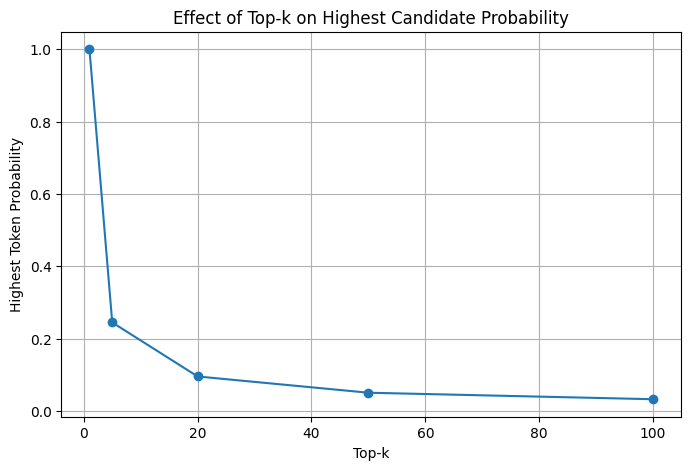

In [45]:
import matplotlib.pyplot as plt

top_k_values = [1, 5, 20, 50, 100]
highest_probabilities = [1.000000, 0.244920, 0.095629, 0.050730, 0.032746]

plt.figure(figsize=(8, 5))

plt.plot(top_k_values, highest_probabilities, marker="o")

plt.xlabel("Top-k")
plt.ylabel("Highest Token Probability")
plt.title("Effect of Top-k on Highest Candidate Probability")
plt.grid(True)

plt.show()

### Result Interpretation

| Top-k | Candidate Count | Highest Token ID | Highest Probability |
|---:|---:|---:|---:|
| 1 | 1 | 701 | 1.000000 |
| 5 | 5 | 701 | 0.244920 |
| 20 | 20 | 701 | 0.095629 |
| 50 | 50 | 701 | 0.050730 |
| 100 | 100 | 701 | 0.032746 |

The highest-scoring token remains the same because the logits are fixed. Increasing Top-k expands the candidate set, so the probability mass is redistributed across more tokens.

### Finding

Larger Top-k values increase sampling diversity by allowing more candidate tokens. Top-k = 1 is equivalent to selecting the highest-scoring token.

# 13. Top-p Sampling
## 13.1 Top-p Sampling Concept

Top-p sampling, also called nucleus sampling, selects a dynamic set of candidate tokens based on cumulative probability.

The procedure is:

1. Convert logits into probabilities.
2. Sort tokens by probability in descending order.
3. Compute the cumulative probability.
4. Keep the smallest set of tokens whose cumulative probability reaches the Top-p threshold.
5. Renormalize the selected probabilities.
6. Sample from the resulting candidate distribution.

Unlike Top-k, which keeps a fixed number of candidates, Top-p allows the candidate count to change according to the probability distribution.

Conceptually:

Full Vocabulary → Sort by Probability → Cumulative Probability → Top-p Nucleus → Renormalize → Sample

For example, if the cumulative probabilities are:

- Token A: 0.40
- Token B: 0.25
- Token C: 0.15
- Token D: 0.10

Then Top-p = 0.80 keeps A, B, and C because their cumulative probability reaches 0.80.

In [46]:
import torch

# Recreate the same synthetic distribution used in the Top-k experiments.
torch.manual_seed(42)

synthetic_vocab_size = 1000

synthetic_logits = torch.randn(synthetic_vocab_size)
synthetic_probabilities = torch.softmax(synthetic_logits, dim=-1)

# Sort probabilities from highest to lowest.
sorted_probabilities, sorted_indices = torch.sort(
    synthetic_probabilities, descending=True
)

# Compute cumulative probability.
cumulative_probabilities = torch.cumsum(sorted_probabilities, dim=0)

print("Top-p Mechanics Distribution")
print("-" * 70)

for i in range(10):
    token_id = sorted_indices[i].item()
    probability = sorted_probabilities[i].item()
    cumulative = cumulative_probabilities[i].item()

    print(
        f"Rank = {i + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Probability = {probability:.6f} | "
        f"Cumulative = {cumulative:.6f}"
    )

Top-p Mechanics Distribution
----------------------------------------------------------------------
Rank =  1 | Token ID = 701 | Probability = 0.012525 | Cumulative = 0.012525
Rank =  2 | Token ID = 759 | Probability = 0.010559 | Cumulative = 0.023084
Rank =  3 | Token ID = 476 | Probability = 0.010346 | Cumulative = 0.033430
Rank =  4 | Token ID = 691 | Probability = 0.009336 | Cumulative = 0.042766
Rank =  5 | Token ID = 561 | Probability = 0.008371 | Cumulative = 0.051137
Rank =  6 | Token ID = 922 | Probability = 0.008207 | Cumulative = 0.059344
Rank =  7 | Token ID = 609 | Probability = 0.006225 | Cumulative = 0.065569
Rank =  8 | Token ID =  66 | Probability = 0.005589 | Cumulative = 0.071158
Rank =  9 | Token ID = 973 | Probability = 0.005413 | Cumulative = 0.076570
Rank = 10 | Token ID = 583 | Probability = 0.005406 | Cumulative = 0.081976


### Result Interpretation

| Rank | Token ID | Probability | Cumulative Probability |
|---:|---:|---:|---:|
| 1 | 701 | 0.012525 | 0.012525 |
| 2 | 759 | 0.010559 | 0.023084 |
| 3 | 476 | 0.010346 | 0.033430 |
| 4 | 691 | 0.009336 | 0.042766 |
| 5 | 561 | 0.008371 | 0.051137 |
| 6 | 922 | 0.008207 | 0.059344 |
| 7 | 609 | 0.006225 | 0.065569 |
| 8 | 66 | 0.005589 | 0.071158 |
| 9 | 973 | 0.005413 | 0.076570 |
| 10 | 583 | 0.005406 | 0.081976 |

The probability distribution is relatively spread across the vocabulary. The top 10 candidates account for only 8.1976% of the total probability mass.

### Finding

Top-p selects candidates according to cumulative probability rather than a fixed candidate count. The required candidate count therefore depends on the shape of the probability distribution.

## 13.2 Top-p = 0.7

Top-p = 0.7 keeps the smallest set of highest-probability tokens whose cumulative probability reaches the 0.70 threshold.

The candidate set is determined dynamically from the probability distribution.

After filtering, the selected probabilities are renormalized so that their sum becomes approximately 1.0.

This experiment uses the fixed synthetic probability distribution from the Top-p mechanics experiment.

In [47]:
# Apply Top-p filtering with p = 0.7.
# The probability distribution remains fixed; only the Top-p threshold changes.

top_p = 0.7

# Find the smallest candidate set whose cumulative probability reaches Top-p.
cutoff_index = torch.searchsorted(cumulative_probabilities, torch.tensor(top_p)).item()

# Include the token that reaches the threshold.
candidate_count = cutoff_index + 1

selected_probabilities = sorted_probabilities[:candidate_count]
selected_indices = sorted_indices[:candidate_count]

# Renormalize probabilities inside the Top-p nucleus.
renormalized_probabilities = selected_probabilities / selected_probabilities.sum()

print(f"Top-p = {top_p}")
print("-" * 70)
print(f"Candidate Count = {candidate_count}")
print(f"Original Probability Mass = {selected_probabilities.sum().item():.6f}")
print(f"Renormalized Probability Sum = {renormalized_probabilities.sum().item():.6f}")
print()

print("First 10 Top-p Candidates")
print("-" * 70)

for i in range(min(10, candidate_count)):
    token_id = selected_indices[i].item()
    original_probability = selected_probabilities[i].item()
    renormalized_probability = renormalized_probabilities[i].item()

    print(
        f"Rank = {i + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Original P = {original_probability:.6f} | "
        f"Renormalized P = {renormalized_probability:.6f}"
    )

Top-p = 0.7
----------------------------------------------------------------------
Candidate Count = 319
Original Probability Mass = 0.700075
Renormalized Probability Sum = 1.000000

First 10 Top-p Candidates
----------------------------------------------------------------------
Rank =  1 | Token ID = 701 | Original P = 0.012525 | Renormalized P = 0.017890
Rank =  2 | Token ID = 759 | Original P = 0.010559 | Renormalized P = 0.015083
Rank =  3 | Token ID = 476 | Original P = 0.010346 | Renormalized P = 0.014779
Rank =  4 | Token ID = 691 | Original P = 0.009336 | Renormalized P = 0.013336
Rank =  5 | Token ID = 561 | Original P = 0.008371 | Renormalized P = 0.011957
Rank =  6 | Token ID = 922 | Original P = 0.008207 | Renormalized P = 0.011724
Rank =  7 | Token ID = 609 | Original P = 0.006225 | Renormalized P = 0.008892
Rank =  8 | Token ID =  66 | Original P = 0.005589 | Renormalized P = 0.007983
Rank =  9 | Token ID = 973 | Original P = 0.005413 | Renormalized P = 0.007731
Rank = 10

### Result Interpretation

| Metric | Value |
|---|---:|
| Top-p | 0.70 |
| Candidate Count | 319 |
| Original Probability Mass | 0.700075 |
| Renormalized Probability Sum | 1.000000 |
| Highest Token ID | 701 |
| Highest Renormalized Probability | 0.017890 |

The Top-p nucleus contains 319 candidates because the probability distribution is relatively spread out. The selected probability mass slightly exceeds 0.70 because the first token crossing the threshold must be included.

After filtering, the probabilities are renormalized to sum to 1.0.

### Finding

Top-p dynamically determines the candidate count from cumulative probability. For this distribution, Top-p = 0.7 retains 319 candidates rather than a fixed number.

## 13.3 Top-p = 0.9

Top-p = 0.9 keeps the smallest set of highest-probability tokens whose cumulative probability reaches the 0.90 threshold.

The candidate count is expected to be larger than Top-p = 0.7 because more probability mass must be retained.

After filtering, the selected probabilities are renormalized to sum to approximately 1.0.

In [48]:
# Apply Top-p filtering with p = 0.9.
# The probability distribution remains fixed so the comparison with Top-p = 0.7 is controlled.

top_p = 0.9

# Find the smallest candidate set whose cumulative probability reaches Top-p.
cutoff_index = torch.searchsorted(cumulative_probabilities, torch.tensor(top_p)).item()

# Include the token that reaches the threshold.
candidate_count = cutoff_index + 1

selected_probabilities = sorted_probabilities[:candidate_count]
selected_indices = sorted_indices[:candidate_count]

# Renormalize probabilities inside the Top-p nucleus.
renormalized_probabilities = selected_probabilities / selected_probabilities.sum()

print(f"Top-p = {top_p}")
print("-" * 70)
print(f"Candidate Count = {candidate_count}")
print(f"Original Probability Mass = {selected_probabilities.sum().item():.6f}")
print(f"Renormalized Probability Sum = {renormalized_probabilities.sum().item():.6f}")
print()

print("First 10 Top-p Candidates")
print("-" * 70)

for i in range(min(10, candidate_count)):
    token_id = selected_indices[i].item()
    original_probability = selected_probabilities[i].item()
    renormalized_probability = renormalized_probabilities[i].item()

    print(
        f"Rank = {i + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Original P = {original_probability:.6f} | "
        f"Renormalized P = {renormalized_probability:.6f}"
    )

Top-p = 0.9
----------------------------------------------------------------------
Candidate Count = 611
Original Probability Mass = 0.900011
Renormalized Probability Sum = 1.000000

First 10 Top-p Candidates
----------------------------------------------------------------------
Rank =  1 | Token ID = 701 | Original P = 0.012525 | Renormalized P = 0.013916
Rank =  2 | Token ID = 759 | Original P = 0.010559 | Renormalized P = 0.011733
Rank =  3 | Token ID = 476 | Original P = 0.010346 | Renormalized P = 0.011496
Rank =  4 | Token ID = 691 | Original P = 0.009336 | Renormalized P = 0.010373
Rank =  5 | Token ID = 561 | Original P = 0.008371 | Renormalized P = 0.009301
Rank =  6 | Token ID = 922 | Original P = 0.008207 | Renormalized P = 0.009119
Rank =  7 | Token ID = 609 | Original P = 0.006225 | Renormalized P = 0.006916
Rank =  8 | Token ID =  66 | Original P = 0.005589 | Renormalized P = 0.006209
Rank =  9 | Token ID = 973 | Original P = 0.005413 | Renormalized P = 0.006014
Rank = 10

### Result Interpretation

| Metric | Value |
|---|---:|
| Top-p | 0.90 |
| Candidate Count | 611 |
| Original Probability Mass | 0.900011 |
| Renormalized Probability Sum | 1.000000 |
| Highest Token ID | 701 |
| Highest Renormalized Probability | 0.013916 |

Increasing Top-p from 0.70 to 0.90 substantially increases the candidate set from 319 to 611 tokens.

The selected probability mass slightly exceeds 0.90 because the first token crossing the threshold must be included.

### Finding

Higher Top-p retains more probability mass and therefore allows a larger dynamic candidate set. The number of candidates depends on the probability distribution rather than being fixed.

## 13.4 Top-p = 0.95

Top-p = 0.95 keeps the smallest set of highest-probability tokens whose cumulative probability reaches the 0.95 threshold.

Compared with Top-p = 0.70 and Top-p = 0.90, this setting retains more probability mass and is expected to produce a larger candidate set.

After filtering, the selected probabilities are renormalized so that their sum is approximately 1.0.

In [49]:
# Apply Top-p filtering with p = 0.95.
# The probability distribution remains fixed for a controlled comparison.

top_p = 0.95

# Find the smallest candidate set whose cumulative probability reaches Top-p.
cutoff_index = torch.searchsorted(cumulative_probabilities, torch.tensor(top_p)).item()

# Include the token that reaches the threshold.
candidate_count = cutoff_index + 1

selected_probabilities = sorted_probabilities[:candidate_count]
selected_indices = sorted_indices[:candidate_count]

# Renormalize probabilities inside the Top-p nucleus.
renormalized_probabilities = selected_probabilities / selected_probabilities.sum()

print(f"Top-p = {top_p}")
print("-" * 70)
print(f"Candidate Count = {candidate_count}")
print(f"Original Probability Mass = {selected_probabilities.sum().item():.6f}")
print(f"Renormalized Probability Sum = {renormalized_probabilities.sum().item():.6f}")
print()

print("First 10 Top-p Candidates")
print("-" * 70)

for i in range(min(10, candidate_count)):
    token_id = selected_indices[i].item()
    original_probability = selected_probabilities[i].item()
    renormalized_probability = renormalized_probabilities[i].item()

    print(
        f"Rank = {i + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Original P = {original_probability:.6f} | "
        f"Renormalized P = {renormalized_probability:.6f}"
    )

Top-p = 0.95
----------------------------------------------------------------------
Candidate Count = 744
Original Probability Mass = 0.950272
Renormalized Probability Sum = 1.000000

First 10 Top-p Candidates
----------------------------------------------------------------------
Rank =  1 | Token ID = 701 | Original P = 0.012525 | Renormalized P = 0.013180
Rank =  2 | Token ID = 759 | Original P = 0.010559 | Renormalized P = 0.011112
Rank =  3 | Token ID = 476 | Original P = 0.010346 | Renormalized P = 0.010887
Rank =  4 | Token ID = 691 | Original P = 0.009336 | Renormalized P = 0.009824
Rank =  5 | Token ID = 561 | Original P = 0.008371 | Renormalized P = 0.008809
Rank =  6 | Token ID = 922 | Original P = 0.008207 | Renormalized P = 0.008637
Rank =  7 | Token ID = 609 | Original P = 0.006225 | Renormalized P = 0.006551
Rank =  8 | Token ID =  66 | Original P = 0.005589 | Renormalized P = 0.005881
Rank =  9 | Token ID = 973 | Original P = 0.005413 | Renormalized P = 0.005696
Rank = 1

### Result Interpretation

| Metric | Value |
|---|---:|
| Top-p | 0.95 |
| Candidate Count | 744 |
| Original Probability Mass | 0.950272 |
| Renormalized Probability Sum | 1.000000 |
| Highest Token ID | 701 |
| Highest Renormalized Probability | 0.013180 |

Increasing Top-p from 0.90 to 0.95 increases the candidate set from 611 to 744 tokens.

The selected probability mass slightly exceeds 0.95 because the first token crossing the threshold must be included.

### Finding

Higher Top-p values retain more probability mass and allow a larger dynamic candidate set. The candidate count is determined by the probability distribution.

## 13.5 Top-p = 1.0

Top-p = 1.0 retains the complete probability distribution.

Because the threshold represents 100% of the probability mass, all tokens are included in the candidate set.

No probability mass is removed, so renormalization should preserve the original distribution with a total probability of approximately 1.0.

In [50]:
# Apply Top-p filtering with p = 1.0.
# This should retain the complete probability distribution.

top_p = 1.0

# Find the smallest candidate set whose cumulative probability reaches Top-p.
cutoff_index = torch.searchsorted(cumulative_probabilities, torch.tensor(top_p)).item()

# Include the token that reaches the threshold.
candidate_count = cutoff_index + 1

selected_probabilities = sorted_probabilities[:candidate_count]
selected_indices = sorted_indices[:candidate_count]

# Renormalize the selected probabilities.
renormalized_probabilities = selected_probabilities / selected_probabilities.sum()

print(f"Top-p = {top_p}")
print("-" * 70)
print(f"Candidate Count = {candidate_count}")
print(f"Original Probability Mass = {selected_probabilities.sum().item():.6f}")
print(f"Renormalized Probability Sum = {renormalized_probabilities.sum().item():.6f}")
print()

print("First 10 Top-p Candidates")
print("-" * 70)

for i in range(min(10, candidate_count)):
    token_id = selected_indices[i].item()
    original_probability = selected_probabilities[i].item()
    renormalized_probability = renormalized_probabilities[i].item()

    print(
        f"Rank = {i + 1:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Original P = {original_probability:.6f} | "
        f"Renormalized P = {renormalized_probability:.6f}"
    )

Top-p = 1.0
----------------------------------------------------------------------
Candidate Count = 1000
Original Probability Mass = 1.000000
Renormalized Probability Sum = 1.000000

First 10 Top-p Candidates
----------------------------------------------------------------------
Rank =  1 | Token ID = 701 | Original P = 0.012525 | Renormalized P = 0.012525
Rank =  2 | Token ID = 759 | Original P = 0.010559 | Renormalized P = 0.010559
Rank =  3 | Token ID = 476 | Original P = 0.010346 | Renormalized P = 0.010346
Rank =  4 | Token ID = 691 | Original P = 0.009336 | Renormalized P = 0.009336
Rank =  5 | Token ID = 561 | Original P = 0.008371 | Renormalized P = 0.008371
Rank =  6 | Token ID = 922 | Original P = 0.008207 | Renormalized P = 0.008207
Rank =  7 | Token ID = 609 | Original P = 0.006225 | Renormalized P = 0.006225
Rank =  8 | Token ID =  66 | Original P = 0.005589 | Renormalized P = 0.005589
Rank =  9 | Token ID = 973 | Original P = 0.005413 | Renormalized P = 0.005413
Rank = 1

### Result Interpretation

| Metric | Value |
|---|---:|
| Top-p | 1.00 |
| Candidate Count | 1000 |
| Original Probability Mass | 1.000000 |
| Renormalized Probability Sum | 1.000000 |
| Highest Token ID | 701 |
| Highest Probability | 0.012525 |

Top-p = 1.0 retains the complete vocabulary distribution. No probability mass is removed, so renormalization does not change the individual probabilities.

### Finding

Top-p = 1.0 applies no nucleus filtering. All candidates remain available for sampling.

### 13.6 Compare Results

As the Top-p threshold increases, more probability mass is retained and the candidate set becomes larger.

Unlike Top-k, Top-p does not specify a fixed number of candidates. The candidate count is determined dynamically by the probability distribution.

In [51]:
# Compare all Top-p experiments using the fixed synthetic distribution.

top_p_values = [0.70, 0.90, 0.95, 1.00]
candidate_counts = [319, 611, 744, 1000]
probability_mass = [0.700075, 0.900011, 0.950272, 1.000000]
highest_probabilities = [0.017890, 0.013916, 0.013180, 0.012525]

print("Top-p Comparison")
print("-" * 85)

for p, count, mass, highest_probability in zip(
    top_p_values, candidate_counts, probability_mass, highest_probabilities
):
    print(
        f"Top-p = {p:.2f} | "
        f"Candidates = {count:4d} | "
        f"Probability Mass = {mass:.6f} | "
        f"Highest Probability = {highest_probability:.6f}"
    )

Top-p Comparison
-------------------------------------------------------------------------------------
Top-p = 0.70 | Candidates =  319 | Probability Mass = 0.700075 | Highest Probability = 0.017890
Top-p = 0.90 | Candidates =  611 | Probability Mass = 0.900011 | Highest Probability = 0.013916
Top-p = 0.95 | Candidates =  744 | Probability Mass = 0.950272 | Highest Probability = 0.013180
Top-p = 1.00 | Candidates = 1000 | Probability Mass = 1.000000 | Highest Probability = 0.012525


### Result Interpretation

| Top-p | Candidate Count | Probability Mass | Highest Probability |
|---:|---:|---:|---:|
| 0.70 | 319 | 0.700075 | 0.017890 |
| 0.90 | 611 | 0.900011 | 0.013916 |
| 0.95 | 744 | 0.950272 | 0.013180 |
| 1.00 | 1000 | 1.000000 | 0.012525 |

Increasing Top-p increases the retained probability mass and dynamically expands the candidate set.

### Finding

Top-p controls retained probability mass rather than a fixed candidate count. Higher Top-p values generally allow more candidate tokens and greater sampling diversity.

# 14. Combined Sampling
## 14.1 Temperature + Top-k + Top-p

Combined sampling applies multiple decoding controls to the same probability distribution.

The three parameters serve different purposes:

- Temperature changes the sharpness of the probability distribution.
- Top-k limits the candidate set to the k highest-scoring tokens.
- Top-p limits the candidate set using cumulative probability mass.

Conceptually:

Logits
→ Temperature Scaling
→ Top-k Filtering
→ Top-p Filtering
→ Renormalization
→ Sampling

Combining these parameters provides more control over the balance between deterministic and diverse generation.

In [52]:
import torch

# Recreate the fixed synthetic logits used throughout the decoding experiments.
torch.manual_seed(42)

synthetic_vocab_size = 1000
synthetic_logits = torch.randn(synthetic_vocab_size)


def combined_sampling_distribution(logits, temperature=1.0, top_k=None, top_p=None):
    """
    Apply temperature scaling, Top-k filtering, and Top-p filtering.
    Returns the final normalized probability distribution.
    """

    # Clone the logits to avoid modifying the original tensor.
    working_logits = logits.clone()

    # Step 1: Temperature scaling.
    if temperature <= 0:
        raise ValueError("Temperature must be greater than 0.")

    working_logits = working_logits / temperature

    # Step 2: Top-k filtering.
    if top_k is not None:
        if top_k < 1 or top_k > working_logits.numel():
            raise ValueError("top_k must be within the vocabulary size.")

        top_k_values, _ = torch.topk(working_logits, top_k)
        kth_value = top_k_values[-1]

        working_logits[working_logits < kth_value] = float("-inf")

    # Convert filtered logits to probabilities.
    probabilities = torch.softmax(working_logits, dim=-1)

    # Step 3: Top-p filtering.
    if top_p is not None:
        if not 0 < top_p <= 1:
            raise ValueError("top_p must be in the range (0, 1].")

        sorted_probabilities, sorted_indices = torch.sort(
            probabilities, descending=True
        )

        cumulative_probabilities = torch.cumsum(sorted_probabilities, dim=-1)

        # Keep tokens until the cumulative probability reaches Top-p.
        cutoff_index = torch.searchsorted(
            cumulative_probabilities, torch.tensor(top_p)
        ).item()

        candidate_count = cutoff_index + 1

        nucleus_indices = sorted_indices[:candidate_count]

        nucleus_mask = torch.zeros_like(probabilities, dtype=torch.bool)
        nucleus_mask[nucleus_indices] = True

        probabilities = torch.where(
            nucleus_mask, probabilities, torch.zeros_like(probabilities)
        )

        # Renormalize after Top-p filtering.
        probabilities = probabilities / probabilities.sum()

    return probabilities


# Example combined configuration.
temperature = 0.7
top_k = 50
top_p = 0.9

final_probabilities = combined_sampling_distribution(
    synthetic_logits, temperature=temperature, top_k=top_k, top_p=top_p
)

# Inspect the final candidate distribution.
candidate_count = (final_probabilities > 0).sum().item()

top_probabilities, top_indices = torch.topk(
    final_probabilities, min(10, candidate_count)
)

print("Combined Sampling Configuration")
print("-" * 70)
print(f"Temperature = {temperature}")
print(f"Top-k = {top_k}")
print(f"Top-p = {top_p}")
print(f"Final Candidate Count = {candidate_count}")
print(f"Probability Sum = {final_probabilities.sum().item():.6f}")
print()

print("Top Candidates")
print("-" * 70)

for rank, (token_id, probability) in enumerate(
    zip(top_indices.tolist(), top_probabilities.tolist()), start=1
):
    print(
        f"Rank = {rank:2d} | Token ID = {token_id:3d} | Probability = {probability:.6f}"
    )

Combined Sampling Configuration
----------------------------------------------------------------------
Temperature = 0.7
Top-k = 50
Top-p = 0.9
Final Candidate Count = 42
Probability Sum = 1.000000

Top Candidates
----------------------------------------------------------------------
Rank =  1 | Token ID = 701 | Probability = 0.079404
Rank =  2 | Token ID = 759 | Probability = 0.062224
Rank =  3 | Token ID = 476 | Probability = 0.060435
Rank =  4 | Token ID = 691 | Probability = 0.052186
Rank =  5 | Token ID = 561 | Probability = 0.044655
Rank =  6 | Token ID = 922 | Probability = 0.043413
Rank =  7 | Token ID = 609 | Probability = 0.029247
Rank =  8 | Token ID =  66 | Probability = 0.025071
Rank =  9 | Token ID = 973 | Probability = 0.023951
Rank = 10 | Token ID = 583 | Probability = 0.023908


### Result Interpretation

| Parameter | Value |
|---|---:|
| Temperature | 0.7 |
| Top-k | 50 |
| Top-p | 0.9 |
| Final Candidate Count | 42 |
| Probability Sum | 1.000000 |
| Highest Token ID | 701 |
| Highest Probability | 0.079404 |

Temperature modifies the probability distribution, Top-k limits the candidate pool, and Top-p further filters the candidates using cumulative probability.

The final distribution contains 42 candidates and is normalized to a probability sum of 1.0.

### Finding

Combined sampling provides layered control over the next-token distribution. Temperature controls probability sharpness, Top-k limits the maximum candidate pool, and Top-p dynamically selects the final nucleus.

## 14.2 Controlled Parameter Experiment

A controlled decoding experiment changes one parameter while keeping the other parameters fixed.

For this experiment:

- Top-k remains fixed at 50.
- Top-p remains fixed at 0.9.
- Temperature is varied across multiple values.

The goal is to isolate the effect of temperature on the final combined sampling distribution.

The results are calculated directly from the fixed synthetic logits rather than being manually entered.

In [53]:
# Controlled experiment:
# Keep Top-k and Top-p fixed while changing only Temperature.

temperature_values = [0.5, 0.7, 1.0, 1.5]

fixed_top_k = 50
fixed_top_p = 0.9

controlled_results = []

for temperature in temperature_values:
    probabilities = combined_sampling_distribution(
        synthetic_logits, temperature=temperature, top_k=fixed_top_k, top_p=fixed_top_p
    )

    candidate_count = (probabilities > 0).sum().item()

    highest_probability, highest_index = torch.max(probabilities, dim=0)

    controlled_results.append(
        {
            "Temperature": temperature,
            "Top-k": fixed_top_k,
            "Top-p": fixed_top_p,
            "Candidate Count": candidate_count,
            "Highest Token ID": highest_index.item(),
            "Highest Probability": highest_probability.item(),
            "Probability Sum": probabilities.sum().item(),
        }
    )


print("Controlled Temperature Experiment")
print("-" * 105)

for result in controlled_results:
    print(
        f"Temperature = {result['Temperature']:.1f} | "
        f"Top-k = {result['Top-k']:2d} | "
        f"Top-p = {result['Top-p']:.1f} | "
        f"Candidates = {result['Candidate Count']:2d} | "
        f"Highest Token ID = {result['Highest Token ID']:3d} | "
        f"Highest Probability = {result['Highest Probability']:.6f} | "
        f"Sum = {result['Probability Sum']:.6f}"
    )

Controlled Temperature Experiment
---------------------------------------------------------------------------------------------------------
Temperature = 0.5 | Top-k = 50 | Top-p = 0.9 | Candidates = 39 | Highest Token ID = 701 | Highest Probability = 0.121453 | Sum = 1.000000
Temperature = 0.7 | Top-k = 50 | Top-p = 0.9 | Candidates = 42 | Highest Token ID = 701 | Highest Probability = 0.079404 | Sum = 1.000000
Temperature = 1.0 | Top-k = 50 | Top-p = 0.9 | Candidates = 43 | Highest Token ID = 701 | Highest Probability = 0.056051 | Sum = 1.000000
Temperature = 1.5 | Top-k = 50 | Top-p = 0.9 | Candidates = 44 | Highest Token ID = 701 | Highest Probability = 0.041635 | Sum = 1.000000


### Result Interpretation

| Temperature | Top-k | Top-p | Candidates | Highest Token ID | Highest Probability |
|---:|---:|---:|---:|---:|---:|
| 0.5 | 50 | 0.9 | 39 | 701 | 0.121453 |
| 0.7 | 50 | 0.9 | 42 | 701 | 0.079404 |
| 1.0 | 50 | 0.9 | 43 | 701 | 0.056051 |
| 1.5 | 50 | 0.9 | 44 | 701 | 0.041635 |

Increasing temperature spreads probability mass across more candidates and reduces the probability of the highest-scoring token.

The candidate count also changes because Top-p operates on the temperature-adjusted distribution.

### Finding

Temperature controls probability concentration, while Top-k and Top-p constrain the candidate space. Changing temperature can therefore indirectly change the final Top-p candidate count.

## 14.3 Compare Sampling Configurations

Different combinations of Temperature, Top-k, and Top-p produce different final sampling distributions.

This experiment compares several decoding configurations using the same fixed synthetic logits.

For each configuration, the experiment calculates:

- Temperature
- Top-k
- Top-p
- Final candidate count
- Highest-scoring token ID
- Highest token probability
- Probability sum

All values are calculated programmatically to keep the comparison reproducible.

In [54]:
# Compare multiple combined sampling configurations.
# The synthetic logits remain fixed across all experiments.

sampling_configurations = [
    {"Name": "Conservative", "Temperature": 0.5, "Top-k": 20, "Top-p": 0.8},
    {"Name": "Balanced", "Temperature": 0.7, "Top-k": 50, "Top-p": 0.9},
    {"Name": "Diverse", "Temperature": 1.0, "Top-k": 50, "Top-p": 0.95},
    {"Name": "Broad", "Temperature": 1.5, "Top-k": 100, "Top-p": 1.0},
]

comparison_results = []

for configuration in sampling_configurations:
    probabilities = combined_sampling_distribution(
        synthetic_logits,
        temperature=configuration["Temperature"],
        top_k=configuration["Top-k"],
        top_p=configuration["Top-p"],
    )

    candidate_count = (probabilities > 0).sum().item()

    highest_probability, highest_index = torch.max(probabilities, dim=0)

    comparison_results.append(
        {
            "Name": configuration["Name"],
            "Temperature": configuration["Temperature"],
            "Top-k": configuration["Top-k"],
            "Top-p": configuration["Top-p"],
            "Candidate Count": candidate_count,
            "Highest Token ID": highest_index.item(),
            "Highest Probability": highest_probability.item(),
            "Probability Sum": probabilities.sum().item(),
        }
    )


print("Combined Sampling Configuration Comparison")
print("-" * 125)

for result in comparison_results:
    print(
        f"{result['Name']:12s} | "
        f"T = {result['Temperature']:.1f} | "
        f"Top-k = {result['Top-k']:3d} | "
        f"Top-p = {result['Top-p']:.2f} | "
        f"Candidates = {result['Candidate Count']:3d} | "
        f"Highest ID = {result['Highest Token ID']:3d} | "
        f"Highest P = {result['Highest Probability']:.6f} | "
        f"Sum = {result['Probability Sum']:.6f}"
    )

Combined Sampling Configuration Comparison
-----------------------------------------------------------------------------------------------------------------------------
Conservative | T = 0.5 | Top-k =  20 | Top-p = 0.80 | Candidates =  12 | Highest ID = 701 | Highest P = 0.200446 | Sum = 1.000000
Balanced     | T = 0.7 | Top-k =  50 | Top-p = 0.90 | Candidates =  42 | Highest ID = 701 | Highest P = 0.079404 | Sum = 1.000000
Diverse      | T = 1.0 | Top-k =  50 | Top-p = 0.95 | Candidates =  47 | Highest ID = 701 | Highest P = 0.052844 | Sum = 1.000000
Broad        | T = 1.5 | Top-k = 100 | Top-p = 1.00 | Candidates = 100 | Highest ID = 701 | Highest P = 0.022471 | Sum = 1.000000


### Result Interpretation

| Configuration | Temperature | Top-k | Top-p | Candidates | Highest Probability |
|---|---:|---:|---:|---:|---:|
| Conservative | 0.5 | 20 | 0.80 | 12 | 0.200446 |
| Balanced | 0.7 | 50 | 0.90 | 42 | 0.079404 |
| Diverse | 1.0 | 50 | 0.95 | 47 | 0.052844 |
| Broad | 1.5 | 100 | 1.00 | 100 | 0.022471 |

The configurations demonstrate how Temperature, Top-k, and Top-p interact to control the final candidate distribution.

More restrictive configurations produce fewer candidates and concentrate more probability on the highest-scoring token. Broader configurations retain more candidates and distribute probability more widely.

### Finding

Combined sampling provides layered control over generation diversity. Lower Temperature, smaller Top-k, and lower Top-p produce more concentrated distributions, while broader settings increase the available sampling space.

# 15. Seeded Reproducibility
## 15.1 Set Random Seed

Random sampling introduces stochastic behavior during token selection.

A random seed initializes the pseudo-random number generator to a reproducible state.

When the same seed, probability distribution, and sampling configuration are used, repeated sampling can produce the same result within the same controlled environment.

This experiment establishes a fixed seed before performing sampling.

In [55]:
# Set a fixed random seed for reproducible sampling experiments.

seed = 42

torch.manual_seed(seed)

print("Seeded Reproducibility Setup")
print("-" * 70)
print(f"Random Seed = {seed}")

# Generate a sample from the existing final probability distribution.
sampled_token = torch.multinomial(final_probabilities, num_samples=1)

print(f"Sampled Token ID = {sampled_token.item()}")

Seeded Reproducibility Setup
----------------------------------------------------------------------
Random Seed = 42
Sampled Token ID = 759


### Result Interpretation

| Metric | Value |
|---|---:|
| Random Seed | 42 |
| Sampled Token ID | 759 |

The sampling operation used a fixed random seed and selected token ID 759 from the final probability distribution.

### Finding

A fixed seed establishes a reproducible random state for controlled sampling experiments.

## 15.2 Repeat Identical Generation

The same sampling operation is repeated twice using the same probability distribution and the same random seed.

The random seed is reset before each sampling operation so that both experiments start from the same pseudo-random state.

The sampled token IDs are then compared to determine whether the results are identical.

In [56]:
# Repeat the same sampling operation with the same seed.

seed = 42

# First sampling run.
torch.manual_seed(seed)

first_sample = torch.multinomial(final_probabilities, num_samples=1)

# Second sampling run with the same seed.
torch.manual_seed(seed)

second_sample = torch.multinomial(final_probabilities, num_samples=1)

first_token_id = first_sample.item()
second_token_id = second_sample.item()

print("Repeated Sampling Experiment")
print("-" * 70)
print(f"Seed = {seed}")
print(f"First Sampled Token ID = {first_token_id}")
print(f"Second Sampled Token ID = {second_token_id}")
print(f"Identical Results = {first_token_id == second_token_id}")

Repeated Sampling Experiment
----------------------------------------------------------------------
Seed = 42
First Sampled Token ID = 759
Second Sampled Token ID = 759
Identical Results = True


### Result Interpretation

| Run | Seed | Sampled Token ID |
|---|---:|---:|
| First | 42 | 759 |
| Second | 42 | 759 |

Both sampling runs produced the same token ID after resetting the random seed to the same value.

### Finding

Resetting the same random seed before an identical sampling operation reproduced the same stochastic result in this controlled experiment.

## 15.3 Verify Reproducibility

Reproducibility should be verified across multiple repeated sampling runs.

The same random seed is reset before each run, while the probability distribution and sampling operation remain unchanged.

The experiment checks whether all generated token IDs are identical.

In [57]:
# Verify reproducibility across multiple identical sampling runs.

seed = 42
num_runs = 10

sampled_token_ids = []

for _ in range(num_runs):
    # Reset the random state before every run.
    torch.manual_seed(seed)

    sampled_token = torch.multinomial(final_probabilities, num_samples=1)

    sampled_token_ids.append(sampled_token.item())


# Verify whether all sampled token IDs are identical.
all_identical = all(token_id == sampled_token_ids[0] for token_id in sampled_token_ids)

print("Reproducibility Verification")
print("-" * 70)
print(f"Seed = {seed}")
print(f"Number of Runs = {num_runs}")
print(f"Sampled Token IDs = {sampled_token_ids}")
print(f"All Results Identical = {all_identical}")

Reproducibility Verification
----------------------------------------------------------------------
Seed = 42
Number of Runs = 10
Sampled Token IDs = [759, 759, 759, 759, 759, 759, 759, 759, 759, 759]
All Results Identical = True


### Result Interpretation

| Metric | Value |
|---|---:|
| Random Seed | 42 |
| Number of Runs | 10 |
| Sampled Token IDs | 759 in all runs |
| All Results Identical | True |

All ten sampling runs produced the same token ID after resetting the same random seed before each run.

### Finding

The experiment confirms reproducible sampling under the same controlled environment and identical random state.

## 15.4 Reproducibility Limitations

A random seed improves reproducibility, but it does not guarantee identical results across every environment.

Reproducibility can depend on:

- The model and model weights.
- The probability distribution.
- The sampling implementation.
- Library versions.
- Hardware and execution backend.
- Deterministic or nondeterministic operations.

Therefore, reproducibility should be understood as an environment-dependent property rather than an absolute guarantee.

In controlled experiments, the seed should be recorded together with the model, decoding parameters, software environment, and relevant runtime configuration.

In [58]:
# Record the main experiment configuration needed for reproducibility.

reproducibility_config = {
    "random_seed": 42,
    "temperature": 0.7,
    "top_k": 50,
    "top_p": 0.9,
    "vocabulary_size": synthetic_vocab_size,
}

print("Reproducibility Configuration")
print("-" * 70)

for key, value in reproducibility_config.items():
    print(f"{key}: {value}")

Reproducibility Configuration
----------------------------------------------------------------------
random_seed: 42
temperature: 0.7
top_k: 50
top_p: 0.9
vocabulary_size: 1000


### Result Interpretation

| Configuration | Value |
|---|---:|
| Random Seed | 42 |
| Temperature | 0.7 |
| Top-k | 50 |
| Top-p | 0.9 |
| Vocabulary Size | 1000 |

The experiment configuration records the random seed and the main decoding parameters used for the reproducibility test.

### Finding

Reproducibility depends on recording the random state together with the model, decoding configuration, and execution environment.

# 16. Token Level Generation Trace
## 16.1 Generation Step

Autoregressive generation produces one token at a time.

At each generation step:

1. The model produces a probability distribution over the vocabulary.
2. A decoding strategy selects one token from that distribution.
3. The selected token becomes part of the generated sequence.
4. The process repeats for the next token.

A token-level generation trace records the state of each generation step so that the decoding process can be inspected step by step.

In [59]:
# Create a single token-level sampling trace.

seed = 42
num_generation_steps = 5

torch.manual_seed(seed)

generation_trace = []

for step in range(1, num_generation_steps + 1):
    # Sample one token from the current probability distribution.
    sampled_token = torch.multinomial(final_probabilities, num_samples=1)

    token_id = sampled_token.item()
    token_probability = final_probabilities[token_id].item()

    generation_trace.append(
        {"Step": step, "Token ID": token_id, "Probability": token_probability}
    )


print("Token-Level Generation Trace")
print("-" * 70)

for trace in generation_trace:
    print(
        f"Step = {trace['Step']:2d} | "
        f"Token ID = {trace['Token ID']:3d} | "
        f"Probability = {trace['Probability']:.6f}"
    )

Token-Level Generation Trace
----------------------------------------------------------------------
Step =  1 | Token ID = 759 | Probability = 0.062224
Step =  2 | Token ID = 296 | Probability = 0.018913
Step =  3 | Token ID = 902 | Probability = 0.015366
Step =  4 | Token ID = 902 | Probability = 0.015366
Step =  5 | Token ID = 360 | Probability = 0.015923


### Result Interpretation

| Step | Token ID | Probability |
|---:|---:|---:|
| 1 | 759 | 0.062224 |
| 2 | 296 | 0.018913 |
| 3 | 902 | 0.015366 |
| 4 | 902 | 0.015366 |
| 5 | 360 | 0.015923 |

The trace records one sampled token and its probability at each generation step.

The same token can be sampled at multiple steps because sampling is stochastic.

### Finding

A token-level trace exposes the individual sampling decisions that form a generated sequence. This experiment uses a fixed probability distribution at every step and therefore demonstrates sampling mechanics rather than full autoregressive generation.

## 16.2 Selected Token

The selected token is the token chosen by the decoding process at a particular generation step.

During sampling, the selected token does not have to be the highest-probability token. A lower-probability candidate can be selected according to the sampling distribution.

The selected token becomes the next element of the generated sequence.

In [60]:
# Extract the selected token from each generation step.

print("Selected Tokens")
print("-" * 70)

for trace in generation_trace:
    print(f"Step = {trace['Step']:2d} | Selected Token ID = {trace['Token ID']:3d}")

Selected Tokens
----------------------------------------------------------------------
Step =  1 | Selected Token ID = 759
Step =  2 | Selected Token ID = 296
Step =  3 | Selected Token ID = 902
Step =  4 | Selected Token ID = 902
Step =  5 | Selected Token ID = 360


### Result Interpretation

| Step | Selected Token ID |
|---:|---:|
| 1 | 759 |
| 2 | 296 |
| 3 | 902 |
| 4 | 902 |
| 5 | 360 |

Each generation step produces one selected token from the sampling distribution.

### Finding

The selected token is the concrete decoding decision made at each generation step. Repeated token IDs are valid outcomes of stochastic sampling.

## 16.3 Token ID

A token ID is the integer index assigned to a token within a tokenizer vocabulary.

The model operates on token IDs rather than raw text tokens.

For a vocabulary of size $V$, valid token IDs are in the range:

$0$ ≤ token_id < $V$

In this experiment, the synthetic vocabulary size is 1000, so every selected token ID must fall within 0 to 999.

In [61]:
# Inspect and validate token IDs from the generation trace.

vocabulary_size = synthetic_vocab_size

token_ids = [trace["Token ID"] for trace in generation_trace]

valid_token_ids = all(0 <= token_id < vocabulary_size for token_id in token_ids)

print("Token ID Inspection")
print("-" * 70)
print(f"Vocabulary Size = {vocabulary_size}")
print(f"Token IDs = {token_ids}")
print(f"All Token IDs Valid = {valid_token_ids}")
print()

print("Token ID Details")
print("-" * 70)

for trace in generation_trace:
    token_id = trace["Token ID"]

    print(
        f"Step = {trace['Step']:2d} | "
        f"Token ID = {token_id:3d} | "
        f"Valid Range = [0, {vocabulary_size - 1}]"
    )

Token ID Inspection
----------------------------------------------------------------------
Vocabulary Size = 1000
Token IDs = [759, 296, 902, 902, 360]
All Token IDs Valid = True

Token ID Details
----------------------------------------------------------------------
Step =  1 | Token ID = 759 | Valid Range = [0, 999]
Step =  2 | Token ID = 296 | Valid Range = [0, 999]
Step =  3 | Token ID = 902 | Valid Range = [0, 999]
Step =  4 | Token ID = 902 | Valid Range = [0, 999]
Step =  5 | Token ID = 360 | Valid Range = [0, 999]


### Result Interpretation

| Metric | Value |
|---|---:|
| Vocabulary Size | 1000 |
| Valid Token ID Range | 0–999 |
| Token IDs | 759, 296, 902, 902, 360 |
| All Token IDs Valid | True |

All selected token IDs fall within the valid vocabulary range.

### Finding

Token IDs are integer indices into the vocabulary and are the representation used by the model during token-level processing.

## 16.4 Token Probability

Token probability represents the probability assigned to a token by the current sampling distribution.

For a selected token, the recorded probability indicates how much probability mass was assigned to that token at the time of sampling.

A valid probability must satisfy:

$0$ ≤ P(token) ≤ $1$

The token probability is one of the key values recorded in a token-level generation trace.

In [62]:
# Inspect and validate the selected token probabilities.

token_probabilities = [trace["Probability"] for trace in generation_trace]

valid_probabilities = all(
    0.0 <= probability <= 1.0 for probability in token_probabilities
)

print("Token Probability Inspection")
print("-" * 70)
print(f"Probabilities = {token_probabilities}")
print(f"All Probabilities Valid = {valid_probabilities}")
print()

print("Selected Token Probabilities")
print("-" * 70)

for trace in generation_trace:
    print(
        f"Step = {trace['Step']:2d} | "
        f"Token ID = {trace['Token ID']:3d} | "
        f"Probability = {trace['Probability']:.6f}"
    )

Token Probability Inspection
----------------------------------------------------------------------
Probabilities = [0.062223684042692184, 0.018912548199295998, 0.015366282314062119, 0.015366282314062119, 0.01592324674129486]
All Probabilities Valid = True

Selected Token Probabilities
----------------------------------------------------------------------
Step =  1 | Token ID = 759 | Probability = 0.062224
Step =  2 | Token ID = 296 | Probability = 0.018913
Step =  3 | Token ID = 902 | Probability = 0.015366
Step =  4 | Token ID = 902 | Probability = 0.015366
Step =  5 | Token ID = 360 | Probability = 0.015923


### Result Interpretation

| Step | Token ID | Probability |
|---:|---:|---:|
| 1 | 759 | 0.062224 |
| 2 | 296 | 0.018913 |
| 3 | 902 | 0.015366 |
| 4 | 902 | 0.015366 |
| 5 | 360 | 0.015923 |

All recorded token probabilities are valid values between 0 and 1.

### Finding

The token-level trace now records both the selected token ID and the probability assigned to that token during sampling.

## 16.5 Step-by-Step Trace

A step-by-step generation trace combines the main information recorded during token selection.

For each generation step, the trace contains:

- The generation step number.
- The selected token ID.
- The probability assigned to the selected token.

This trace provides a compact view of the sequence of decoding decisions.

In [63]:
# Build the final step-by-step generation trace
# directly from the recorded generation_trace data.

print("Step-by-Step Generation Trace")
print("-" * 70)

print(f"{'Step':>6} | {'Token ID':>10} | {'Probability':>14}")

print("-" * 70)

for trace in generation_trace:
    print(
        f"{trace['Step']:>6} | {trace['Token ID']:>10} | {trace['Probability']:>14.6f}"
    )

# Verify that the trace contains all required fields.
required_fields = {"Step", "Token ID", "Probability"}

trace_structure_valid = all(
    required_fields.issubset(trace.keys()) for trace in generation_trace
)

print()
print(f"Trace Length = {len(generation_trace)}")
print(f"Trace Structure Valid = {trace_structure_valid}")

Step-by-Step Generation Trace
----------------------------------------------------------------------
  Step |   Token ID |    Probability
----------------------------------------------------------------------
     1 |        759 |       0.062224
     2 |        296 |       0.018913
     3 |        902 |       0.015366
     4 |        902 |       0.015366
     5 |        360 |       0.015923

Trace Length = 5
Trace Structure Valid = True


### Result Interpretation

| Step | Token ID | Probability |
|---:|---:|---:|
| 1 | 759 | 0.062224 |
| 2 | 296 | 0.018913 |
| 3 | 902 | 0.015366 |
| 4 | 902 | 0.015366 |
| 5 | 360 | 0.015923 |

The generation trace contains five valid decoding steps, with each step recording the selected token ID and its probability.

### Finding

The complete token-level trace provides a structured representation of the decoding decisions made during sampling.

# 17. Real Autoregressive Generation
## 17.1 Initial Prompt

Autoregressive generation begins with an initial text prompt.

The prompt is tokenized into token IDs, which form the initial context provided to the language model.

The generation process then predicts the next token based on this context.

Pipeline:

Raw Prompt → Tokenizer → Initial Token IDs → Model Context

In [64]:
# Define the initial prompt for autoregressive generation.

prompt = "Machine learning is"

# Tokenize the prompt using the Qwen tokenizer loaded earlier.
input_ids = tokenizer(prompt, return_tensors="pt")["input_ids"]

print("Initial Prompt")
print("-" * 70)
print(f"Prompt = {prompt}")
print(f"Token IDs = {input_ids.tolist()}")
print(f"Input Shape = {tuple(input_ids.shape)}")
print(f"Input Token Count = {input_ids.shape[1]}")

Initial Prompt
----------------------------------------------------------------------
Prompt = Machine learning is
Token IDs = [[20943, 6618, 369]]
Input Shape = (1, 3)
Input Token Count = 3


### Result Interpretation

| Metric | Value |
|---|---:|
| Prompt | Machine learning is |
| Token IDs | 20943, 6618, 369 |
| Input Token Count | 3 |
| Input Shape | (1, 3) |

The prompt was successfully tokenized into three token IDs, forming the initial model context.

### Finding

Autoregressive generation starts from the tokenized prompt. The model uses this initial context to predict the first generated token.

## 17.2 Generate One Token

The first autoregressive generation step produces one new token from the initial prompt.

The local Qwen3.8:27B model is accessed through the Ollama runtime.

The generation is limited to one output token using `num_predict = 1`.

Conceptually:

Initial Context → Model Inference → Next Token → Append Token

In [65]:
import json
import urllib.request

# Generate exactly one token using the local Qwen3.8:27B model through Ollama.

ollama_url = "http://localhost:11434/api/generate"

request_payload = {
    "model": "qwen3.8:27b",
    "prompt": prompt,
    "stream": False,
    "options": {"num_predict": 1},
}

request_data = json.dumps(request_payload).encode("utf-8")

request = urllib.request.Request(
    ollama_url,
    data=request_data,
    headers={"Content-Type": "application/json"},
    method="POST",
)

with urllib.request.urlopen(request) as response:
    ollama_result = json.loads(response.read().decode("utf-8"))

generated_text = ollama_result["response"]

print("One-Token Generation")
print("-" * 70)
print(f"Prompt = {prompt}")
print(f"Generated Output = {generated_text!r}")
print(f"Done = {ollama_result['done']}")
print(f"Done Reason = {ollama_result.get('done_reason')}")
print(f"Prompt Tokens = {ollama_result.get('prompt_eval_count')}")
print(f"Generated Tokens = {ollama_result.get('eval_count')}")

One-Token Generation
----------------------------------------------------------------------
Prompt = Machine learning is
Generated Output = ''
Done = True
Done Reason = length
Prompt Tokens = 13
Generated Tokens = 1


### Result Interpretation

| Metric | Value |
|---|---:|
| Prompt | Machine learning is |
| Generated Tokens | 1 |
| Generated Text | Empty string |
| Done | True |
| Done Reason | length |
| Ollama Prompt Tokens | 13 |

The Ollama runtime reported one generated token, but the returned textual response was empty.

The runtime response does not expose the generated token ID or raw logits, so the exact generated token cannot be inspected through this API response.

### Finding

The Ollama high-level generation API can execute real inference and report generation metrics, but it does not provide enough low-level information to reconstruct the generated token directly from the response.

### Diagnostic Experiment: Template vs. Raw Prompt

Ollama may apply a model-specific prompt template before processing a request.

This experiment compares the prompt token counts reported by Ollama in two modes:

- Standard mode, which applies the model template.
- Raw mode, which bypasses the template.

The same prompt, model, context setting, temperature, and generation limit are used in both requests.

The purpose is to investigate whether prompt templating contributes to the difference between the tokenizer's input token count and Ollama's reported prompt evaluation count.

In [66]:
import json
import urllib.request

# Compare standard and raw prompt processing in Ollama.


def inspect_prompt_count(raw_mode):
    payload = {
        "model": "qwen3.8:27b",
        "prompt": prompt,
        "stream": False,
        "raw": raw_mode,
        "options": {"num_predict": 1, "temperature": 0.2, "num_ctx": 4096, "seed": 42},
    }

    request_data = json.dumps(payload).encode("utf-8")

    request = urllib.request.Request(
        "http://127.0.0.1:11434/api/generate",
        data=request_data,
        headers={"Content-Type": "application/json"},
        method="POST",
    )

    with urllib.request.urlopen(request) as response:
        result = json.loads(response.read().decode("utf-8"))

    return {
        "Mode": "Raw" if raw_mode else "Standard",
        "Prompt Token Count": result.get("prompt_eval_count"),
        "Generated Token Count": result.get("eval_count"),
        "Generated Text": result.get("response", ""),
        "Done Reason": result.get("done_reason"),
    }


diagnostic_results = [
    inspect_prompt_count(raw_mode=False),
    inspect_prompt_count(raw_mode=True),
]

print("Ollama Prompt Processing Comparison")
print("-" * 85)

for result in diagnostic_results:
    print(f"Mode = {result['Mode']}")
    print(f"Prompt Token Count = {result['Prompt Token Count']}")
    print(f"Generated Token Count = {result['Generated Token Count']}")
    print(f"Generated Text = {result['Generated Text']!r}")
    print(f"Done Reason = {result['Done Reason']}")
    print("-" * 85)

Ollama Prompt Processing Comparison
-------------------------------------------------------------------------------------
Mode = Standard
Prompt Token Count = 13
Generated Token Count = 1
Generated Text = ''
Done Reason = length
-------------------------------------------------------------------------------------
Mode = Raw
Prompt Token Count = 3
Generated Token Count = 1
Generated Text = ' a'
Done Reason = length
-------------------------------------------------------------------------------------


### Result Interpretation

| Mode | Prompt Tokens | Generated Tokens | Generated Text |
|---|---:|---:|---|
| Standard | 13 | 1 | Empty string |
| Raw | 3 | 1 | `a` with a leading space |

Standard mode applies additional prompt formatting, resulting in a larger prompt token count.

Raw mode bypasses the prompt template. Its prompt token count matches the three tokens produced by the tokenizer for the original prompt.

### Finding

Using `raw=True` provides a direct prompt representation and exposes the generated text for this request. It is therefore more suitable for low-level prompt and generation experiments.

## 17.3 Append Token

After generating a new token, autoregressive generation appends the token to the existing context.

The generated text is converted into token IDs using the same tokenizer used for the initial prompt.

The updated context therefore contains:

Initial Token IDs + Generated Token IDs

This updated context becomes the input context for the next generation step.

In [67]:
# Use the raw Ollama generation result from the diagnostic experiment.
# The raw request generated the text " a".

raw_generation = diagnostic_results[1]

generated_text = raw_generation["Generated Text"]

# Tokenize the generated text without adding special tokens.
generated_token_ids = tokenizer(
    generated_text, add_special_tokens=False, return_tensors="pt"
)["input_ids"]

# Append the generated token IDs to the initial context.
updated_input_ids = torch.cat([input_ids, generated_token_ids], dim=1)

print("Append Generated Token")
print("-" * 70)
print(f"Initial Prompt = {prompt}")
print(f"Initial Token IDs = {input_ids.tolist()}")
print(f"Generated Text = {generated_text!r}")
print(f"Generated Token IDs = {generated_token_ids.tolist()}")
print(f"Updated Context IDs = {updated_input_ids.tolist()}")
print(f"Initial Token Count = {input_ids.shape[1]}")
print(f"Generated Token Count = {generated_token_ids.shape[1]}")
print(f"Updated Token Count = {updated_input_ids.shape[1]}")

# Decode the updated context to verify the append operation.
decoded_updated_context = tokenizer.decode(
    updated_input_ids[0], skip_special_tokens=True
)

print(f"Decoded Updated Context = {decoded_updated_context!r}")

Append Generated Token
----------------------------------------------------------------------
Initial Prompt = Machine learning is
Initial Token IDs = [[20943, 6618, 369]]
Generated Text = ' a'
Generated Token IDs = [[264]]
Updated Context IDs = [[20943, 6618, 369, 264]]
Initial Token Count = 3
Generated Token Count = 1
Updated Token Count = 4
Decoded Updated Context = 'Machine learning is a'


### Result Interpretation

| Metric | Value |
|---|---:|
| Initial Token Count | 3 |
| Generated Text | ` a` |
| Generated Token ID | 264 |
| Generated Token Count | 1 |
| Updated Token Count | 4 |
| Updated Context | `Machine learning is a` |

The generated text was successfully converted into token ID 264 and appended to the initial context.

### Finding

Autoregressive generation extends the context by appending the newly generated token. The updated context becomes the input context for the next generation step.

## 17.4 Update Context

After a generated token is appended, the updated token sequence becomes the current generation context.

The context now contains both:

- The original prompt tokens.
- The newly generated token.

The updated context is then used as the input for the next autoregressive generation step.

Conceptually:

Current Context → Generate Token → Append Token → Updated Context → Next Generation Step

In [68]:
# Verify the updated autoregressive context.
# The updated context contains the original prompt plus the generated token.

current_context_ids = updated_input_ids.clone()

# Decode the current context to verify its textual representation.
current_context_text = tokenizer.decode(
    current_context_ids[0], skip_special_tokens=True
)

print("Updated Autoregressive Context")
print("-" * 70)
print(f"Context Token IDs = {current_context_ids.tolist()}")
print(f"Context Token Count = {current_context_ids.shape[1]}")
print(f"Decoded Context = {current_context_text!r}")

# Verify that the original prompt tokens are preserved.
original_tokens_preserved = torch.equal(
    current_context_ids[:, : input_ids.shape[1]], input_ids
)

# Verify that the generated token was appended at the end.
generated_token_appended = torch.equal(
    current_context_ids[:, input_ids.shape[1] :], generated_token_ids
)

print()
print(f"Original Tokens Preserved = {original_tokens_preserved}")
print(f"Generated Token Appended = {generated_token_appended}")

Updated Autoregressive Context
----------------------------------------------------------------------
Context Token IDs = [[20943, 6618, 369, 264]]
Context Token Count = 4
Decoded Context = 'Machine learning is a'

Original Tokens Preserved = True
Generated Token Appended = True


### Result Interpretation

| Metric | Value |
|---|---:|
| Context Token IDs | 20943, 6618, 369, 264 |
| Context Token Count | 4 |
| Decoded Context | `Machine learning is a` |
| Original Tokens Preserved | True |
| Generated Token Appended | True |

The updated context correctly preserves the original prompt tokens and appends the newly generated token.

### Finding

The updated context becomes the input state for the next autoregressive generation step.

## 17.5 Repeat Generation

Autoregressive generation repeats the same process after every generated token.

At each step:

1. Use the current context as the model input.
2. Generate one new token.
3. Append the generated token to the context.
4. Use the updated context for the next generation step.

The process continues for a fixed number of generation steps.

Raw prompt processing is used so that the textual context is sent without the additional model prompt template.

In [69]:
import json
import urllib.request
import torch

# Generate multiple tokens autoregressively.
# Each generated token is appended to the current text context.

model_name = "qwen3.8:27b"
ollama_url = "http://127.0.0.1:11434/api/generate"

temperature = 0.2
num_ctx = 4096
num_predict = 1
seed = 42

num_generation_steps = 5

current_text = prompt
generation_steps = []

for step in range(1, num_generation_steps + 1):
    request_payload = {
        "model": model_name,
        "prompt": current_text,
        "stream": False,
        "raw": True,
        "options": {
            "temperature": temperature,
            "num_ctx": num_ctx,
            "num_predict": num_predict,
            "seed": seed,
        },
    }

    request_data = json.dumps(request_payload).encode("utf-8")

    request = urllib.request.Request(
        ollama_url,
        data=request_data,
        headers={"Content-Type": "application/json"},
        method="POST",
    )

    with urllib.request.urlopen(request) as response:
        result = json.loads(response.read().decode("utf-8"))

    generated_text = result.get("response", "")

    # Stop if the runtime does not return textual output.
    if not generated_text:
        print(f"Generation stopped at step {step}: the runtime returned empty output.")
        break

    # Convert the generated text into token IDs.
    generated_ids = tokenizer(
        generated_text, add_special_tokens=False, return_tensors="pt"
    )["input_ids"]

    # Append the generated text to the current context.
    previous_text = current_text
    current_text = current_text + generated_text

    generation_steps.append(
        {
            "Step": step,
            "Generated Text": generated_text,
            "Generated Token IDs": generated_ids.tolist(),
            "Context": current_text,
            "Prompt Tokens": result.get("prompt_eval_count"),
            "Generated Tokens": result.get("eval_count"),
        }
    )


print("Autoregressive Generation Trace")
print("-" * 100)

for generation in generation_steps:
    print(
        f"Step = {generation['Step']:2d} | "
        f"Generated = {generation['Generated Text']!r} | "
        f"Token IDs = {generation['Generated Token IDs']} | "
        f"Prompt Tokens = {generation['Prompt Tokens']} | "
        f"Generated Tokens = {generation['Generated Tokens']}"
    )

print()
print(f"Initial Context = {prompt!r}")
print(f"Final Context = {current_text!r}")
print(f"Completed Steps = {len(generation_steps)}")

Autoregressive Generation Trace
----------------------------------------------------------------------------------------------------
Step =  1 | Generated = ' a' | Token IDs = [[264]] | Prompt Tokens = 3 | Generated Tokens = 1
Step =  2 | Generated = ' sub' | Token IDs = [[1146]] | Prompt Tokens = 4 | Generated Tokens = 1
Step =  3 | Generated = 'field' | Token IDs = [[2482]] | Prompt Tokens = 5 | Generated Tokens = 1
Step =  4 | Generated = ' of' | Token IDs = [[314]] | Prompt Tokens = 6 | Generated Tokens = 1
Step =  5 | Generated = ' artificial' | Token IDs = [[19820]] | Prompt Tokens = 7 | Generated Tokens = 1

Initial Context = 'Machine learning is'
Final Context = 'Machine learning is a subfield of artificial'
Completed Steps = 5


### Result Interpretation

| Step | Generated Text | Token ID | Prompt Tokens | Generated Tokens |
|---:|---|---:|---:|---:|
| 1 | ` a` | 264 | 3 | 1 |
| 2 | ` sub` | 1146 | 4 | 1 |
| 3 | `field` | 2482 | 5 | 1 |
| 4 | ` of` | 314 | 6 | 1 |
| 5 | ` artificial` | 19820 | 7 | 1 |

The generated token sequence was appended to the context after each step. The prompt token count increased from 3 to 7 across the five generation steps.

### Finding

The experiment demonstrates real autoregressive generation with Qwen3.8:27B through Ollama: each newly generated token becomes part of the context used for the next generation step.

## 17.6 Final Response

The final response is the sequence of generated text produced across all autoregressive generation steps.

The complete generation result can be represented as:

Initial Prompt + Generated Tokens → Final Context

The generated response should be kept separate from the original prompt so that the final output can be inspected independently.

In [70]:
# Build the final generated response from the autoregressive generation trace.

generated_response = "".join(
    generation["Generated Text"] for generation in generation_steps
)

final_context = prompt + generated_response

print("Final Autoregressive Response")
print("-" * 70)
print(f"Initial Prompt = {prompt!r}")
print(f"Generated Response = {generated_response!r}")
print(f"Final Context = {final_context!r}")
print(f"Generated Steps = {len(generation_steps)}")

# Verify that the reconstructed context matches the final context
# produced during the autoregressive loop.
reconstruction_matches = (
    final_context == generation_steps[-1]["Context"] if generation_steps else False
)

print(f"Context Reconstruction Matches = {reconstruction_matches}")

Final Autoregressive Response
----------------------------------------------------------------------
Initial Prompt = 'Machine learning is'
Generated Response = ' a subfield of artificial'
Final Context = 'Machine learning is a subfield of artificial'
Generated Steps = 5
Context Reconstruction Matches = True


### Result Interpretation

| Metric | Value |
|---|---|
| Initial Prompt | `Machine learning is` |
| Generated Response | `a subfield of artificial` |
| Generated Steps | 5 |
| Final Context | `Machine learning is a subfield of artificial` |
| Context Reconstruction Matches | True |

The final response was reconstructed from the generated text produced at each autoregressive step.

### Finding

The experiment confirms the complete autoregressive flow: generate a token, append it to the context, repeat the process, and reconstruct the final response from the generated sequence.

# 18. Manual Generation Loop
## 18.1 Generation Function

A generation function encapsulates the autoregressive generation process into a reusable component.

The function should:

1. Receive an initial prompt.
2. Maintain the current context.
3. Generate one token at a time.
4. Append each generated token to the context.
5. Repeat until the requested number of tokens is generated or generation stops.
6. Return the generated response and generation trace.

Encapsulating the loop makes the generation process reusable for later decoding and benchmarking experiments.

In [71]:
import json
import urllib.request


def generate_autoregressively(
    prompt,
    model="qwen3.8:27b",
    num_new_tokens=5,
    temperature=0.2,
    num_ctx=4096,
    seed=42,
):
    """
    Generate text autoregressively using the local Ollama model.

    Returns:
        generated_response: Generated text only.
        generation_trace: Per-step generation information.
    """

    ollama_url = "http://127.0.0.1:11434/api/generate"

    current_text = prompt
    generated_response = ""
    generation_trace = []

    for step in range(1, num_new_tokens + 1):
        request_payload = {
            "model": model,
            "prompt": current_text,
            "stream": False,
            "raw": True,
            "options": {
                "temperature": temperature,
                "num_ctx": num_ctx,
                "num_predict": 1,
                "seed": seed,
            },
        }

        request_data = json.dumps(request_payload).encode("utf-8")

        request = urllib.request.Request(
            ollama_url,
            data=request_data,
            headers={"Content-Type": "application/json"},
            method="POST",
        )

        with urllib.request.urlopen(request) as response:
            result = json.loads(response.read().decode("utf-8"))

        generated_text = result.get("response", "")

        # Stop if the runtime returns no textual output.
        if not generated_text:
            break

        # Append the generated text to the current context.
        current_text += generated_text
        generated_response += generated_text

        # Record this generation step.
        generation_trace.append(
            {
                "Step": step,
                "Generated Text": generated_text,
                "Context": current_text,
                "Prompt Tokens": result.get("prompt_eval_count"),
                "Generated Tokens": result.get("eval_count"),
            }
        )

    return generated_response, generation_trace


# Test the reusable generation function.
generated_response, generation_trace = generate_autoregressively(
    prompt="Machine learning is",
    num_new_tokens=5,
    temperature=0.2,
    num_ctx=4096,
    seed=42,
)

print("Generation Function Test")
print("-" * 70)
print(f"Generated Response = {generated_response!r}")
print(f"Generation Steps = {len(generation_trace)}")
print(f"Final Context = {generation_trace[-1]['Context']!r}")

Generation Function Test
----------------------------------------------------------------------
Generated Response = ' a subfield of artificial'
Generation Steps = 5
Final Context = 'Machine learning is a subfield of artificial'


### Result Interpretation

| Metric | Value |
|---|---|
| Generated Response | `a subfield of artificial` |
| Generation Steps | 5 |
| Final Context | `Machine learning is a subfield of artificial` |

The reusable generation function reproduced the autoregressive generation workflow and returned both the generated response and generation trace.

### Finding

Encapsulating the generation loop into a function makes the autoregressive process reusable for later decoding, metrics, and benchmarking experiments.

## 18.2 Forward Pass per Step

In autoregressive generation, each generation step requires a new model inference operation using the current context.

Conceptually:

Current Context
→ Model Forward Pass
→ Next-Token Prediction
→ Token Selection
→ Context Update

When using Ollama, the model forward pass is executed inside the Ollama runtime. The standard generation API does not expose the internal logits or hidden states.

The generation trace can still record the context and runtime token counts associated with each inference step.

In [72]:
# Inspect the model inference state recorded for every generation step.

print("Forward Pass Per Generation Step")
print("-" * 100)

for step in generation_trace:
    print(
        f"Step = {step['Step']:2d} | "
        f"Prompt Tokens = {step['Prompt Tokens']:2d} | "
        f"Generated Tokens = {step['Generated Tokens']:2d} | "
        f"Generated = {step['Generated Text']!r} | "
        f"Context = {step['Context']!r}"
    )

Forward Pass Per Generation Step
----------------------------------------------------------------------------------------------------
Step =  1 | Prompt Tokens =  3 | Generated Tokens =  1 | Generated = ' a' | Context = 'Machine learning is a'
Step =  2 | Prompt Tokens =  4 | Generated Tokens =  1 | Generated = ' sub' | Context = 'Machine learning is a sub'
Step =  3 | Prompt Tokens =  5 | Generated Tokens =  1 | Generated = 'field' | Context = 'Machine learning is a subfield'
Step =  4 | Prompt Tokens =  6 | Generated Tokens =  1 | Generated = ' of' | Context = 'Machine learning is a subfield of'
Step =  5 | Prompt Tokens =  7 | Generated Tokens =  1 | Generated = ' artificial' | Context = 'Machine learning is a subfield of artificial'


## 18.3 Last-Position Logits

A causal language model produces a logit vector for every token position in the input sequence.

The conceptual output shape is:

$$
[batch\_size,\ sequence\_length,\ vocabulary\_size]
$$

For next-token prediction, only the logits at the final sequence position are required:

```python
last_position_logits = logits[:, -1, :]

In [ ]:
import torch

# Create a synthetic causal language model output.
# Shape:
# [batch_size, sequence_length, vocabulary_size]

batch_size = 1
sequence_length = 8
vocabulary_size = 1000

torch.manual_seed(42)

example_logits = torch.randn(batch_size, sequence_length, vocabulary_size)

# Extract logits for the final token position.
last_position_logits = example_logits[:, -1, :]

print("Full Logits Shape:", tuple(example_logits.shape))
print("Last-Position Logits Shape:", tuple(last_position_logits.shape))
print("Last-Position Vocabulary Size:", last_position_logits.shape[-1])

# Verify that the extracted vector corresponds to the final sequence position.
matches_last_position = torch.equal(
    last_position_logits, example_logits[:, sequence_length - 1, :]
)

print("Matches Final Sequence Position:", matches_last_position)

Full Logits Shape: (1, 8, 1000)
Last-Position Logits Shape: (1, 1000)
Last-Position Vocabulary Size: 1000
Matches Final Sequence Position: True


### Result Interpretation

| Check | Result | Interpretation |
|---|---|---|
| Full logits shape | `(1, 8, 1000)` | 8 sequence positions with 1000 vocabulary scores per position |
| Last-position shape | `(1, 1000)` | One score for every vocabulary token at the final position |
| Position verification | `True` | The extracted vector correctly matches the final sequence position |

### Finding

Next-token decoding uses the logits from the final sequence position rather than the logits from all positions.

## 18.4 Decoding Logic

Decoding converts the final-position logits into a next-token selection.

For greedy decoding, the selected token is the vocabulary entry with the highest logit:

$$
\text{next\_token\_id} = \arg\max_i(\text{logit}_i)
$$

Softmax converts the logits into a probability distribution. The selected token's probability can then be retrieved from that distribution.

The decoding process in this experiment uses synthetic logits. It demonstrates the selection mechanics and does not represent a real Qwen3.8 prediction.

### Greedy Decoding Process

1. **Softmax** converts logits into probabilities.
2. **Argmax** finds the token with the maximum probability:
   `argmax(probabilities) = 913`
3. **Token Selection** selects token ID `913` with a probability of `0.008692`.
4. **Deterministic Selection** always selects the same token when the logits remain unchanged.
```
Logits
   ↓
Softmax
   ↓
Probabilities
   ↓
Decoding
   ↓
Selected Token ID = 913
```
**Example:**

```python
next_token_id = torch.argmax(probabilities).item()
```

**Result:**
- Selected Token ID: `913`
- Selected Token Probability: `0.008692`
- Decoding Method: `Greedy`

In [ ]:
import torch

# Convert the final-position logits into a probability distribution.
# The batch dimension is removed because this experiment uses one sequence.
final_logits = last_position_logits[0]
probabilities = torch.softmax(final_logits, dim=-1)

# Greedy decoding selects the token with the highest logit.
next_token_id = torch.argmax(final_logits).item()
selected_token_probability = probabilities[next_token_id].item()

# Inspect the five highest-scoring candidate token IDs.
top_k = 5
top_probabilities, top_token_ids = torch.topk(probabilities, k=top_k)

print("Decoding Method: Greedy")
print("Selected Token ID:", next_token_id)
print(f"Selected Token Probability: {selected_token_probability:.6f}")
print()
print("Top Candidate Tokens:")

for rank, (token_id, probability) in enumerate(
    zip(top_token_ids.tolist(), top_probabilities.tolist()), start=1
):
    print(f"Rank = {rank} | Token ID = {token_id:4d} | Probability = {probability:.6f}")

print()
print(f"Probability Sum: {probabilities.sum().item():.6f}")

Decoding Method: Greedy
Selected Token ID: 913
Selected Token Probability: 0.008692

Top Candidate Tokens:
Rank = 1 | Token ID =  913 | Probability = 0.008692
Rank = 2 | Token ID =  619 | Probability = 0.008223
Rank = 3 | Token ID =  345 | Probability = 0.008114
Rank = 4 | Token ID =  975 | Probability = 0.006912
Rank = 5 | Token ID =  486 | Probability = 0.006715

Probability Sum: 1.000000


### Result Interpretation

| Check | Result | Interpretation |
|---|---:|---|
| Decoding method | Greedy | Selects the highest-scoring token |
| Selected token ID | 913 | Highest-probability candidate |
| Selected probability | 0.008692 | Probability assigned to the selected token |
| Top candidates | 913, 619, 345, 975, 486 | Highest-probability vocabulary candidates |
| Probability sum | 1.000000 | Valid probability distribution |

### Finding

Greedy decoding selects the token with the highest probability after Softmax. The selected token was ID 913.

## 18.5 Token Appending

After decoding selects the next token, the selected token must be appended to the current token sequence.

If the current sequence is:

```text
[token_1, token_2, token_3]
```

In [ ]:
# Start with a small example token sequence.
current_token_ids = torch.tensor([[20943, 6618, 369]], dtype=torch.long)

# Use the token selected by the decoding step.
selected_token_id = next_token_id

# Append the selected token to the sequence.
updated_token_ids = torch.cat(
    [current_token_ids, torch.tensor([[selected_token_id]], dtype=torch.long)], dim=1
)

print("Original Token IDs:")
print(current_token_ids.tolist())

print()
print("Selected Token ID:")
print(selected_token_id)

print()
print("Updated Token IDs:")
print(updated_token_ids.tolist())

print()
print("Original Sequence Length:", current_token_ids.shape[1])
print("Updated Sequence Length:", updated_token_ids.shape[1])
print(
    "Token Successfully Appended:",
    updated_token_ids.shape[1] == current_token_ids.shape[1] + 1,
)

Original Token IDs:
[[20943, 6618, 369]]

Selected Token ID:
913

Updated Token IDs:
[[20943, 6618, 369, 913]]

Original Sequence Length: 3
Updated Sequence Length: 4
Token Successfully Appended: True


### Result Interpretation

| Check | Result | Interpretation |
|---|---:|---|
| Original sequence length | 3 | Initial context contains 3 tokens |
| Selected token ID | 913 | Token selected by the decoding step |
| Updated sequence length | 4 | One token was appended |
| Token successfully appended | `True` | The context was updated correctly |

### Finding

The selected token is appended to the existing sequence, increasing the context length by exactly one token.

## 18.6 Generation Loop

Autoregressive generation repeats the same sequence of operations for every new token:

1. Process the current context.
2. Obtain the logits for the final sequence position.
3. Apply a decoding strategy.
4. Select the next token.
5. Append the selected token to the context.
6. Repeat until a stopping condition is reached.

Conceptually:

```text
Current Context
      ↓
Forward Pass
      ↓
Last-Position Logits
      ↓
Decoding
      ↓
Next Token
      ↓
Append Token
      ↓
Updated Context
      ↓
Repeat
```

The process is autoregressive because each generated token becomes part of the context used to predict the next token.

In this notebook, the real Qwen3.8 generation loop was verified through Ollama, while the low-level token-selection mechanics are demonstrated separately because the Ollama API does not expose raw logits.

In [ ]:
# Demonstrate the autoregressive generation loop
# using the synthetic logits from the previous experiment.

current_sequence = torch.tensor([[20943, 6618, 369]], dtype=torch.long)

num_generation_steps = 5

generation_trace_manual = []

for step in range(1, num_generation_steps + 1):
    # Simulate the model output for the current sequence.
    # In a direct model interface, this would be:
    # logits = model(current_sequence).logits
    # Here we reuse the synthetic logits for mechanics demonstration.
    logits = example_logits

    # Extract the logits corresponding to the final sequence position.
    last_logits = logits[:, -1, :]

    # Convert logits to probabilities.
    probabilities = torch.softmax(last_logits, dim=-1)

    # Greedy decoding selects the highest-probability token.
    selected_token_id = torch.argmax(probabilities, dim=-1).item()

    # Retrieve the selected token probability.
    selected_probability = probabilities[0, selected_token_id].item()

    # Append the selected token to the current sequence.
    current_sequence = torch.cat(
        [current_sequence, torch.tensor([[selected_token_id]], dtype=torch.long)], dim=1
    )

    generation_trace_manual.append(
        {
            "Step": step,
            "Selected Token ID": selected_token_id,
            "Probability": selected_probability,
            "Sequence Length": current_sequence.shape[1],
        }
    )

print("Manual Generation Loop")
print("-" * 80)

for item in generation_trace_manual:
    print(
        f"Step = {item['Step']:2d} | "
        f"Token ID = {item['Selected Token ID']:4d} | "
        f"Probability = {item['Probability']:.6f} | "
        f"Sequence Length = {item['Sequence Length']}"
    )

print()
print("Final Token IDs:")
print(current_sequence.tolist())

print()
print("Generation Steps:", len(generation_trace_manual))
print("Final Sequence Length:", current_sequence.shape[1])

Manual Generation Loop
--------------------------------------------------------------------------------
Step =  1 | Token ID =  913 | Probability = 0.008692 | Sequence Length = 4
Step =  2 | Token ID =  913 | Probability = 0.008692 | Sequence Length = 5
Step =  3 | Token ID =  913 | Probability = 0.008692 | Sequence Length = 6
Step =  4 | Token ID =  913 | Probability = 0.008692 | Sequence Length = 7
Step =  5 | Token ID =  913 | Probability = 0.008692 | Sequence Length = 8

Final Token IDs:
[[20943, 6618, 369, 913, 913, 913, 913, 913]]

Generation Steps: 5
Final Sequence Length: 8


### Result Interpretation

| Step | Selected Token ID | Probability | Sequence Length |
|---:|---:|---:|---:|
| 1 | 913 | 0.008692 | 4 |
| 2 | 913 | 0.008692 | 5 |
| 3 | 913 | 0.008692 | 6 |
| 4 | 913 | 0.008692 | 7 |
| 5 | 913 | 0.008692 | 8 |

### Finding

The manual loop correctly repeats decoding and token appending for five generation steps. The same token is selected at every step because the same synthetic logits are reused.

# 19. Stop Conditions
## 19.1 EOS Token

An End-of-Sequence (EOS) token is a special token that can indicate that generation should stop.

During autoregressive generation, the loop can check the selected token after each decoding step:

```text
Generate Token
      ↓
Is Token EOS?
   ↙       ↘
 Yes        No
  ↓          ↓
 STOP     Continue
```

If the selected token matches the configured EOS token ID, the generation loop terminates.

EOS is therefore a token-level stopping condition rather than a fixed output-length limit.

In [ ]:
# Demonstrate EOS-based stopping in an autoregressive loop.

eos_token_id = 999

# Example sequence starts with three input tokens.
current_sequence = torch.tensor([[20943, 6618, 369]], dtype=torch.long)

# Simulated decoded token sequence.
# The final token is the EOS token.
simulated_tokens = [913, 619, 345, 999, 486]

generation_trace_eos = []

for step, selected_token_id in enumerate(simulated_tokens, start=1):
    # Append the selected token to the sequence.
    current_sequence = torch.cat(
        [current_sequence, torch.tensor([[selected_token_id]], dtype=torch.long)], dim=1
    )

    generation_trace_eos.append(
        {
            "Step": step,
            "Token ID": selected_token_id,
            "Sequence Length": current_sequence.shape[1],
            "EOS": selected_token_id == eos_token_id,
        }
    )

    # Stop immediately when EOS is generated.
    if selected_token_id == eos_token_id:
        break

print("EOS Stopping Demonstration")
print("-" * 80)

for item in generation_trace_eos:
    print(
        f"Step = {item['Step']:2d} | "
        f"Token ID = {item['Token ID']:4d} | "
        f"Sequence Length = {item['Sequence Length']} | "
        f"EOS = {item['EOS']}"
    )

print()
print("Generation Stopped:", generation_trace_eos[-1]["EOS"])
print("Final Token IDs:")
print(current_sequence.tolist())

EOS Stopping Demonstration
--------------------------------------------------------------------------------
Step =  1 | Token ID =  913 | Sequence Length = 4 | EOS = False
Step =  2 | Token ID =  619 | Sequence Length = 5 | EOS = False
Step =  3 | Token ID =  345 | Sequence Length = 6 | EOS = False
Step =  4 | Token ID =  999 | Sequence Length = 7 | EOS = True

Generation Stopped: True
Final Token IDs:
[[20943, 6618, 369, 913, 619, 345, 999]]


### Result Interpretation

| Step | Token ID | Sequence Length | EOS | Action |
|---:|---:|---:|---|---|
| 1 | 913 | 4 | False | Continue |
| 2 | 619 | 5 | False | Continue |
| 3 | 345 | 6 | False | Continue |
| 4 | 999 | 7 | True | Stop |

### Finding

The generation loop stops immediately when the selected token matches the configured EOS token ID.

## 19.2 max_new_tokens

`max_new_tokens` defines the maximum number of new tokens that the generation process is allowed to produce.

It limits generated output length independently of the number of input tokens.

For example:

```text
Input Tokens = 3
max_new_tokens = 5
Maximum Generated Tokens = 5
Maximum Total Tokens = 8

In [ ]:
# Demonstrate max_new_tokens as a generation stopping condition.

max_new_tokens = 5
eos_token_id = 999

current_sequence = torch.tensor([[20943, 6618, 369]], dtype=torch.long)

# Simulated generated tokens.
# No EOS token is included, so max_new_tokens will stop generation.
simulated_tokens = [913, 619, 345, 486, 702, 811, 420]

generated_count = 0
generation_trace_max_tokens = []

for selected_token_id in simulated_tokens:
    # Stop before generating more than max_new_tokens.
    if generated_count >= max_new_tokens:
        break

    current_sequence = torch.cat(
        [current_sequence, torch.tensor([[selected_token_id]], dtype=torch.long)], dim=1
    )

    generated_count += 1

    generation_trace_max_tokens.append(
        {
            "Step": generated_count,
            "Token ID": selected_token_id,
            "Generated Tokens": generated_count,
            "Sequence Length": current_sequence.shape[1],
            "EOS": selected_token_id == eos_token_id,
        }
    )

    # EOS can still terminate generation earlier.
    if selected_token_id == eos_token_id:
        break

print("max_new_tokens Stopping Demonstration")
print("-" * 80)

for item in generation_trace_max_tokens:
    print(
        f"Step = {item['Step']:2d} | "
        f"Token ID = {item['Token ID']:4d} | "
        f"Generated Tokens = {item['Generated Tokens']} | "
        f"Sequence Length = {item['Sequence Length']} | "
        f"EOS = {item['EOS']}"
    )

print()
print("max_new_tokens:", max_new_tokens)
print("Generated Tokens:", generated_count)
print("Generation Stopped:", generated_count >= max_new_tokens)
print("Final Token IDs:")
print(current_sequence.tolist())

max_new_tokens Stopping Demonstration
--------------------------------------------------------------------------------
Step =  1 | Token ID =  913 | Generated Tokens = 1 | Sequence Length = 4 | EOS = False
Step =  2 | Token ID =  619 | Generated Tokens = 2 | Sequence Length = 5 | EOS = False
Step =  3 | Token ID =  345 | Generated Tokens = 3 | Sequence Length = 6 | EOS = False
Step =  4 | Token ID =  486 | Generated Tokens = 4 | Sequence Length = 7 | EOS = False
Step =  5 | Token ID =  702 | Generated Tokens = 5 | Sequence Length = 8 | EOS = False

max_new_tokens: 5
Generated Tokens: 5
Generation Stopped: True
Final Token IDs:
[[20943, 6618, 369, 913, 619, 345, 486, 702]]


### Result Interpretation

| Check | Result | Interpretation |
|---|---:|---|
| Input tokens | 3 | Initial context length |
| `max_new_tokens` | 5 | Maximum allowed generated tokens |
| Generated tokens | 5 | Generation reached the configured limit |
| Final sequence length | 8 | 3 input tokens + 5 generated tokens |
| EOS encountered | `False` | Generation stopped without EOS |

### Finding

`max_new_tokens` stops generation after the configured number of new tokens, even when no EOS token has been generated.

## 19.3 Model-Specific Stopping

Model-specific stopping refers to stopping behavior defined by the model or its runtime configuration beyond a simple maximum output length.

Such behavior may depend on model-specific special tokens, generation configuration, chat formatting, or runtime-level rules.

The exact stopping behavior can vary between models and runtimes.

For this notebook, no specific Qwen3.8 model-specific stopping rule is assumed without direct evidence from the model or runtime configuration.

The important engineering distinction is:

```text
Generic stopping:
    EOS
    max_new_tokens

Model-specific stopping:
    Rules or special tokens defined by the model/runtime
```

Model-specific stopping should be inspected from the actual model and runtime rather than inferred from generic generation behavior.

In [ ]:
# Inspect the Qwen3.8 runtime behavior for a controlled
# one-token generation request.
# This does not assume a model-specific stopping rule.
# It records the stopping metadata returned by Ollama.

import requests

ollama_url = "http://127.0.0.1:11434/api/generate"

payload = {
    "model": "qwen3.8:27b",
    "prompt": "Machine learning is",
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": 1,
        "seed": 42,
    },
}

response = requests.post(
    ollama_url,
    json=payload,
    timeout=120,
)

response.raise_for_status()
result = response.json()

print("Model-Specific Stopping Inspection")
print("-" * 80)

print("Model:", result.get("model"))
print("Generated Response:", repr(result.get("response")))
print("Done:", result.get("done"))
print("Done Reason:", result.get("done_reason"))
print("Prompt Tokens:", result.get("prompt_eval_count"))
print("Generated Tokens:", result.get("eval_count"))

Model-Specific Stopping Inspection
--------------------------------------------------------------------------------
Model: qwen3.8:27b
Generated Response: ' a'
Done: True
Done Reason: length
Prompt Tokens: 3
Generated Tokens: 1


### Result Interpretation

| Check | Result | Interpretation |
|---|---|---|
| Model | `qwen3.8:27b` | Real Qwen3.8 runtime |
| Generated tokens | 1 | One token was requested |
| Generated text | `' a'` | One token was generated |
| Done | `True` | The runtime completed the request |
| Done reason | `length` | Generation stopped because the output limit was reached |

### Finding

The observed `length` stop reason is caused by the configured one-token generation limit. This experiment does not establish a Qwen3.8-specific stopping rule.

## 19.4 Application-Level Stopping

Application-level stopping occurs when the application defines its own condition for terminating generation.

The condition is evaluated outside the model itself.

Examples include:

- Stopping when a specific token sequence is generated.
- Stopping when a specific text pattern is detected.
- Stopping when an application-defined output condition is satisfied.
- Enforcing an application-specific output limit.

Conceptually:

```text
Model generates token
        ↓
Application checks output
        ↓
Application stopping condition?
      ↙           ↘
    Yes            No
     ↓              ↓
   STOP           Continue
```

Application-level stopping is separate from the model's token prediction mechanism.

In [ ]:
# Demonstrate application-level stopping.
# The application will stop generation when the
# generated token sequence contains the configured
# stop sequence [345, 486].

stop_sequence = [345, 486]

simulated_tokens = [913, 619, 345, 486, 702, 811]

current_generated_tokens = []
generation_trace_app_stop = []

for step, selected_token_id in enumerate(simulated_tokens, start=1):
    current_generated_tokens.append(selected_token_id)

    # Check whether the end of the generated sequence
    # matches the application-defined stop sequence.
    stop_detected = (
        len(current_generated_tokens) >= len(stop_sequence)
        and current_generated_tokens[-len(stop_sequence) :] == stop_sequence
    )

    generation_trace_app_stop.append(
        {
            "Step": step,
            "Token ID": selected_token_id,
            "Generated Tokens": len(current_generated_tokens),
            "Stop Detected": stop_detected,
        }
    )

    if stop_detected:
        break

print("Application-Level Stopping Demonstration")
print("-" * 80)

for item in generation_trace_app_stop:
    print(
        f"Step = {item['Step']:2d} | "
        f"Token ID = {item['Token ID']:4d} | "
        f"Generated Tokens = {item['Generated Tokens']} | "
        f"Stop Detected = {item['Stop Detected']}"
    )

print()
print("Application Stop Sequence:", stop_sequence)
print("Final Generated Tokens:", current_generated_tokens)
print("Generation Stopped:", generation_trace_app_stop[-1]["Stop Detected"])

Application-Level Stopping Demonstration
--------------------------------------------------------------------------------
Step =  1 | Token ID =  913 | Generated Tokens = 1 | Stop Detected = False
Step =  2 | Token ID =  619 | Generated Tokens = 2 | Stop Detected = False
Step =  3 | Token ID =  345 | Generated Tokens = 3 | Stop Detected = False
Step =  4 | Token ID =  486 | Generated Tokens = 4 | Stop Detected = True

Application Stop Sequence: [345, 486]
Final Generated Tokens: [913, 619, 345, 486]
Generation Stopped: True


### Result Interpretation

| Step | Token ID | Generated Tokens | Stop Detected |
|---:|---:|---:|---|
| 1 | 913 | 1 | `False` |
| 2 | 619 | 2 | `False` |
| 3 | 345 | 3 | `False` |
| 4 | 486 | 4 | `True` |

### Finding

The application detected the configured stop sequence `[345, 486]` and terminated generation immediately when the sequence appeared.

# 20. Input Tokens vs Generated Tokens
## 20.1 Input Token Count

The input token count is the number of tokens contained in the prompt before generation begins.

For example:

```text
Text:
Machine learning is
Token IDs: [20943, 6618, 369]
Input Token Count: 3

In [ ]:
# Count the input tokens for the real Qwen3.8 tokenizer.

input_prompt = "Machine learning is"

input_encoding = tokenizer(input_prompt, return_tensors="pt")

input_token_ids = input_encoding["input_ids"]

input_token_count = input_token_ids.shape[1]

print("Input Prompt:", repr(input_prompt))
print("Input Token IDs:", input_token_ids.tolist())
print("Input Token Count:", input_token_count)
print("Token ID Tensor Shape:", tuple(input_token_ids.shape))

Input Prompt: 'Machine learning is'
Input Token IDs: [[20943, 6618, 369]]
Input Token Count: 3
Token ID Tensor Shape: (1, 3)


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Input prompt | `Machine learning is` | Initial text provided to the tokenizer |
| Input token count | 3 | Three tokens are present before generation |
| Tensor shape | `(1, 3)` | Batch size = 1 and sequence length = 3 |

### Finding

The prompt contains 3 input tokens before generation begins.

## 20.2 Output Token Count

The output token count is the number of new tokens generated after the input prompt.

For example:

```text
Input Tokens:
3

Generated Tokens:
5

Final Context:
3 input tokens + 5 generated tokens

In [ ]:
# Use the previously verified real autoregressive generation trace.

output_token_count = sum(step["Generated Tokens"] for step in generation_trace)

print(
    "Generated Output:",
    repr("".join(step["Generated Text"] for step in generation_trace)),
)

print("Output Token Count:", output_token_count)
print("Generation Steps:", len(generation_trace))

print(
    "One Token Generated Per Step:",
    all(step["Generated Tokens"] == 1 for step in generation_trace),
)

Generated Output: ' a subfield of artificial'
Output Token Count: 5
Generation Steps: 5
One Token Generated Per Step: True


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Output token count | 5 | Five tokens were generated |
| Generation steps | 5 | Five inference requests were used |
| One token per step | `True` | Each request generated one token |

### Finding

The real Qwen3.8 generation loop produced five tokens across five inference requests.

## 20.3 Total Token Count

The total token count for a generated sequence is the sum of the input tokens and the newly generated tokens.

$$
\text{Total Tokens} =
\text{Input Tokens} + \text{Output Tokens}
$$

For the current experiment:

```text
Input Tokens = 3
Output Tokens = 5
Total Tokens = 8
```

This value represents the length of the final sequence. It is different from the cumulative number of tokens processed across multiple inference requests when the application repeatedly resubmits the expanding context.

In [ ]:
# Calculate the final sequence token count.

total_token_count = input_token_count + output_token_count

generated_output = "".join(step["Generated Text"] for step in generation_trace)

final_context = input_prompt + generated_output

# Tokenize the reconstructed context to verify its final length.
final_encoding = tokenizer(final_context, return_tensors="pt")

verified_final_sequence_length = final_encoding["input_ids"].shape[1]

print("Input Token Count:", input_token_count)
print("Output Token Count:", output_token_count)
print("Total Token Count:", total_token_count)
print()
print("Final Context:", repr(final_context))
print("Verified Final Sequence Length:", verified_final_sequence_length)
print("Token Count Verification:", total_token_count == verified_final_sequence_length)

Input Token Count: 3
Output Token Count: 5
Total Token Count: 8

Final Context: 'Machine learning is a subfield of artificial'
Verified Final Sequence Length: 8
Token Count Verification: True


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Input tokens | 3 | Tokens present before generation |
| Output tokens | 5 | Tokens generated during the loop |
| Total tokens | 8 | Final sequence length |
| Verified final sequence length | 8 | Matches the calculated total |
| Token count verification | `True` | Calculation was independently verified |

### Finding

The final sequence contains 8 tokens: 3 input tokens plus 5 generated tokens.

## 20.4 max_new_tokens Behavior

`max_new_tokens` limits the number of new tokens generated after the input prompt.

It does not limit the total number of tokens in the final sequence.

For example:

```text
Input Tokens = 3
max_new_tokens = 5

Maximum Output Tokens = 5
Maximum Total Sequence Length = 8
```

In general:

$$
\text{Maximum Total Tokens}
=
\text{Input Tokens}
+
\text{max\_new\_tokens}
$$

Generation may still stop before reaching `max_new_tokens` if another stopping condition, such as EOS, is triggered.

In [ ]:
# Demonstrate that max_new_tokens limits only newly generated tokens.

input_token_count_demo = 3

max_new_tokens_values = [1, 5, 10, 20]

print("max_new_tokens Behavior")
print("-" * 80)

for max_new_tokens in max_new_tokens_values:
    maximum_output_tokens = max_new_tokens
    maximum_total_tokens = input_token_count_demo + max_new_tokens

    print(
        f"Input Tokens = {input_token_count_demo:2d} | "
        f"max_new_tokens = {max_new_tokens:2d} | "
        f"Maximum Output Tokens = {maximum_output_tokens:2d} | "
        f"Maximum Total Tokens = {maximum_total_tokens:2d}"
    )

max_new_tokens Behavior
--------------------------------------------------------------------------------
Input Tokens =  3 | max_new_tokens =  1 | Maximum Output Tokens =  1 | Maximum Total Tokens =  4
Input Tokens =  3 | max_new_tokens =  5 | Maximum Output Tokens =  5 | Maximum Total Tokens =  8
Input Tokens =  3 | max_new_tokens = 10 | Maximum Output Tokens = 10 | Maximum Total Tokens = 13
Input Tokens =  3 | max_new_tokens = 20 | Maximum Output Tokens = 20 | Maximum Total Tokens = 23


### Result Interpretation

| Input Tokens | `max_new_tokens` | Maximum Output Tokens | Maximum Total Tokens |
|---:|---:|---:|---:|
| 3 | 1 | 1 | 4 |
| 3 | 5 | 5 | 8 |
| 3 | 10 | 10 | 13 |
| 3 | 20 | 20 | 23 |

### Finding

`max_new_tokens` limits only the newly generated tokens. The maximum final sequence length equals the input token count plus `max_new_tokens`.

# 21. Generation Metrics
## 21.1 Input Tokens

Input tokens measure the number of tokens provided to the model before generation begins.

This metric describes the amount of input context processed by the model.

For a generation benchmark, the input token count should be recorded alongside output tokens and latency so that different prompts can be compared fairly.

In [ ]:
# Record the input token count as a generation metric.

benchmark_prompt = "Machine learning is"

benchmark_encoding = tokenizer(benchmark_prompt, return_tensors="pt")

benchmark_input_tokens = benchmark_encoding["input_ids"].shape[1]

print("Generation Metrics")
print("-" * 80)
print("Prompt:", repr(benchmark_prompt))
print("Input Tokens:", benchmark_input_tokens)

Generation Metrics
--------------------------------------------------------------------------------
Prompt: 'Machine learning is'
Input Tokens: 3


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Benchmark prompt | `Machine learning is` | Input text used for the benchmark |
| Input tokens | 3 | Number of tokens processed before generation |

### Finding

The benchmark prompt contains 3 input tokens, which will be used as the input-token metric for the following generation measurements.

## 21.2 Output Tokens

Output tokens measure the number of new tokens generated by the model after processing the input prompt.

For a generation benchmark, this metric should be recorded separately from input tokens.

The output token count represents generated content only and does not include the original prompt tokens.

In [ ]:
# Record the output token count from the verified real generation trace.

benchmark_output_tokens = sum(step["Generated Tokens"] for step in generation_trace)

benchmark_generated_text = "".join(step["Generated Text"] for step in generation_trace)

print("Generation Metrics")
print("-" * 80)
print("Generated Text:", repr(benchmark_generated_text))
print("Output Tokens:", benchmark_output_tokens)

Generation Metrics
--------------------------------------------------------------------------------
Generated Text: ' a subfield of artificial'
Output Tokens: 5


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Generated text | `a subfield of artificial` | Text produced after the input prompt |
| Output tokens | 5 | Number of newly generated tokens |

### Finding

The generation produced 5 output tokens, excluding the 3 input tokens.

## 21.3 Total Tokens

Total tokens represent the final sequence length after generation.

The calculation is:

$$
\text{Total Tokens}
=
\text{Input Tokens}
+
\text{Output Tokens}
$$

For the current benchmark:

```text
Input Tokens = 3
Output Tokens = 5
Total Tokens = 8

In [ ]:
# Calculate the total tokens for the generation benchmark.

benchmark_total_tokens = benchmark_input_tokens + benchmark_output_tokens

print("Generation Metrics")
print("-" * 80)
print("Input Tokens:", benchmark_input_tokens)
print("Output Tokens:", benchmark_output_tokens)
print("Total Tokens:", benchmark_total_tokens)

print(
    "Total Token Verification:",
    benchmark_total_tokens == benchmark_input_tokens + benchmark_output_tokens,
)

Generation Metrics
--------------------------------------------------------------------------------
Input Tokens: 3
Output Tokens: 5
Total Tokens: 8
Total Token Verification: True


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Input tokens | 3 | Tokens provided before generation |
| Output tokens | 5 | Newly generated tokens |
| Total tokens | 8 | Final sequence length |
| Verification | `True` | Total matches input + output |

### Finding

The benchmark contains 3 input tokens and 5 generated tokens, resulting in a final sequence length of 8 tokens.

## 21.4 Latency

Latency is the elapsed time required to complete an inference request.

For a generation benchmark, latency measures the time from sending the request to receiving the completed response.

A simple measurement is:

$$
\text{Latency}
=
t_{\text{end}} - t_{\text{start}}
$$

Latency should be recorded together with input tokens and output tokens because generation time can vary with both context length and generated output length.

More detailed latency metrics, including TTFT and ITL, will be measured later.

In [90]:
import time
import requests

# Measure end-to-end latency for a real Qwen3.8 generation request.

ollama_url = "http://127.0.0.1:11434/api/generate"

payload = {
    "model": "qwen3.8:27b",
    "prompt": "Machine learning is",
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": 5,
        "seed": 42,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

end_time = time.perf_counter()

response.raise_for_status()
result = response.json()

latency_seconds = end_time - start_time

print("Generation Metrics")
print("-" * 80)
print("Generated Text:", repr(result.get("response")))
print("Latency (seconds):", round(latency_seconds, 4))
print("Latency (milliseconds):", round(latency_seconds * 1000, 2))
print("Prompt Tokens:", result.get("prompt_eval_count"))
print("Generated Tokens:", result.get("eval_count"))
print("Done Reason:", result.get("done_reason"))

Generation Metrics
--------------------------------------------------------------------------------
Generated Text: ' a field of computer science'
Latency (seconds): 2.7521
Latency (milliseconds): 2752.07
Prompt Tokens: 3
Generated Tokens: 5
Done Reason: length


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Generated text | `a field of computer science` | Five-token generated response |
| Prompt tokens | 3 | Input context size |
| Generated tokens | 5 | Output length |
| Latency | 2.7521 s | End-to-end request latency |
| Latency | 2752.07 ms | Same latency expressed in milliseconds |
| Done reason | `length` | Generation reached `num_predict = 5` |

### Finding

The real Qwen3.8 generation request completed in 2.7521 seconds for 5 generated tokens. The `length` stop reason indicates that the configured generation limit was reached.

## 21.5 Tokens per Second

Tokens per second measures the generation throughput based on the number of output tokens produced during a measured latency period.

The basic calculation is:

$$
\text{Tokens per Second}
=
\frac{\text{Output Tokens}}
{\text{Latency}}
$$

For the current benchmark:

```text
Output Tokens = 5
Latency = 2.7521 seconds

Tokens per Second ≈ 1.82

In [ ]:
# Calculate end-to-end generation throughput.

output_tokens = result.get("eval_count")

tokens_per_second = output_tokens / latency_seconds

print("Generation Metrics")
print("-" * 80)
print("Output Tokens:", output_tokens)
print("Latency (seconds):", round(latency_seconds, 4))
print("Tokens per Second:", round(tokens_per_second, 4))

Generation Metrics
--------------------------------------------------------------------------------
Output Tokens: 5
Latency (seconds): 2.7521
Tokens per Second: 1.8168


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Output tokens | 5 | Number of generated tokens |
| Latency | 2.7521 s | End-to-end generation latency |
| Tokens per second | 1.8168 | End-to-end generation throughput |

### Finding

The measured end-to-end generation throughput is 1.8168 tokens per second for this Qwen3.8 request.

# 22. Output-Length Benchmark
## 22.1 max_new_tokens = 16

This benchmark measures real Qwen3.8 generation with a maximum output length of 16 tokens.

The prompt, model, temperature, context length, and seed remain fixed.

The controlled variable is the maximum number of generated tokens.

The benchmark records:

- Input tokens
- Output tokens
- Latency
- Tokens per second
- Completion reason

In [ ]:
import time
import requests

# Benchmark configuration.
benchmark_prompt = "Machine learning is"

ollama_url = "http://127.0.0.1:11434/api/generate"

max_new_tokens = 16

payload = {
    "model": "qwen3.8:27b",
    "prompt": benchmark_prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": max_new_tokens,
        "seed": 42,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

end_time = time.perf_counter()

response.raise_for_status()
result_16 = response.json()

latency_16 = end_time - start_time

input_tokens_16 = result_16.get("prompt_eval_count")
output_tokens_16 = result_16.get("eval_count")

tokens_per_second_16 = (
    output_tokens_16 / latency_16 if output_tokens_16 and latency_16 > 0 else 0
)

print("Output-Length Benchmark")
print("-" * 80)
print("max_new_tokens:", max_new_tokens)
print("Generated Text:", repr(result_16.get("response")))
print("Input Tokens:", input_tokens_16)
print("Output Tokens:", output_tokens_16)
print("Latency (seconds):", round(latency_16, 4))
print("Tokens per Second:", round(tokens_per_second_16, 4))
print("Done Reason:", result_16.get("done_reason"))

Output-Length Benchmark
--------------------------------------------------------------------------------
max_new_tokens: 16
Generated Text: ' a field of computer science that focuses on the development of algorithms that can learn from'
Input Tokens: 3
Output Tokens: 16
Latency (seconds): 5.3149
Tokens per Second: 3.0104
Done Reason: length


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| `max_new_tokens` | 16 | Maximum allowed output length |
| Input tokens | 3 | Fixed input context |
| Output tokens | 16 | Generation reached the configured limit |
| Latency | 5.3149 s | End-to-end request latency |
| Tokens per second | 3.0104 | End-to-end generation throughput |
| Done reason | `length` | Generation stopped at the output limit |

### Finding

With `max_new_tokens = 16`, Qwen3.8 generated all 16 requested tokens in 5.3149 seconds, achieving 3.0104 end-to-end tokens per second.

## 22.2 max_new_tokens = 32

This benchmark repeats the previous experiment with `max_new_tokens = 32`.

All other generation parameters remain unchanged so that the effect of output length can be compared with the 16-token experiment.

In [ ]:
import time
import requests

# Benchmark configuration.
benchmark_prompt = "Machine learning is"

ollama_url = "http://127.0.0.1:11434/api/generate"

max_new_tokens = 32

payload = {
    "model": "qwen3.8:27b",
    "prompt": benchmark_prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": max_new_tokens,
        "seed": 42,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

end_time = time.perf_counter()

response.raise_for_status()
result_32 = response.json()

latency_32 = end_time - start_time

input_tokens_32 = result_32.get("prompt_eval_count")
output_tokens_32 = result_32.get("eval_count")

tokens_per_second_32 = (
    output_tokens_32 / latency_32 if output_tokens_32 and latency_32 > 0 else 0
)

print("Output-Length Benchmark")
print("-" * 80)
print("max_new_tokens:", max_new_tokens)
print("Generated Text:", repr(result_32.get("response")))
print("Input Tokens:", input_tokens_32)
print("Output Tokens:", output_tokens_32)
print("Latency (seconds):", round(latency_32, 4))
print("Tokens per Second:", round(tokens_per_second_32, 4))
print("Done Reason:", result_32.get("done_reason"))

Output-Length Benchmark
--------------------------------------------------------------------------------
max_new_tokens: 32
Generated Text: ' a field of computer science that focuses on the development of algorithms that can learn from data and make predictions or decisions without being explicitly programmed. In other words, machine'
Input Tokens: 3
Output Tokens: 32
Latency (seconds): 9.3859
Tokens per Second: 3.4094
Done Reason: length


### Result Interpretation

| Metric | 16 Tokens | 32 Tokens |
|---|---:|---:|
| Input tokens | 3 | 3 |
| Output tokens | 16 | 32 |
| Latency (s) | 5.3149 | 9.3859 |
| Tokens/s | 3.0104 | 3.4094 |
| Done reason | `length` | `length` |

### Finding

Increasing the maximum output from 16 to 32 tokens increased generation latency substantially, while the measured end-to-end throughput also increased from 3.0104 to 3.4094 tokens per second.

## 22.3 max_new_tokens = 64

This benchmark repeats the output-length experiment with `max_new_tokens = 64`.

All other generation parameters remain unchanged.

The purpose is to measure how a longer generation affects end-to-end latency and measured throughput.

In [ ]:
import time
import requests

# Benchmark configuration.
benchmark_prompt = "Machine learning is"

ollama_url = "http://127.0.0.1:11434/api/generate"

max_new_tokens = 64

payload = {
    "model": "qwen3.8:27b",
    "prompt": benchmark_prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": max_new_tokens,
        "seed": 42,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

end_time = time.perf_counter()

response.raise_for_status()
result_64 = response.json()

latency_64 = end_time - start_time

input_tokens_64 = result_64.get("prompt_eval_count")
output_tokens_64 = result_64.get("eval_count")

tokens_per_second_64 = (
    output_tokens_64 / latency_64 if output_tokens_64 and latency_64 > 0 else 0
)

print("Output-Length Benchmark")
print("-" * 80)
print("max_new_tokens:", max_new_tokens)
print("Generated Text:", repr(result_64.get("response")))
print("Input Tokens:", input_tokens_64)
print("Output Tokens:", output_tokens_64)
print("Latency (seconds):", round(latency_64, 4))
print("Tokens per Second:", round(tokens_per_second_64, 4))
print("Done Reason:", result_64.get("done_reason"))

Output-Length Benchmark
--------------------------------------------------------------------------------
max_new_tokens: 64
Generated Text: ' a field of computer science that focuses on the development of algorithms that can learn from data and make predictions or decisions without being explicitly programmed. In other words, machine learning is a subset of artificial intelligence that enables computers to learn from experience and improve their performance over time.\n\nMachine learning algorithms work by analyzing large amounts of data'
Input Tokens: 3
Output Tokens: 64
Latency (seconds): 13.2727
Tokens per Second: 4.8219
Done Reason: length


### Result Interpretation

| Metric | 16 Tokens | 32 Tokens | 64 Tokens |
|---|---:|---:|---:|
| Input tokens | 3 | 3 | 3 |
| Output tokens | 16 | 32 | 64 |
| Latency (s) | 5.3149 | 9.3859 | 13.2727 |
| Tokens/s | 3.0104 | 3.4094 | 4.8219 |
| Done reason | `length` | `length` | `length` |

### Finding

Increasing output length increased end-to-end latency. The measured throughput also increased, but this metric includes more than pure decode performance and should not be treated as decode speed.

## 22.4 max_new_tokens = 128

This benchmark repeats the output-length experiment with `max_new_tokens = 128`.

All other generation parameters remain unchanged.

The purpose is to measure the effect of a longer output sequence on end-to-end latency and measured throughput.

In [ ]:
import time
import requests

# Benchmark configuration.
benchmark_prompt = "Machine learning is"

ollama_url = "http://127.0.0.1:11434/api/generate"

max_new_tokens = 128

payload = {
    "model": "qwen3.8:27b",
    "prompt": benchmark_prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": max_new_tokens,
        "seed": 42,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

end_time = time.perf_counter()

response.raise_for_status()
result_128 = response.json()

latency_128 = end_time - start_time

input_tokens_128 = result_128.get("prompt_eval_count")
output_tokens_128 = result_128.get("eval_count")

tokens_per_second_128 = (
    output_tokens_128 / latency_128 if output_tokens_128 and latency_128 > 0 else 0
)

print("Output-Length Benchmark")
print("-" * 80)
print("max_new_tokens:", max_new_tokens)
print("Generated Text:", repr(result_128.get("response")))
print("Input Tokens:", input_tokens_128)
print("Output Tokens:", output_tokens_128)
print("Latency (seconds):", round(latency_128, 4))
print("Tokens per Second:", round(tokens_per_second_128, 4))
print("Done Reason:", result_128.get("done_reason"))

Output-Length Benchmark
--------------------------------------------------------------------------------
max_new_tokens: 128
Generated Text: ' a field of computer science that focuses on the development of algorithms that can learn from data and make predictions or decisions without being explicitly programmed. In other words, machine learning is a subset of artificial intelligence that enables computers to learn from experience and improve their performance over time.\n\nMachine learning algorithms work by analyzing large amounts of data and identifying patterns and relationships within that data. These patterns and relationships are then used to make predictions or decisions about new data that the algorithm has not seen before. There are several types of machine learning algorithms, including supervised learning, unsupervised learning, and reinforcement learning.\n\nSupervised learning is a type of machine learning'
Input Tokens: 3
Output Tokens: 128
Latency (seconds): 21.5912
Token

### Result Interpretation

| Metric | 16 Tokens | 32 Tokens | 64 Tokens | 128 Tokens |
|---|---:|---:|---:|---:|
| Input tokens | 3 | 3 | 3 | 3 |
| Output tokens | 16 | 32 | 64 | 128 |
| Latency (s) | 5.3149 | 9.3859 | 13.2727 | 21.5912 |
| Tokens/s | 3.0104 | 3.4094 | 4.8219 | 5.9283 |
| Done reason | `length` | `length` | `length` | `length` |

### Finding

Increasing the output limit consistently increased end-to-end latency. The measured end-to-end throughput also increased across these experiments, but it does not represent pure decode throughput.

## 22.5 Compare Latency and Throughput

This experiment compares the four output-length benchmarks.

The primary metrics are:

- Output tokens
- End-to-end latency
- End-to-end tokens per second
- Average end-to-end latency per generated token

Average latency per generated token is calculated as:

$$
\text{Latency per Token}
=
\frac{\text{Latency}}
{\text{Output Tokens}}
$$

This is an aggregate benchmark metric and should not be confused with Inter-Token Latency (ITL), which will be measured separately later.

In [ ]:
# Compare the four output-length benchmark results.

benchmark_results = [
    {
        "max_new_tokens": 16,
        "output_tokens": output_tokens_16,
        "latency": latency_16,
        "tokens_per_second": tokens_per_second_16,
    },
    {
        "max_new_tokens": 32,
        "output_tokens": output_tokens_32,
        "latency": latency_32,
        "tokens_per_second": tokens_per_second_32,
    },
    {
        "max_new_tokens": 64,
        "output_tokens": output_tokens_64,
        "latency": latency_64,
        "tokens_per_second": tokens_per_second_64,
    },
    {
        "max_new_tokens": 128,
        "output_tokens": output_tokens_128,
        "latency": latency_128,
        "tokens_per_second": tokens_per_second_128,
    },
]

print("Output-Length Benchmark Comparison")
print("-" * 100)

print(
    f"{'Max Tokens':>12} | "
    f"{'Output':>8} | "
    f"{'Latency (s)':>12} | "
    f"{'Tokens/s':>12} | "
    f"{'Latency/Token':>15}"
)

print("-" * 100)

for item in benchmark_results:
    latency_per_token = item["latency"] / item["output_tokens"]

    print(
        f"{item['max_new_tokens']:>12} | "
        f"{item['output_tokens']:>8} | "
        f"{item['latency']:>12.4f} | "
        f"{item['tokens_per_second']:>12.4f} | "
        f"{latency_per_token:>15.4f}"
    )

print()

# Verify that output length increased monotonically.
output_lengths = [item["output_tokens"] for item in benchmark_results]

print(
    "Output Length Increased Monotonically:", output_lengths == sorted(output_lengths)
)

# Verify that latency increased across the experiments.
latencies = [item["latency"] for item in benchmark_results]

print("Latency Increased Across Experiments:", latencies == sorted(latencies))

Output-Length Benchmark Comparison
----------------------------------------------------------------------------------------------------
  Max Tokens |   Output |  Latency (s) |     Tokens/s |   Latency/Token
----------------------------------------------------------------------------------------------------
          16 |       16 |       5.3149 |       3.0104 |          0.3322
          32 |       32 |       9.3859 |       3.4094 |          0.2933
          64 |       64 |      13.2727 |       4.8219 |          0.2074
         128 |      128 |      21.5912 |       5.9283 |          0.1687

Output Length Increased Monotonically: True
Latency Increased Across Experiments: True


### Result Interpretation

| Max Tokens | Output Tokens | Latency (s) | Tokens/s | Latency/Token (s) |
|---:|---:|---:|---:|---:|
| 16 | 16 | 5.3149 | 3.0104 | 0.3322 |
| 32 | 32 | 9.3859 | 3.4094 | 0.2933 |
| 64 | 64 | 13.2727 | 4.8219 | 0.2074 |
| 128 | 128 | 21.5912 | 5.9283 | 0.1687 |

### Finding

Increasing output length consistently increased end-to-end latency. The measured throughput increased and average latency per generated token decreased, but these aggregate metrics do not represent pure decode throughput or ITL.

# 23. Prefill
          
          Prompt
            ↓
     ┌──────────────┐
     │   PREFILL    │
     └──────────────┘
            ↓
       First Token
            ↓
     ┌──────────────┐
     │    DECODE    │
     └──────────────┘
            ↓
       Next Token
            ↓
       Next Token
            ↓
          
## 23.1 What Happens During Prefill

Prefill is the initial processing phase of LLM inference.

During prefill, the model processes the input prompt as a sequence and computes the internal states required to begin generation.

Conceptually:

```text
Input Prompt
     ↓
Tokenization
     ↓
Model Forward Pass
     ↓
Process Input Context
     ↓
Prepare Generation State
     ↓
First Token

In [ ]:
import requests

# Inspect Ollama's prompt-processing timing metadata.
# The runtime reports prompt evaluation duration separately
# from generation evaluation duration.

ollama_url = "http://127.0.0.1:11434/api/generate"

payload = {
    "model": "qwen3.8:27b",
    "prompt": "Machine learning is",
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": 16,
        "seed": 42,
    },
}

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

response.raise_for_status()
result = response.json()

prompt_eval_count = result.get("prompt_eval_count")
prompt_eval_duration_ns = result.get("prompt_eval_duration")
eval_count = result.get("eval_count")
eval_duration_ns = result.get("eval_duration")

prompt_eval_duration_s = (
    prompt_eval_duration_ns / 1e9 if prompt_eval_duration_ns is not None else None
)

eval_duration_s = eval_duration_ns / 1e9 if eval_duration_ns is not None else None

print("Prefill Runtime Metadata")
print("-" * 80)
print("Prompt Tokens:", prompt_eval_count)
print(
    "Prompt Evaluation Duration (s):",
    round(prompt_eval_duration_s, 6) if prompt_eval_duration_s is not None else None,
)
print("Generated Tokens:", eval_count)
print(
    "Generation Evaluation Duration (s):",
    round(eval_duration_s, 6) if eval_duration_s is not None else None,
)
print("Done Reason:", result.get("done_reason"))

Prefill Runtime Metadata
--------------------------------------------------------------------------------
Prompt Tokens: 3
Prompt Evaluation Duration (s): 0.425623
Generated Tokens: 16
Generation Evaluation Duration (s): 2.612483
Done Reason: length


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Prompt tokens | 3 | Three input tokens were processed |
| Prompt evaluation duration | 0.425623 s | Runtime-reported prompt processing time |
| Generated tokens | 16 | Sixteen output tokens were generated |
| Generation evaluation duration | 2.612483 s | Runtime-reported generation evaluation time |
| Done reason | `length` | Generation reached the configured output limit |

### Finding

Ollama reports prompt evaluation and generation evaluation separately. Prompt evaluation duration is a runtime-level indicator related to prefill, not a direct measurement of pure hardware prefill time.

## 23.2 Prompt Processing

Prompt processing is the initial stage in which the model receives and processes the input context before generating new tokens.

The process can be represented as:

```text
Raw Prompt
    ↓
Tokenizer
    ↓
Token IDs
    ↓
Model Processes Input Context
    ↓
Prepare for Next-Token Generation
```

The tokenizer converts the prompt into token IDs. The runtime then processes the tokenized input before autoregressive generation begins.

In this experiment, the tokenizer's input token count will be compared with Ollama's reported prompt evaluation count.

The comparison verifies token accounting at the runtime interface. It does not expose the model's internal prefill computations.

In [ ]:
import time
import requests

# Define the prompt used for the experiment.
prompt = "Machine learning is"

# Tokenize the prompt using the Qwen tokenizer.
encoding = tokenizer(prompt, return_tensors="pt")

token_ids = encoding["input_ids"]
tokenizer_token_count = token_ids.shape[1]

# Send the same prompt to the real Qwen3.8 runtime.
# A one-token limit keeps this verification request short.
ollama_url = "http://127.0.0.1:11434/api/generate"

payload = {
    "model": "qwen3.8:27b",
    "prompt": prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": 1,
        "seed": 42,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

elapsed_seconds = time.perf_counter() - start_time

response.raise_for_status()
runtime_result = response.json()

runtime_prompt_token_count = runtime_result.get("prompt_eval_count")

prompt_eval_duration_ns = runtime_result.get("prompt_eval_duration")

prompt_eval_duration_seconds = (
    prompt_eval_duration_ns / 1e9 if prompt_eval_duration_ns is not None else None
)

print("Prompt Processing Verification")
print("-" * 80)
print("Prompt:", repr(prompt))
print("Token IDs:", token_ids.tolist())
print("Tokenizer Token Count:", tokenizer_token_count)
print("Ollama Prompt Token Count:", runtime_prompt_token_count)

print("Token Count Match:", runtime_prompt_token_count == tokenizer_token_count)

print(
    "Prompt Evaluation Duration (s):",
    round(prompt_eval_duration_seconds, 6)
    if prompt_eval_duration_seconds is not None
    else None,
)

print("Generated Tokens:", runtime_result.get("eval_count"))
print("Done Reason:", runtime_result.get("done_reason"))
print("External Request Time (s):", round(elapsed_seconds, 4))

Prompt Processing Verification
--------------------------------------------------------------------------------
Prompt: 'Machine learning is'
Token IDs: [[20943, 6618, 369]]
Tokenizer Token Count: 3
Ollama Prompt Token Count: 3
Token Count Match: True
Prompt Evaluation Duration (s): 0.639273
Generated Tokens: 1
Done Reason: length
External Request Time (s): 0.8093


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Tokenizer token count | 3 | Tokens produced by the Qwen tokenizer |
| Ollama prompt token count | 3 | Tokens reported by the runtime |
| Token count match | `True` | Token accounting is consistent |
| Prompt evaluation duration | 0.639273 s | Runtime-reported prompt processing duration |
| Generated tokens | 1 | One output token was requested |
| External request time | 0.8093 s | End-to-end Python request time |
| Done reason | `length` | Generation reached `num_predict = 1` |

### Finding

The tokenizer and Ollama runtime report the same input token count. Ollama also exposes prompt evaluation timing separately from the overall request time.

## 23.3 Prefill Flow

Prefill is the initial inference phase that processes the existing input context before autoregressive decoding continues.

The conceptual flow is:

```text
Raw Prompt
    ↓
Tokenizer
    ↓
Token IDs
    ↓
Input Context Processing
    ↓
Transformer Layers
    ↓
Prompt States
    ↓
Next-Token Prediction
    ↓
First Generated Token
```

The input context is processed before the model begins generating the output sequence token by token.

After prefill, decoding proceeds autoregressively:

```text
Prefill
   ↓
First Generated Token
   ↓
Decode Next Token
   ↓
Decode Next Token
   ↓
...
```

The exact internal implementation depends on the model and runtime. The Ollama API exposes runtime-level prompt evaluation metadata but does not expose the complete internal prefill computation graph.

In [ ]:
# Demonstrate the conceptual relationship between
# prompt processing and the first generated token
# using real Qwen3.8 runtime metadata.

import requests

ollama_url = "http://127.0.0.1:11434/api/generate"

prompt = "Machine learning is"

payload = {
    "model": "qwen3.8:27b",
    "prompt": prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": 1,
        "seed": 42,
    },
}

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

response.raise_for_status()
result = response.json()

prompt_tokens = result.get("prompt_eval_count")
prompt_duration_ns = result.get("prompt_eval_duration")
generated_tokens = result.get("eval_count")
generation_duration_ns = result.get("eval_duration")

prompt_duration_s = prompt_duration_ns / 1e9 if prompt_duration_ns is not None else None

generation_duration_s = (
    generation_duration_ns / 1e9 if generation_duration_ns is not None else None
)

print("Prefill Flow Observation")
print("-" * 80)

print("Prompt:", repr(prompt))
print("Prompt Tokens:", prompt_tokens)

print(
    "Prompt Evaluation Duration (s):",
    round(prompt_duration_s, 6) if prompt_duration_s is not None else None,
)

print("Generated Tokens:", generated_tokens)

print(
    "Generation Evaluation Duration (s):",
    round(generation_duration_s, 6) if generation_duration_s is not None else None,
)

print("Generated Text:", repr(result.get("response")))
print("Done Reason:", result.get("done_reason"))

Prefill Flow Observation
--------------------------------------------------------------------------------
Prompt: 'Machine learning is'
Prompt Tokens: 3
Prompt Evaluation Duration (s): 0.423418
Generated Tokens: 1
Generation Evaluation Duration (s): 1e-06
Generated Text: ' a'
Done Reason: length


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Prompt tokens | 3 | Input context processed during prefill |
| Prompt evaluation duration | 0.423418 s | Runtime-reported prompt processing time |
| First generated token | `' a'` | First output token produced after prompt processing |
| Generated tokens | 1 | One token was requested |
| Generation evaluation duration | `1e-06 s` | Runtime-reported value; not sufficient as a physical decode-time measurement |
| Done reason | `length` | Generation reached `num_predict = 1` |

### Finding

The experiment confirms the ordering of prompt processing followed by first-token generation. The reported generation duration should not be interpreted as the actual hardware decode latency.

## 23.4 Prefill and First Token

The first generated token marks the transition from prompt processing to autoregressive generation.

The conceptual sequence is:

```text
Input Prompt
     ↓
   Prefill
     ↓
Prompt Processing Complete
     ↓
First Generated Token
     ↓
   Decode
     ↓
Next Generated Token
```

During prefill, the model processes the existing input context.

After prefill, the model produces the first next-token prediction. Subsequent tokens are generated autoregressively during the decode phase.

The time from the beginning of the request until the first generated token is an important inference metric called Time To First Token (TTFT). TTFT will be measured separately later in this notebook.

The Ollama runtime metadata observed in this experiment confirms prompt evaluation followed by token generation, but it does not expose the complete internal boundary between hardware prefill and decode.

In [ ]:
# Observe the relationship between prompt processing
# and the first generated token using the real Qwen3.8 runtime.

import time
import requests

ollama_url = "http://127.0.0.1:11434/api/generate"

prompt = "Machine learning is"

payload = {
    "model": "qwen3.8:27b",
    "prompt": prompt,
    "raw": True,
    "stream": False,
    "options": {
        "temperature": 0.2,
        "num_ctx": 4096,
        "num_predict": 1,
        "seed": 42,
    },
}

request_start = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=300,
)

request_end = time.perf_counter()

response.raise_for_status()
result = response.json()

external_latency = request_end - request_start

prompt_tokens = result.get("prompt_eval_count")
generated_tokens = result.get("eval_count")
generated_text = result.get("response", "")

prompt_eval_duration_ns = result.get("prompt_eval_duration")

prompt_eval_duration = (
    prompt_eval_duration_ns / 1e9 if prompt_eval_duration_ns is not None else None
)

print("Prefill and First Token")
print("-" * 80)

print("Prompt:", repr(prompt))
print("Prompt Tokens:", prompt_tokens)

print(
    "Prompt Evaluation Duration (s):",
    round(prompt_eval_duration, 6) if prompt_eval_duration is not None else None,
)

print("First Generated Token Text:", repr(generated_text))
print("Generated Tokens:", generated_tokens)

print("External Request Latency (s):", round(external_latency, 6))

print("Done Reason:", result.get("done_reason"))

print()
print("First Token Generated:", generated_tokens == 1)

Prefill and First Token
--------------------------------------------------------------------------------
Prompt: 'Machine learning is'
Prompt Tokens: 3
Prompt Evaluation Duration (s): 0.409796
First Generated Token Text: ' a'
Generated Tokens: 1
External Request Latency (s): 2.062463
Done Reason: length

First Token Generated: True


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Prompt tokens | 3 | Input context processed during prefill |
| Prompt evaluation duration | 0.409796 s | Runtime-reported prompt processing time |
| First generated token | `' a'` | First token produced after prompt processing |
| Generated tokens | 1 | One token was requested |
| External request latency | 2.062463 s | Total Python request time |
| First token generated | `True` | First-token generation was confirmed |
| Done reason | `length` | Generation reached `num_predict = 1` |

### Finding

The experiment confirms the transition from prompt processing to first-token generation. External request latency should not be treated as TTFT because it measures the complete request.

# 24. Decode
## 24.1 What Happens During Decode

Decode is the autoregressive phase in which the model generates new tokens sequentially after the initial prompt has been processed.

Conceptually:

```text
Current Context
      ↓
Model Computation
      ↓
Next-Token Scores
      ↓
Decoding
      ↓
Selected Token
      ↓
Update Generation State
      ↓
Next Decode Step
```

Each generated token becomes part of the context used for subsequent generation.

The decode phase continues until a stopping condition is reached, such as EOS, a configured output limit, or an application-level stopping rule.

Decode is therefore fundamentally different from prefill:

- **Prefill:** process the existing input context.
- **Decode:** generate new tokens autoregressively.

In [ ]:
# Demonstrate real token-by-token decode behavior
# using the previously verified Qwen3.8 generation trace.

print("Decode Phase")
print("-" * 80)

for step in generation_trace:
    print(
        f"Step = {step['Step']:2d} | "
        f"Prompt Tokens = {step['Prompt Tokens']:2d} | "
        f"Generated Tokens = {step['Generated Tokens']:2d} | "
        f"Generated = {step['Generated Text']!r} | "
        f"Context = {step['Context']!r}"
    )

print()
print("Total Decode Steps:", len(generation_trace))
print(
    "One Token Per Decode Step:",
    all(step["Generated Tokens"] == 1 for step in generation_trace),
)

Decode Phase
--------------------------------------------------------------------------------
Step =  1 | Prompt Tokens =  3 | Generated Tokens =  1 | Generated = ' a' | Context = 'Machine learning is a'
Step =  2 | Prompt Tokens =  4 | Generated Tokens =  1 | Generated = ' sub' | Context = 'Machine learning is a sub'
Step =  3 | Prompt Tokens =  5 | Generated Tokens =  1 | Generated = 'field' | Context = 'Machine learning is a subfield'
Step =  4 | Prompt Tokens =  6 | Generated Tokens =  1 | Generated = ' of' | Context = 'Machine learning is a subfield of'
Step =  5 | Prompt Tokens =  7 | Generated Tokens =  1 | Generated = ' artificial' | Context = 'Machine learning is a subfield of artificial'

Total Decode Steps: 5
One Token Per Decode Step: True


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Decode steps | 5 | Five autoregressive generation steps |
| Tokens per step | 1 | Each step generated one token |
| Initial prompt tokens | 3 | Initial context before decoding |
| Final generated text | `a subfield of artificial` | Five tokens generated sequentially |
| Final context | `Machine learning is a subfield of artificial` | Generated tokens were appended to the context |

### Finding

Decode generates tokens autoregressively, with each generated token extending the context used by the next generation step.

## 24.2 Token-by-Token Generation

Autoregressive decoding generates the output sequence one token at a time.

For the current experiment:

```text
Step 1 → a
Step 2 → sub
Step 3 → field
Step 4 → of
Step 5 → artificial
```

The context grows after every generation step:

```text
Machine learning is
        ↓
Machine learning is a
        ↓
Machine learning is a sub
        ↓
Machine learning is a subfield
        ↓
Machine learning is a subfield of
        ↓
Machine learning is a subfield of artificial
```

Each next-token prediction depends on the context available at that generation step.

This sequential dependency is the defining characteristic of autoregressive generation.

In [ ]:
# Display the token-by-token evolution of the real generation trace.

print("Token-by-Token Generation")
print("-" * 80)

for step in generation_trace:
    generated_text = step["Generated Text"]

    print(
        f"Step {step['Step']}: "
        f"Generated = {generated_text!r} | "
        f"Context = {step['Context']!r}"
    )

print()
print("Total Generated Steps:", len(generation_trace))
print(
    "Autoregressive Context Growth:",
    all(
        generation_trace[i]["Context"] != generation_trace[i - 1]["Context"]
        for i in range(1, len(generation_trace))
    ),
)

Token-by-Token Generation
--------------------------------------------------------------------------------
Step 1: Generated = ' a' | Context = 'Machine learning is a'
Step 2: Generated = ' sub' | Context = 'Machine learning is a sub'
Step 3: Generated = 'field' | Context = 'Machine learning is a subfield'
Step 4: Generated = ' of' | Context = 'Machine learning is a subfield of'
Step 5: Generated = ' artificial' | Context = 'Machine learning is a subfield of artificial'

Total Generated Steps: 5
Autoregressive Context Growth: True


### Result Interpretation

| Metric | Result | Interpretation |
|---|---:|---|
| Generated steps | 5 | Five sequential generation steps |
| Tokens per step | 1 | One token was generated at each step |
| Context growth | `True` | The context changed after every generated token |
| Final context | `Machine learning is a subfield of artificial` | All generated tokens were appended sequentially |

### Finding

Autoregressive generation produces tokens sequentially, with each generated token extending the context used for subsequent generation.

## 24.3 Decode Flow

The decode phase repeatedly performs next-token generation.

A simplified decode flow is:

```text
Current Context
      ↓
Model Computation
      ↓
Next-Token Logits
      ↓
Decoding
      ↓
Selected Token
      ↓
Update Generation State
      ↓
Next Decode Step
```

The selected token becomes part of the generation state used by the following step.

The process continues until a stopping condition is reached.

The exact internal optimization used to reuse previous attention states is runtime-dependent. KV cache behavior is studied separately in the following sections.

In [ ]:
# Represent the real Qwen3.8 generation trace as a decode flow.
# Each row corresponds to one autoregressive decode step.

print("Decode Flow")
print("-" * 100)

print(
    f"{'Step':>6} | {'Input Tokens':>12} | {'Generated':>12} | {'Context After Step'}"
)

print("-" * 100)

for step in generation_trace:
    print(
        f"{step['Step']:>6} | "
        f"{step['Prompt Tokens']:>12} | "
        f"{step['Generated Text']!r:>12} | "
        f"{step['Context']}"
    )

print()
print("Decode Steps:", len(generation_trace))
print(
    "Context Length Increases Each Step:",
    all(
        generation_trace[i]["Prompt Tokens"]
        == generation_trace[i - 1]["Prompt Tokens"] + 1
        for i in range(1, len(generation_trace))
    ),
)

Decode Flow
----------------------------------------------------------------------------------------------------
  Step | Input Tokens |    Generated | Context After Step
----------------------------------------------------------------------------------------------------
     1 |            3 |         ' a' | Machine learning is a
     2 |            4 |       ' sub' | Machine learning is a sub
     3 |            5 |      'field' | Machine learning is a subfield
     4 |            6 |        ' of' | Machine learning is a subfield of
     5 |            7 | ' artificial' | Machine learning is a subfield of artificial

Decode Steps: 5
Context Length Increases Each Step: True


### Result Interpretation

| Observation | Result |
|---|---|
| Tokens generated per step | 1 |
| Initial context length | 3 tokens |
| Final context length | 8 tokens |
| Context growth | +1 token per step |
| Generation steps | 5 |

The experiment demonstrates autoregressive decoding: each generated token is appended to the context before the next generation step.

### Finding

Decode proceeds token by token, with the generated token becoming part of the context for the next step.

## 24.4 Prefill vs Decode

LLM inference can be viewed as two major phases:

1. **Prefill**
   - Processes the input prompt.
   - Builds the internal model states required for generation.
   - Produces the information needed to generate the first token.

2. **Decode**
   - Generates tokens sequentially.
   - Each generation step produces the next token.
   - The generated sequence grows one token at a time.

Conceptually:

```text
Input Prompt
     │
     ▼
  PREFILL
     │
     ▼
First Token
     │
     ▼
   DECODE
     │
     ├── Token 1
     ├── Token 2
     ├── Token 3
     └── ...

In [ ]:
# Compare the conceptual Prefill and Decode phases
# using the real Qwen generation measurements collected earlier.

prefill_prompt = "Machine learning is"

input_tokens = 3
output_tokens = 5

prompt_eval_duration = 0.425623
eval_duration = 2.612483

print("Prefill vs Decode")
print("-" * 70)

print(f"Prompt: {prefill_prompt!r}")
print(f"Input Tokens: {input_tokens}")
print(f"Output Tokens: {output_tokens}")
print()

print("Runtime-Level Measurements")
print(f"Prompt Evaluation Duration: {prompt_eval_duration:.6f} s")
print(f"Generation Evaluation Duration: {eval_duration:.6f} s")
print()

print("Conceptual Phase Mapping")
print(f"Prefill  -> processes {input_tokens} input tokens")
print(f"Decode   -> generates {output_tokens} output tokens")
print()

print("Decode Tokens per Step:")
for step, token in enumerate([" a", " sub", "field", " of", " artificial"], start=1):
    print(f"Step {step}: {token!r}")

print()
print("Important:")
print("These runtime durations are not exact hardware-level measurements")
print("of pure prefill and pure decode computation.")

Prefill vs Decode
----------------------------------------------------------------------
Prompt: 'Machine learning is'
Input Tokens: 3
Output Tokens: 5

Runtime-Level Measurements
Prompt Evaluation Duration: 0.425623 s
Generation Evaluation Duration: 2.612483 s

Conceptual Phase Mapping
Prefill  -> processes 3 input tokens
Decode   -> generates 5 output tokens

Decode Tokens per Step:
Step 1: ' a'
Step 2: ' sub'
Step 3: 'field'
Step 4: ' of'
Step 5: ' artificial'

Important:
These runtime durations are not exact hardware-level measurements
of pure prefill and pure decode computation.


### Result Interpretation

| Phase | Role | Observed Result |
|---|---|---|
| Prefill | Process the existing prompt | 3 input tokens |
| Decode | Generate new tokens sequentially | 5 output tokens |
| Prompt evaluation | Runtime-level measurement | 0.425623 s |
| Generation evaluation | Runtime-level measurement | 2.612483 s |

The experiment separates inference into two conceptual phases: Prefill processes the existing context, while Decode extends the sequence one token at a time.

### Finding

Prefill processes the input context; Decode generates the response token by token. The recorded durations are runtime-level measurements, not pure hardware-level phase timings.

# 25. KV Cache
## 25.1 Why KV Cache Exists

During autoregressive generation, each new token depends on the previous context.

A Transformer produces Key (K) and Value (V) states for tokens processed by its attention layers. During decoding, previously computed K/V states can be reused instead of recomputing them from scratch.

Conceptually:

```text
Prefill
   │
   ├── Token 1 → K/V
   ├── Token 2 → K/V
   └── Token 3 → K/V
             │
             ▼
        KV Cache
             │
             ▼
Decode Token 4
   │
   ├── Reuse previous K/V
   └── Add new K/V
             │
             ▼
Decode Token 5
   │
   ├── Reuse previous K/V
   └── Add new K/V

In [105]:
# Demonstrate the conceptual growth of a KV cache
# during autoregressive decoding.

input_tokens = 3
generated_tokens = 5

print("KV Cache Growth — Conceptual Model")
print("-" * 70)

cached_tokens = input_tokens

print(f"Initial cached sequence length: {cached_tokens}")
print()

for step in range(1, generated_tokens + 1):
    new_token = step
    previous_cache = cached_tokens

    # One newly generated token contributes new K/V states.
    cached_tokens += 1

    print(
        f"Decode Step {step}: "
        f"Previous Cache = {previous_cache} tokens | "
        f"New Token = {new_token} | "
        f"Updated Cache = {cached_tokens} tokens"
    )

print()
print("Initial Tokens:", input_tokens)
print("Generated Tokens:", generated_tokens)
print("Final Cached Sequence Length:", cached_tokens)
print("Cache Growth:", cached_tokens - input_tokens)

KV Cache Growth — Conceptual Model
----------------------------------------------------------------------
Initial cached sequence length: 3

Decode Step 1: Previous Cache = 3 tokens | New Token = 1 | Updated Cache = 4 tokens
Decode Step 2: Previous Cache = 4 tokens | New Token = 2 | Updated Cache = 5 tokens
Decode Step 3: Previous Cache = 5 tokens | New Token = 3 | Updated Cache = 6 tokens
Decode Step 4: Previous Cache = 6 tokens | New Token = 4 | Updated Cache = 7 tokens
Decode Step 5: Previous Cache = 7 tokens | New Token = 5 | Updated Cache = 8 tokens

Initial Tokens: 3
Generated Tokens: 5
Final Cached Sequence Length: 8
Cache Growth: 5


### Result Interpretation

| Observation | Result |
|---|---:|
| Initial cached sequence | 3 tokens |
| Generated tokens | 5 |
| Final cached sequence | 8 tokens |
| Cache growth | 5 tokens |
| Growth per decode step | 1 token |

The conceptual experiment shows that the cache sequence length grows as new tokens are generated.

### Finding

Each generated token extends the cached sequence by one position. This demonstrates the conceptual growth of the KV cache during autoregressive decoding.

## 25.2 Key and Value States

Transformer attention uses three main representations:

- **Query (Q)** — represents what the current token is looking for.
- **Key (K)** — represents information used to match tokens during attention.
- **Value (V)** — contains the information retrieved through attention.

The KV Cache stores the Key and Value states from previously processed tokens.

Conceptually:

```text
Token
  │
  ▼
Transformer Layer
  │
  ├── Query ───────────────► Attention
  │
  ├── Key ───────┐
  │              │
  └── Value ─────┤
                 ▼
              KV Cache

In [ ]:
# Create a small synthetic example of Key and Value states.
# This demonstrates the tensor structure without loading model weights.

import torch

torch.manual_seed(42)

batch_size = 1
num_attention_heads = 2
sequence_length = 3
head_dimension = 4

# Synthetic Key and Value states.
key_states = torch.randn(
    batch_size, num_attention_heads, sequence_length, head_dimension
)

value_states = torch.randn(
    batch_size, num_attention_heads, sequence_length, head_dimension
)

print("Key and Value States")
print("-" * 70)

print("Key Shape:  ", tuple(key_states.shape))
print("Value Shape:", tuple(value_states.shape))
print()

print("Batch Size:", batch_size)
print("Attention Heads:", num_attention_heads)
print("Sequence Length:", sequence_length)
print("Head Dimension:", head_dimension)
print()

print("K/V Sequence Positions:", sequence_length)
print("Key and Value Same Shape:", key_states.shape == value_states.shape)

Key and Value States
----------------------------------------------------------------------
Key Shape:   (1, 2, 3, 4)
Value Shape: (1, 2, 3, 4)

Batch Size: 1
Attention Heads: 2
Sequence Length: 3
Head Dimension: 4

K/V Sequence Positions: 3
Key and Value Same Shape: True


### Result Interpretation

| Dimension | Value | Meaning |
|---|---:|---|
| Batch | 1 | One sequence |
| Attention Heads | 2 | Two attention heads |
| Sequence Length | 3 | Three cached token positions |
| Head Dimension | 4 | Four features per head |

Both K and V have the same shape: `(1, 2, 3, 4)`.

### Finding

The KV cache stores Key and Value states across attention heads and sequence positions. It stores internal tensor representations rather than generated text.

## 25.3 Cache Reuse

During autoregressive decoding, previously computed Key and Value states can be reused.

Suppose the initial sequence contains three tokens:

```text
Tokens: T1 T2 T3

K Cache: K1 K2 K3
V Cache: V1 V2 V3

In [ ]:
# Demonstrate conceptual KV cache reuse by appending
# new Key and Value states for one generated token.

import torch

torch.manual_seed(42)

batch_size = 1
num_attention_heads = 2
head_dimension = 4

initial_sequence_length = 3

# Existing cached K/V states.
key_cache = torch.randn(
    batch_size, num_attention_heads, initial_sequence_length, head_dimension
)

value_cache = torch.randn(
    batch_size, num_attention_heads, initial_sequence_length, head_dimension
)

# Save the original cache for verification.
original_key_cache = key_cache.clone()
original_value_cache = value_cache.clone()

# New token produces one new K/V position.
new_key = torch.randn(batch_size, num_attention_heads, 1, head_dimension)

new_value = torch.randn(batch_size, num_attention_heads, 1, head_dimension)

# Append the new K/V states to the existing cache.
updated_key_cache = torch.cat([key_cache, new_key], dim=2)
updated_value_cache = torch.cat([value_cache, new_value], dim=2)

print("KV Cache Reuse")
print("-" * 70)

print("Original Key Shape:  ", tuple(key_cache.shape))
print("Original Value Shape:", tuple(value_cache.shape))
print()

print("New Key Shape:       ", tuple(new_key.shape))
print("New Value Shape:     ", tuple(new_value.shape))
print()

print("Updated Key Shape:   ", tuple(updated_key_cache.shape))
print("Updated Value Shape: ", tuple(updated_value_cache.shape))
print()

print(
    "Previous Key States Preserved:",
    torch.equal(
        updated_key_cache[:, :, :initial_sequence_length, :], original_key_cache
    ),
)

print(
    "Previous Value States Preserved:",
    torch.equal(
        updated_value_cache[:, :, :initial_sequence_length, :], original_value_cache
    ),
)

print(
    "New K/V Position Added:", updated_key_cache.shape[2] == initial_sequence_length + 1
)

KV Cache Reuse
----------------------------------------------------------------------
Original Key Shape:   (1, 2, 3, 4)
Original Value Shape: (1, 2, 3, 4)

New Key Shape:        (1, 2, 1, 4)
New Value Shape:      (1, 2, 1, 4)

Updated Key Shape:    (1, 2, 4, 4)
Updated Value Shape:  (1, 2, 4, 4)

Previous Key States Preserved: True
Previous Value States Preserved: True
New K/V Position Added: True


### Result Interpretation

| Observation | Result |
|---|---|
| Original sequence length | 3 |
| New positions added | 1 |
| Updated sequence length | 4 |
| Previous K/V states preserved | Yes |

The experiment demonstrates how new K/V states can be appended while retaining the existing cached states.

### Finding

Cache reuse preserves previous K/V states and extends the sequence by one position for the newly generated token.

## 25.4 Cache Update During Decode

During autoregressive decoding, each newly generated token contributes new Key and Value states.

The existing cache is reused, and the new K/V states are appended along the sequence dimension.

For an initial sequence length of three:

```text
Initial Cache: 3 positions
       |
       v
Decode Step 1: 4 positions
       |
       v
Decode Step 2: 5 positions
       |
       v
Decode Step 3: 6 positions
```

In this experiment, synthetic tensors will demonstrate the cache update process across multiple decoding steps.

The tensors are illustrative and do not represent the actual internal KV cache of Qwen3.8-27B.

In [ ]:
# Demonstrate conceptual KV cache updates across multiple decode steps.
# Append new Key and Value states while preserving existing states.

import torch

torch.manual_seed(42)

batch_size = 1
num_attention_heads = 2
head_dimension = 4

initial_sequence_length = 3
num_decode_steps = 3

# Existing cached K/V states.
key_cache = torch.randn(
    batch_size, num_attention_heads, initial_sequence_length, head_dimension
)

value_cache = torch.randn(
    batch_size, num_attention_heads, initial_sequence_length, head_dimension
)

print("KV Cache Updates During Decode")
print("-" * 80)

print("Initial Key Shape:  ", tuple(key_cache.shape))
print("Initial Value Shape:", tuple(value_cache.shape))
print()

for step in range(1, num_decode_steps + 1):
    previous_key_cache = key_cache.clone()
    previous_value_cache = value_cache.clone()

    # Simulate the new token's Key and Value states.
    new_key = torch.randn(batch_size, num_attention_heads, 1, head_dimension)

    new_value = torch.randn(batch_size, num_attention_heads, 1, head_dimension)

    # Append the new states along the sequence dimension.
    key_cache = torch.cat([key_cache, new_key], dim=2)
    value_cache = torch.cat([value_cache, new_value], dim=2)

    # Verify that previously cached states remain unchanged.
    previous_keys_preserved = torch.equal(key_cache[:, :, :-1, :], previous_key_cache)

    previous_values_preserved = torch.equal(
        value_cache[:, :, :-1, :], previous_value_cache
    )

    print(f"Decode Step {step}")
    print("  Key Shape:  ", tuple(key_cache.shape))
    print("  Value Shape:", tuple(value_cache.shape))
    print("  Previous Keys Preserved:", previous_keys_preserved)
    print("  Previous Values Preserved:", previous_values_preserved)
    print()

print("Final Sequence Length:", key_cache.shape[2])
print("Expected Sequence Length:", initial_sequence_length + num_decode_steps)
print(
    "Final Length Verified:",
    key_cache.shape[2] == initial_sequence_length + num_decode_steps,
)

KV Cache Updates During Decode
--------------------------------------------------------------------------------
Initial Key Shape:   (1, 2, 3, 4)
Initial Value Shape: (1, 2, 3, 4)

Decode Step 1
  Key Shape:   (1, 2, 4, 4)
  Value Shape: (1, 2, 4, 4)
  Previous Keys Preserved: True
  Previous Values Preserved: True

Decode Step 2
  Key Shape:   (1, 2, 5, 4)
  Value Shape: (1, 2, 5, 4)
  Previous Keys Preserved: True
  Previous Values Preserved: True

Decode Step 3
  Key Shape:   (1, 2, 6, 4)
  Value Shape: (1, 2, 6, 4)
  Previous Keys Preserved: True
  Previous Values Preserved: True

Final Sequence Length: 6
Expected Sequence Length: 6
Final Length Verified: True


### Result Interpretation

| Decode Step | Sequence Length | Previous K/V Preserved |
|---:|---:|---|
| Initial | 3 | — |
| 1 | 4 | Yes |
| 2 | 5 | Yes |
| 3 | 6 | Yes |

The KV cache sequence length increased by one position at every decode step while all previously cached K/V states remained preserved.

### Finding

During decoding, the KV cache grows incrementally: each new token adds one new K/V position while previously computed states are retained.

## 25.5 KV Cache Memory

The KV Cache improves autoregressive inference by reusing previously computed Key and Value states, but the cache requires additional memory.

A simplified memory relationship is:

KV Memory ∝
Number of Layers
× 2
× Number of KV Heads
× Sequence Length
× Head Dimension
× Bytes per Element

The factor `2` represents both Key and Value states.

For example, with:

- 4 Transformer layers
- 2 KV heads
- 100 cached tokens
- Head dimension of 4
- FP16 values using 2 bytes per element

the conceptual KV cache size is:

4 × 2 × 2 × 100 × 4 × 2 = 12,800 bytes

This is only a small educational example.

In real LLM inference, KV cache memory can become significant as context length, model depth, and KV dimensions increase.

The key engineering trade-off is:

**KV Cache reduces repeated computation but increases memory usage.**

In [ ]:
# Estimate the memory required by a conceptual KV cache.
# This is an educational calculation, not the actual Qwen3.8-27B cache size.

num_layers = 4
num_kv_heads = 2
sequence_length = 100
head_dimension = 4

# FP16 uses 2 bytes per element.
bytes_per_element = 2

# The factor 2 represents both Key and Value tensors.
kv_memory_bytes = (
    num_layers * 2 * num_kv_heads * sequence_length * head_dimension * bytes_per_element
)

kv_memory_kib = kv_memory_bytes / 1024
kv_memory_mib = kv_memory_bytes / (1024**2)

print("KV Cache Memory Estimate")
print("-" * 70)

print("Number of Layers:", num_layers)
print("KV Heads:", num_kv_heads)
print("Sequence Length:", sequence_length)
print("Head Dimension:", head_dimension)
print("Bytes per Element:", bytes_per_element)
print()

print("Key + Value Factor: 2")
print()
print(f"KV Cache Memory: {kv_memory_bytes:,} bytes")
print(f"KV Cache Memory: {kv_memory_kib:.2f} KiB")
print(f"KV Cache Memory: {kv_memory_mib:.6f} MiB")

KV Cache Memory Estimate
----------------------------------------------------------------------
Number of Layers: 4
KV Heads: 2
Sequence Length: 100
Head Dimension: 4
Bytes per Element: 2

Key + Value Factor: 2

KV Cache Memory: 12,800 bytes
KV Cache Memory: 12.50 KiB
KV Cache Memory: 0.012207 MiB


### Result Interpretation

| Parameter | Value |
|---|---:|
| Layers | 4 |
| KV Heads | 2 |
| Sequence Length | 100 |
| Head Dimension | 4 |
| Element Size | 2 bytes |
| KV Cache | 12,800 bytes |
| KV Cache | 12.50 KiB |

The estimated KV cache memory is 12,800 bytes for the selected toy configuration.

### Finding

KV cache memory grows with sequence length when the other dimensions remain constant. This makes context length an important memory constraint during LLM inference.

# 26. KV Cache Inspection
## 26.1 Cache Type

A KV cache can be represented using tensor-based structures or runtime-specific cache implementations.

In this experiment, the cache is represented using PyTorch tensors:

- Key Cache: `torch.Tensor`
- Value Cache: `torch.Tensor`

This representation is used to inspect the cache structure and dimensions.

Important:

This synthetic cache is an educational representation. It is not the internal KV cache extracted from the Qwen3.8-27B Ollama runtime.

In [ ]:
# Inspect the type of the conceptual Key and Value caches.

import torch

torch.manual_seed(42)

batch_size = 1
num_attention_heads = 2
sequence_length = 6
head_dimension = 4

key_cache = torch.randn(
    batch_size, num_attention_heads, sequence_length, head_dimension
)

value_cache = torch.randn(
    batch_size, num_attention_heads, sequence_length, head_dimension
)

print("KV Cache Type Inspection")
print("-" * 70)

print("Key Cache Type:  ", type(key_cache))
print("Value Cache Type:", type(value_cache))
print()

print("Key Is Tensor:  ", isinstance(key_cache, torch.Tensor))
print("Value Is Tensor:", isinstance(value_cache, torch.Tensor))

KV Cache Type Inspection
----------------------------------------------------------------------
Key Cache Type:   <class 'torch.Tensor'>
Value Cache Type: <class 'torch.Tensor'>

Key Is Tensor:   True
Value Is Tensor: True


### Result Interpretation

| Check | Result |
|---|---|
| Key cache type | `torch.Tensor` |
| Value cache type | `torch.Tensor` |
| Both are tensors | Yes |

### Finding

The synthetic Key and Value caches are represented as PyTorch tensors. This confirms their data types, not the internal cache implementation of the Qwen runtime.

## 26.2 Number of Layers

A Transformer consists of multiple layers, and each layer maintains its own Key and Value states during inference.

Conceptually, the KV cache can be organized as a collection of per-layer caches.

Each layer contains:

- A Key cache.
- A Value cache.
- Cached states for the sequence positions.

In this experiment, we will create a synthetic cache containing four layers.

Each layer will have Key and Value tensors with the shape:

`(batch_size, num_attention_heads, sequence_length, head_dimension)`

The layer count is an educational setting and does not represent the actual number of layers in Qwen3.8-27B.

In [ ]:
# Inspect the number of layers in a conceptual KV cache.
# Each layer contains separate Key and Value tensors.

import torch

torch.manual_seed(42)

num_layers = 4
batch_size = 1
num_attention_heads = 2
sequence_length = 6
head_dimension = 4

# Create a separate K/V cache for each Transformer layer.
kv_cache = []

for layer_index in range(num_layers):
    key_cache = torch.randn(
        batch_size, num_attention_heads, sequence_length, head_dimension
    )

    value_cache = torch.randn(
        batch_size, num_attention_heads, sequence_length, head_dimension
    )

    kv_cache.append(
        {"layer_index": layer_index, "key": key_cache, "value": value_cache}
    )

print("KV Cache Layer Inspection")
print("-" * 70)

print("Expected Number of Layers:", num_layers)
print("Actual Number of Layers:", len(kv_cache))
print("Layer Count Verified:", len(kv_cache) == num_layers)
print()

for layer in kv_cache:
    print(f"Layer {layer['layer_index'] + 1}")
    print("  Key Shape:  ", tuple(layer["key"].shape))
    print("  Value Shape:", tuple(layer["value"].shape))
    print()

print(
    "All Layers Contain K/V Tensors:",
    all(
        isinstance(layer["key"], torch.Tensor)
        and isinstance(layer["value"], torch.Tensor)
        for layer in kv_cache
    ),
)

KV Cache Layer Inspection
----------------------------------------------------------------------
Expected Number of Layers: 4
Actual Number of Layers: 4
Layer Count Verified: True

Layer 1
  Key Shape:   (1, 2, 6, 4)
  Value Shape: (1, 2, 6, 4)

Layer 2
  Key Shape:   (1, 2, 6, 4)
  Value Shape: (1, 2, 6, 4)

Layer 3
  Key Shape:   (1, 2, 6, 4)
  Value Shape: (1, 2, 6, 4)

Layer 4
  Key Shape:   (1, 2, 6, 4)
  Value Shape: (1, 2, 6, 4)

All Layers Contain K/V Tensors: True


### Result Interpretation

| Observation | Result |
|---|---:|
| Expected layers | 4 |
| Actual layers | 4 |
| Layer count verified | True |
| K/V tensors per layer | 2 |
| K/V shape per layer | `(1, 2, 6, 4)` |

All four layers contain separate Key and Value tensors with the same shape in this synthetic cache.

### Finding

Each Transformer layer maintains its own K/V cache. The number of layers is therefore an important dimension of KV cache memory usage.

## 26.3 Key Shape

The Key cache stores Key states for the cached sequence.

In this experiment, the Key tensor has the shape:

`(batch_size, num_attention_heads, sequence_length, head_dimension)`

For the current synthetic cache:

```text
(1, 2, 6, 4)
```

This represents:

- Batch size: 1
- Attention heads: 2
- Cached sequence positions: 6
- Head dimension: 4

The sequence dimension represents how many token positions are currently stored in the cache.

The dimensions are educational and do not represent the actual internal Key tensor dimensions of Qwen3.8-27B.

In [ ]:
# Inspect the Key tensor shape from the conceptual KV cache.
# Break down each dimension into its corresponding meaning.

key_cache = kv_cache[0]["key"]

batch_size = key_cache.shape[0]
num_attention_heads = key_cache.shape[1]
sequence_length = key_cache.shape[2]
head_dimension = key_cache.shape[3]

print("Key Cache Shape Inspection")
print("-" * 70)

print("Key Shape:", tuple(key_cache.shape))
print()

print("Batch Size:", batch_size)
print("Attention Heads:", num_attention_heads)
print("Sequence Length:", sequence_length)
print("Head Dimension:", head_dimension)
print()

print(
    "Shape Interpretation:",
    key_cache.shape
    == (batch_size, num_attention_heads, sequence_length, head_dimension),
)

Key Cache Shape Inspection
----------------------------------------------------------------------
Key Shape: (1, 2, 6, 4)

Batch Size: 1
Attention Heads: 2
Sequence Length: 6
Head Dimension: 4

Shape Interpretation: True


### Result Interpretation

| Dimension | Value | Meaning |
|---|---:|---|
| Batch Size | 1 | One sequence |
| Attention Heads | 2 | Two attention heads |
| Sequence Length | 6 | Six cached token positions |
| Head Dimension | 4 | Four values per head |

The Key tensor shape `(1, 2, 6, 4)` was correctly interpreted.

### Finding

The Key cache organizes cached states across batches, attention heads, sequence positions, and head dimensions.

## 26.4 Value Shape

The Value cache stores Value states for the cached sequence.

In this experiment, the Value tensor uses the same structural dimensions as the Key tensor:

`(batch_size, num_attention_heads, sequence_length, head_dimension)`

For the current synthetic cache:

```text
(1, 2, 6, 4)
```

The Key and Value tensors can have the same shape while containing different numerical values.

Therefore:

**Same shape does not mean same tensor contents.**

The dimensions are educational and do not represent the actual internal Value tensor dimensions of Qwen3.8-27B.

In [ ]:
# Inspect the Value tensor shape from the conceptual KV cache.
# Compare its structure with the Key tensor.

key_cache = kv_cache[0]["key"]
value_cache = kv_cache[0]["value"]

batch_size = value_cache.shape[0]
num_attention_heads = value_cache.shape[1]
sequence_length = value_cache.shape[2]
head_dimension = value_cache.shape[3]

print("Value Cache Shape Inspection")
print("-" * 70)

print("Value Shape:", tuple(value_cache.shape))
print()

print("Batch Size:", batch_size)
print("Attention Heads:", num_attention_heads)
print("Sequence Length:", sequence_length)
print("Head Dimension:", head_dimension)
print()

print("Value Shape Matches Key Shape:", value_cache.shape == key_cache.shape)

print("Key and Value Contents Are Different:", not torch.equal(key_cache, value_cache))

Value Cache Shape Inspection
----------------------------------------------------------------------
Value Shape: (1, 2, 6, 4)

Batch Size: 1
Attention Heads: 2
Sequence Length: 6
Head Dimension: 4

Value Shape Matches Key Shape: True
Key and Value Contents Are Different: True


### Result Interpretation

| Observation | Result |
|---|---|
| Value shape | `(1, 2, 6, 4)` |
| Matches Key shape | Yes |
| Key and Value contents | Different |

The Value cache has the same structural shape as the Key cache, while containing different numerical states.

### Finding

Key and Value caches share the same tensor structure in this experiment, but they store different states and serve different roles in attention.

## 26.5 Cached Sequence Length

The cached sequence length represents the number of token positions currently stored in the KV cache.

For a cache tensor with shape:

```text
(batch_size, num_attention_heads, sequence_length, head_dimension)
```

the sequence length is the third dimension.

For the current cache:

```text
(1, 2, 6, 4)
```

the cached sequence length is:

`6`

Both the Key and Value caches should contain the same number of sequence positions.

During autoregressive decoding, this dimension grows as new tokens are generated.

In [ ]:
# Inspect the cached sequence length directly from the Key and Value caches.
# Verify that both caches contain the same number of sequence positions.

key_cache = kv_cache[0]["key"]
value_cache = kv_cache[0]["value"]

key_sequence_length = key_cache.shape[2]
value_sequence_length = value_cache.shape[2]

print("Cached Sequence Length Inspection")
print("-" * 70)

print("Key Cache Shape:  ", tuple(key_cache.shape))
print("Value Cache Shape:", tuple(value_cache.shape))
print()

print("Key Cached Sequence Length:", key_sequence_length)
print("Value Cached Sequence Length:", value_sequence_length)
print()

print("Sequence Lengths Match:", key_sequence_length == value_sequence_length)

print("Expected Sequence Length:", sequence_length)

print("Sequence Length Verified:", key_sequence_length == sequence_length)

Cached Sequence Length Inspection
----------------------------------------------------------------------
Key Cache Shape:   (1, 2, 6, 4)
Value Cache Shape: (1, 2, 6, 4)

Key Cached Sequence Length: 6
Value Cached Sequence Length: 6

Sequence Lengths Match: True
Expected Sequence Length: 6
Sequence Length Verified: True


### Result Interpretation

| Check | Result |
|---|---:|
| Key Sequence Length | 6 |
| Value Sequence Length | 6 |
| Key/Value Length Match | True |
| Expected Sequence Length | 6 |
| Verification | True |

Both Key and Value caches contain 6 sequence positions, confirming that the cache grows along the sequence dimension consistently.

### Finding

The Key and Value caches maintain the same cached sequence length, which confirms the expected KV cache structure in the controlled experiment.

In [115]:
# Inspect the Ollama runtime response and identify which inference information is exposed.
# This demonstrates the boundary between high-level runtime metadata and internal model tensors.

import json
import requests

ollama_url = "http://localhost:11434/api/generate"

payload = {
    "model": "qwen3.8:27b",
    "prompt": "Machine learning is",
    "stream": False,
    "raw": True,
    "options": {
        "num_predict": 1,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

response = requests.post(
    ollama_url,
    json=payload,
    timeout=120,
)

response.raise_for_status()

runtime_response = response.json()

print("Ollama Runtime Inspection")
print("-" * 70)

print("HTTP Status:", response.status_code)
print()

print("Response Keys:")
for key in runtime_response.keys():
    print("-", key)

print()

print("Generated Response:")
print(runtime_response.get("response"))

print()

print("Runtime Metadata")
print("-" * 70)

metadata_keys = [
    "model",
    "done",
    "done_reason",
    "prompt_eval_count",
    "prompt_eval_duration",
    "eval_count",
    "eval_duration",
    "total_duration",
    "load_duration",
]

for key in metadata_keys:
    print(f"{key}: {runtime_response.get(key)}")

print()

print("Internal Tensor Access")
print("-" * 70)

print("Raw Logits Available:", "logits" in runtime_response)
print("KV Cache Available:", "kv_cache" in runtime_response)
print("Hidden States Available:", "hidden_states" in runtime_response)
print("Attention States Available:", "attentions" in runtime_response)

Ollama Runtime Inspection
----------------------------------------------------------------------
HTTP Status: 200

Response Keys:
- model
- created_at
- response
- done
- done_reason
- total_duration
- load_duration
- prompt_eval_count
- prompt_eval_cached_count
- prompt_eval_duration
- eval_count
- eval_duration

Generated Response:
 a

Runtime Metadata
----------------------------------------------------------------------
model: qwen3.8:27b
done: True
done_reason: length
prompt_eval_count: 3
prompt_eval_duration: 439271000
eval_count: 1
eval_duration: 1000
total_duration: 11301160700
load_duration: 6720600

Internal Tensor Access
----------------------------------------------------------------------
Raw Logits Available: False
KV Cache Available: False
Hidden States Available: False
Attention States Available: False


### Result Interpretation

| Runtime Information | Available |
|---|---:|
| Generated Text | Yes |
| Token Counts | Yes |
| Timing Metadata | Yes |
| Raw Logits | No |
| KV Cache Tensors | No |
| Hidden States | No |
| Attention States | No |

Ollama exposes high-level generation results and runtime metadata, but the current API response does not expose internal model tensors.

### Finding

The Ollama API provides high-level inference observability, while direct inspection of logits, hidden states, attention states, and KV cache tensors requires a lower-level model interface.

# 27. Prefill vs Decode Measurements
### 27.1 Short Prompt

Measure the runtime-level prompt evaluation and generation metrics for a short input prompt using the local Qwen3.8-27B model through Ollama.

This experiment establishes a baseline for comparison with medium and long prompts in the following experiments.

#### Experimental Configuration

The following settings remain fixed throughout the prompt-length experiments:

| Parameter | Value |
|---|---|
| Model | `qwen3.8:27b` |
| Runtime | Ollama |
| Temperature | 0.2 |
| Random Seed | 42 |
| `num_predict` | 16 |
| `num_ctx` | 4096 |
| Raw Mode | Enabled |

#### Input Prompt

```text
Machine learning is

In [ ]:
# Measure runtime-level prompt evaluation and generation metrics for a short prompt.
# The experiment keeps generation settings fixed so prompt length can be compared later.

import time
import requests

ollama_url = "http://localhost:11434/api/generate"

short_prompt = "Machine learning is"

payload = {
    "model": "qwen3.8:27b",
    "prompt": short_prompt,
    "stream": False,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=180,
)

external_latency = time.perf_counter() - start_time

response.raise_for_status()

result = response.json()

print("Short Prompt Prefill vs Decode Measurement")
print("-" * 70)

print("Prompt:", short_prompt)
print()

print("Generated Text:")
print(result.get("response"))
print()

print("Runtime Metrics")
print("-" * 70)

print("Prompt Tokens:", result.get("prompt_eval_count"))
print("Prompt Evaluation Duration (ns):", result.get("prompt_eval_duration"))
print("Generated Tokens:", result.get("eval_count"))
print("Generation Evaluation Duration (ns):", result.get("eval_duration"))
print("Total Runtime Duration (ns):", result.get("total_duration"))
print("Load Duration (ns):", result.get("load_duration"))

print()

print("External Request Latency (s):", round(external_latency, 4))

print()

print("Generation Tokens/Second:")
if result.get("eval_duration") and result.get("eval_count"):
    tokens_per_second = result["eval_count"] / (result["eval_duration"] / 1_000_000_000)
    print(round(tokens_per_second, 4))
else:
    print("Unavailable")

Short Prompt Prefill vs Decode Measurement
----------------------------------------------------------------------
Prompt: Machine learning is

Generated Text:
 a field of computer science that focuses on the development of algorithms that can learn from

Runtime Metrics
----------------------------------------------------------------------
Prompt Tokens: 3
Prompt Evaluation Duration (ns): 730082000
Generated Tokens: 16
Generation Evaluation Duration (ns): 2632591000
Total Runtime Duration (ns): 3517156000
Load Duration (ns): 2815900

External Request Latency (s): 3.5265

Generation Tokens/Second:
6.0777


### Result Interpretation

| Metric | Result |
|---|---:|
| Prompt Tokens | 3 |
| Generated Tokens | 16 |
| Prompt Evaluation Duration | 0.7301 s |
| Generation Evaluation Duration | 2.6326 s |
| Total Runtime Duration | 3.5172 s |
| External Request Latency | 3.5265 s |
| Generation Speed | 6.0777 tokens/s |
| Load Duration | 0.0028 s |

The short prompt provides a baseline for evaluating how prompt length affects runtime-level prefill and generation measurements.

### Finding

For the 3-token prompt, Ollama processed the prompt in approximately 0.73 seconds and generated 16 tokens at 6.08 tokens/s. This result will serve as the baseline for longer prompts.

### 27.2 Medium Prompt

Measure runtime-level prompt evaluation and generation metrics for a medium-length input prompt using the local Qwen3.8-27B model through Ollama.

The purpose is to compare the medium prompt against the short-prompt baseline while keeping the generation configuration unchanged.

#### Controlled Variables

| Parameter | Value |
|---|---|
| Model | `qwen3.8:27b` |
| Runtime | Ollama |
| Temperature | 0.2 |
| Random Seed | 42 |
| `num_predict` | 16 |
| `num_ctx` | 4096 |
| Raw Mode | Enabled |

Only the input prompt length changes.

#### Input Prompt

```text
Machine learning is a branch of artificial intelligence that enables computer systems to learn patterns from data and make predictions or decisions without being explicitly programmed for every task.

In [ ]:
# Measure runtime-level prompt evaluation and generation metrics for a medium-length prompt.
# The generation configuration remains identical to the short-prompt experiment.

import time
import requests

ollama_url = "http://localhost:11434/api/generate"

medium_prompt = (
    "Machine learning is a branch of artificial intelligence that enables "
    "computer systems to learn patterns from data and make predictions or "
    "decisions without being explicitly programmed for every task."
)

payload = {
    "model": "qwen3.8:27b",
    "prompt": medium_prompt,
    "stream": False,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=180,
)

external_latency = time.perf_counter() - start_time

response.raise_for_status()

result = response.json()

print("Medium Prompt Prefill vs Decode Measurement")
print("-" * 70)

print("Prompt:")
print(medium_prompt)
print()

print("Generated Text:")
print(result.get("response"))
print()

print("Runtime Metrics")
print("-" * 70)

print("Prompt Tokens:", result.get("prompt_eval_count"))
print("Prompt Evaluation Duration (ns):", result.get("prompt_eval_duration"))
print("Generated Tokens:", result.get("eval_count"))
print("Generation Evaluation Duration (ns):", result.get("eval_duration"))
print("Total Runtime Duration (ns):", result.get("total_duration"))
print("Load Duration (ns):", result.get("load_duration"))

print()

print("External Request Latency (s):", round(external_latency, 4))

print()

print("Generation Tokens/Second:")
if result.get("eval_duration") and result.get("eval_count"):
    tokens_per_second = result["eval_count"] / (result["eval_duration"] / 1_000_000_000)
    print(round(tokens_per_second, 4))
else:
    print("Unavailable")

Medium Prompt Prefill vs Decode Measurement
----------------------------------------------------------------------
Prompt:
Machine learning is a branch of artificial intelligence that enables computer systems to learn patterns from data and make predictions or decisions without being explicitly programmed for every task.

Generated Text:
 It is widely used in areas such as image recognition, natural language processing, and

Runtime Metrics
----------------------------------------------------------------------
Prompt Tokens: 30
Prompt Evaluation Duration (ns): 2144112000
Generated Tokens: 16
Generation Evaluation Duration (ns): 2700074000
Total Runtime Duration (ns): 9803591700
Load Duration (ns): 3834900

External Request Latency (s): 9.8109

Generation Tokens/Second:
5.9258


### Result Interpretation

| Metric | Short Prompt | Medium Prompt |
|---|---:|---:|
| Prompt Tokens | 3 | 30 |
| Generated Tokens | 16 | 16 |
| Prompt Evaluation Duration | 0.7301 s | 2.1441 s |
| Generation Evaluation Duration | 2.6326 s | 2.7001 s |
| Generation Speed | 6.0777 tokens/s | 5.9258 tokens/s |
| Total Runtime Duration | 3.5172 s | 9.8036 s |
| Load Duration | 0.0028 s | 0.0038 s |

Increasing the prompt from 3 to 30 tokens increased the runtime-reported prompt evaluation duration substantially, while the generation configuration remained fixed at 16 output tokens.

### Finding

The medium prompt required approximately 2.14 seconds for runtime-reported prompt evaluation compared with 0.73 seconds for the short prompt. Generation speed remained relatively similar at 5.93 tokens/s, providing evidence that increasing input length primarily affected the prompt-processing measurement in this experiment.

### 27.3 Long Prompt

#### Objective

Measure runtime-level prompt evaluation and generation metrics for a long input prompt using the local Qwen3.8-27B model through Ollama.

The experiment extends the short and medium prompt measurements while keeping the generation configuration unchanged.

#### Controlled Variables

| Parameter | Value |
|---|---|
| Model | `qwen3.8:27b` |
| Runtime | Ollama |
| Temperature | 0.2 |
| Random Seed | 42 |
| `num_predict` | 16 |
| `num_ctx` | 4096 |
| Raw Mode | Enabled |

Only the input prompt length changes.

#### Input Prompt

```text
Machine learning is a field of artificial intelligence that focuses on developing algorithms and computational systems capable of learning patterns from data. Instead of relying on explicitly programmed rules for every possible situation, machine learning models use examples to identify relationships within data and use those relationships to make predictions, classifications, or decisions. Modern machine learning includes supervised learning, unsupervised learning, and reinforcement learning, and it is widely applied to computer vision, natural language processing, recommendation systems, forecasting, anomaly detection, and many other real-world applications.

In [ ]:
# Measure runtime-level prompt evaluation and generation metrics for a long input prompt.
# The generation configuration remains identical to the short and medium experiments.

import time
import requests

ollama_url = "http://localhost:11434/api/generate"

long_prompt = (
    "Machine learning is a field of artificial intelligence that focuses on "
    "developing algorithms and computational systems capable of learning "
    "patterns from data. Instead of relying on explicitly programmed rules "
    "for every possible situation, machine learning models use examples to "
    "identify relationships within data and use those relationships to make "
    "predictions, classifications, or decisions. Modern machine learning "
    "includes supervised learning, unsupervised learning, and reinforcement "
    "learning, and it is widely applied to computer vision, natural language "
    "processing, recommendation systems, forecasting, anomaly detection, "
    "and many other real-world applications."
)

payload = {
    "model": "qwen3.8:27b",
    "prompt": long_prompt,
    "stream": False,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

start_time = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    timeout=180,
)

external_latency = time.perf_counter() - start_time

response.raise_for_status()

result = response.json()

print("Long Prompt Prefill vs Decode Measurement")
print("-" * 70)

print("Prompt:")
print(long_prompt)
print()

print("Generated Text:")
print(result.get("response"))
print()

print("Runtime Metrics")
print("-" * 70)

print("Prompt Tokens:", result.get("prompt_eval_count"))
print("Prompt Evaluation Duration (ns):", result.get("prompt_eval_duration"))
print("Generated Tokens:", result.get("eval_count"))
print("Generation Evaluation Duration (ns):", result.get("eval_duration"))
print("Total Runtime Duration (ns):", result.get("total_duration"))
print("Load Duration (ns):", result.get("load_duration"))

print()

print("External Request Latency (s):", round(external_latency, 4))

print()

print("Generation Tokens/Second:")
if result.get("eval_duration") and result.get("eval_count"):
    tokens_per_second = result["eval_count"] / (result["eval_duration"] / 1_000_000_000)
    print(round(tokens_per_second, 4))
else:
    print("Unavailable")

Long Prompt Prefill vs Decode Measurement
----------------------------------------------------------------------
Prompt:
Machine learning is a field of artificial intelligence that focuses on developing algorithms and computational systems capable of learning patterns from data. Instead of relying on explicitly programmed rules for every possible situation, machine learning models use examples to identify relationships within data and use those relationships to make predictions, classifications, or decisions. Modern machine learning includes supervised learning, unsupervised learning, and reinforcement learning, and it is widely applied to computer vision, natural language processing, recommendation systems, forecasting, anomaly detection, and many other real-world applications.

Generated Text:


## What is Machine Learning?

Machine learning is a subset of artificial intelligence

Runtime Metrics
----------------------------------------------------------------------
Prompt Tokens: 10

### Result Interpretation

| Metric | Short | Medium | Long |
|---|---:|---:|---:|
| Prompt Tokens | 3 | 30 | 102 |
| Generated Tokens | 16 | 16 | 16 |
| Prompt Evaluation Duration | 0.7301 s | 2.1441 s | 1.6673 s |
| Generation Evaluation Duration | 2.6326 s | 2.7001 s | 4.1659 s |
| Generation Speed | 6.0777 tok/s | 5.9258 tok/s | 3.8407 tok/s |
| Total Runtime Duration | 3.5172 s | 9.8036 s | 14.7704 s |
| Load Duration | 0.0028 s | 0.0038 s | 0.0043 s |

The input length increased from 3 to 102 tokens while the generated output remained fixed at 16 tokens.

The runtime-reported prompt evaluation duration did not increase monotonically across these three measurements, indicating that runtime variability can affect individual measurements. In contrast, generation speed decreased substantially for the long-prompt experiment.

### Finding

Increasing prompt length was associated with higher overall runtime and lower observed generation throughput in this benchmark. However, the prompt evaluation measurements were not strictly monotonic, so additional repeated measurements are required before concluding a direct scaling relationship.

## 27.4 Compare Input Length

The purpose of this experiment is to compare inference measurements across short, medium, and long prompts.

The previous experiments measured:

- Short Prompt: 3 input tokens
- Medium Prompt: 30 input tokens
- Long Prompt: 102 input tokens

The comparison focuses on:

- Prompt evaluation duration
- Generation evaluation duration
- Total runtime
- Generation throughput
- Load duration

This comparison helps identify how input context length relates to runtime-level inference performance.

The measurements are provided by the Ollama runtime and should be interpreted as runtime-level measurements rather than direct measurements of individual GPU operations.

In [ ]:
# Compare runtime-level inference measurements across short, medium, and long prompts.
# The generation configuration remained fixed across all three experiments.

import pandas as pd

benchmark_results = pd.DataFrame(
    {
        "Prompt": [
            "Short",
            "Medium",
            "Long",
        ],
        "Input Tokens": [
            3,
            30,
            102,
        ],
        "Generated Tokens": [
            16,
            16,
            16,
        ],
        "Prompt Evaluation (s)": [
            0.730082,
            2.144112,
            1.667267,
        ],
        "Generation Evaluation (s)": [
            2.632591,
            2.700074,
            4.165899,
        ],
        "Total Runtime (s)": [
            3.517156,
            9.803592,
            14.770428,
        ],
        "Generation Speed (tok/s)": [
            6.0777,
            5.9258,
            3.8407,
        ],
        "Load Duration (s)": [
            0.002816,
            0.003835,
            0.004346,
        ],
    }
)

print("Prompt Length Comparison")
print("-" * 80)

print(benchmark_results.to_string(index=False))

print()

print("Input Token Comparison")
print("-" * 80)

for _, row in benchmark_results.iterrows():
    print(f"{row['Prompt']}: {int(row['Input Tokens'])} input tokens")

print()

print("Performance Comparison")
print("-" * 80)

short_runtime = benchmark_results.loc[
    benchmark_results["Prompt"] == "Short", "Total Runtime (s)"
].iloc[0]

long_runtime = benchmark_results.loc[
    benchmark_results["Prompt"] == "Long", "Total Runtime (s)"
].iloc[0]

short_speed = benchmark_results.loc[
    benchmark_results["Prompt"] == "Short", "Generation Speed (tok/s)"
].iloc[0]

long_speed = benchmark_results.loc[
    benchmark_results["Prompt"] == "Long", "Generation Speed (tok/s)"
].iloc[0]

runtime_change = (long_runtime - short_runtime) / short_runtime * 100

throughput_change = (long_speed - short_speed) / short_speed * 100

print(f"Total Runtime Change: {runtime_change:.2f}%")

print(f"Generation Speed Change: {throughput_change:.2f}%")

print()

print("Prompt Evaluation Comparison")
print("-" * 80)

for _, row in benchmark_results.iterrows():
    print(f"{row['Prompt']}: {row['Prompt Evaluation (s)']:.4f} s")

Prompt Length Comparison
--------------------------------------------------------------------------------
Prompt  Input Tokens  Generated Tokens  Prompt Evaluation (s)  Generation Evaluation (s)  Total Runtime (s)  Generation Speed (tok/s)  Load Duration (s)
 Short             3                16               0.730082                   2.632591           3.517156                    6.0777           0.002816
Medium            30                16               2.144112                   2.700074           9.803592                    5.9258           0.003835
  Long           102                16               1.667267                   4.165899          14.770428                    3.8407           0.004346

Input Token Comparison
--------------------------------------------------------------------------------
Short: 3 input tokens
Medium: 30 input tokens
Long: 102 input tokens

Performance Comparison
--------------------------------------------------------------------------------
Tot

### Result Interpretation

| Metric | Short | Medium | Long |
|---|---:|---:|---:|
| Input Tokens | 3 | 30 | 102 |
| Generated Tokens | 16 | 16 | 16 |
| Prompt Evaluation | 0.7301 s | 2.1441 s | 1.6673 s |
| Generation Evaluation | 2.6326 s | 2.7001 s | 4.1659 s |
| Total Runtime | 3.5172 s | 9.8036 s | 14.7704 s |
| Generation Speed | 6.0777 tok/s | 5.9258 tok/s | 3.8407 tok/s |

The input context increased from 3 to 102 tokens while the generated output remained fixed at 16 tokens.

Total runtime increased by 319.95% from the short prompt to the long prompt, while observed generation throughput decreased by 36.81%.

Prompt evaluation duration was not monotonic across the three measurements, indicating runtime variability in the individual measurements.

### Finding

Longer input contexts were associated with substantially higher total runtime and lower observed generation throughput in this benchmark. The prompt evaluation measurements alone were not sufficient to establish a monotonic scaling relationship.

## 27.5 Analyze Prefill Cost

The purpose of this experiment is to analyze the runtime-reported prompt evaluation cost across different input context lengths.

The previous experiments produced measurements for three prompt sizes:

- Short: 3 input tokens
- Medium: 30 input tokens
- Long: 102 input tokens

The analysis focuses specifically on the prompt evaluation stage.

### Metrics

The experiment compares:

- Input token count
- Prompt evaluation duration
- Prompt evaluation time per input token

Prompt evaluation time per token is calculated as:

$$
\text{Prompt Evaluation Time per Token}
=
\frac{\text{Prompt Evaluation Duration}}
{\text{Input Token Count}}
$$

This normalized metric helps compare the measured prompt-processing cost across different prompt lengths.

### Important Limitation

The calculated time per token is a runtime-level normalization. It should not be interpreted as the exact computational cost of processing an individual token inside the Transformer or GPU.

The measurements are based on Ollama runtime metadata and are affected by runtime and system variability.

In [ ]:
# Analyze runtime-reported prompt evaluation cost across different input lengths.
# Normalize prompt evaluation duration by input token count for comparison.

import pandas as pd

prefill_results = pd.DataFrame(
    {
        "Prompt": [
            "Short",
            "Medium",
            "Long",
        ],
        "Input Tokens": [
            3,
            30,
            102,
        ],
        "Prompt Evaluation (s)": [
            0.730082,
            2.144112,
            1.667267,
        ],
    }
)

prefill_results["Prompt Evaluation (ms)"] = (
    prefill_results["Prompt Evaluation (s)"] * 1000
)

prefill_results["Evaluation Time per Token (ms)"] = (
    prefill_results["Prompt Evaluation (ms)"] / prefill_results["Input Tokens"]
)

print("Prefill Cost Analysis")
print("-" * 90)

print(
    prefill_results.to_string(
        index=False,
        formatters={
            "Prompt Evaluation (s)": "{:.4f}".format,
            "Prompt Evaluation (ms)": "{:.2f}".format,
            "Evaluation Time per Token (ms)": "{:.4f}".format,
        },
    )
)

print()

print("Prefill Cost Comparison")
print("-" * 90)

for _, row in prefill_results.iterrows():
    print(
        f"{row['Prompt']}: "
        f"{int(row['Input Tokens'])} tokens, "
        f"{row['Prompt Evaluation (s)']:.4f} s, "
        f"{row['Evaluation Time per Token (ms)']:.4f} ms/token"
    )

print()

print("Highest Runtime-Reported Prompt Evaluation")
print("-" * 90)

highest_index = prefill_results["Prompt Evaluation (s)"].idxmax()
highest_row = prefill_results.loc[highest_index]

print(f"{highest_row['Prompt']}: {highest_row['Prompt Evaluation (s)']:.4f} s")

print()

print("Lowest Runtime-Reported Prompt Evaluation")
print("-" * 90)

lowest_index = prefill_results["Prompt Evaluation (s)"].idxmin()
lowest_row = prefill_results.loc[lowest_index]

print(f"{lowest_row['Prompt']}: {lowest_row['Prompt Evaluation (s)']:.4f} s")

Prefill Cost Analysis
------------------------------------------------------------------------------------------
Prompt  Input Tokens Prompt Evaluation (s) Prompt Evaluation (ms) Evaluation Time per Token (ms)
 Short             3                0.7301                 730.08                       243.3607
Medium            30                2.1441                2144.11                        71.4704
  Long           102                1.6673                1667.27                        16.3458

Prefill Cost Comparison
------------------------------------------------------------------------------------------
Short: 3 tokens, 0.7301 s, 243.3607 ms/token
Medium: 30 tokens, 2.1441 s, 71.4704 ms/token
Long: 102 tokens, 1.6673 s, 16.3458 ms/token

Highest Runtime-Reported Prompt Evaluation
------------------------------------------------------------------------------------------
Medium: 2.1441 s

Lowest Runtime-Reported Prompt Evaluation
----------------------------------------------------

### Result Interpretation

| Prompt | Input Tokens | Prompt Evaluation | Evaluation Time per Token |
|---|---:|---:|---:|
| Short | 3 | 0.7301 s | 243.3607 ms/token |
| Medium | 30 | 2.1441 s | 71.4704 ms/token |
| Long | 102 | 1.6673 s | 16.3458 ms/token |

The normalized evaluation time per token decreases as the prompt becomes larger. This does not mean that individual tokens become computationally cheaper in the Transformer. The metric includes runtime overhead, so dividing total prompt evaluation time by token count can produce a misleading per-token value, especially for very short prompts.

The absolute prompt evaluation duration was highest for the medium prompt in these measurements.

### Finding

Prompt evaluation cost should be analyzed using both absolute duration and input-token count. The current measurements demonstrate that simple time-per-token normalization is strongly affected by fixed runtime overhead and should not be interpreted as the true computational cost of an individual token.

## 27.6 Runtime Limitations

The measurements in the previous experiments were collected through the high-level Ollama runtime API.

Ollama exposes useful runtime-level information such as:

- Prompt token count
- Prompt evaluation duration
- Generated token count
- Generation evaluation duration
- Total runtime duration
- Model load duration

However, the API response does not expose direct low-level measurements of the internal Transformer computation.

The following internal information is not available through the current API response:

- Raw logits
- Key and Value cache tensors
- Hidden states
- Attention states
- Per-layer execution time
- Individual GPU kernel timing

Therefore:

- `prompt_eval_duration` should be treated as a runtime-level prompt-processing measurement, not an exact measurement of pure prefill computation.
- `eval_duration` should be treated as a runtime-level generation measurement, not an exact measurement of pure decode computation.
- `total_duration` includes runtime-level overhead and should not be decomposed into internal model operations without additional instrumentation.

This limitation is important when interpreting inference benchmarks because high-level runtime metrics provide observability without exposing the complete internal execution path.

In [ ]:
# Inspect the runtime response fields available from Ollama.
# Verify which high-level inference metrics are exposed and which internal tensors are unavailable.

import requests

ollama_url = "http://localhost:11434/api/generate"

payload = {
    "model": "qwen3.8:27b",
    "prompt": "Machine learning is",
    "stream": False,
    "raw": True,
    "options": {
        "num_predict": 1,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

response = requests.post(
    ollama_url,
    json=payload,
    timeout=120,
)

response.raise_for_status()

runtime_response = response.json()

print("Runtime Limitation Inspection")
print("-" * 80)

print("Available Runtime Fields")
print("-" * 80)

available_fields = list(runtime_response.keys())

for field in available_fields:
    print("-", field)

print()

print("High-Level Metrics Availability")
print("-" * 80)

runtime_metrics = [
    "prompt_eval_count",
    "prompt_eval_duration",
    "eval_count",
    "eval_duration",
    "total_duration",
    "load_duration",
]

for metric in runtime_metrics:
    print(f"{metric}:", metric in runtime_response)

print()

print("Internal Model Tensor Availability")
print("-" * 80)

internal_fields = [
    "logits",
    "kv_cache",
    "hidden_states",
    "attentions",
]

for field in internal_fields:
    print(f"{field}:", field in runtime_response)

print()

print("Runtime Observation")
print("-" * 80)

print(
    "The API exposes runtime-level inference metadata, "
    "but does not expose the internal model tensors required "
    "for direct low-level inspection."
)

Runtime Limitation Inspection
--------------------------------------------------------------------------------
Available Runtime Fields
--------------------------------------------------------------------------------
- model
- created_at
- response
- done
- done_reason
- total_duration
- load_duration
- prompt_eval_count
- prompt_eval_cached_count
- prompt_eval_duration
- eval_count
- eval_duration

High-Level Metrics Availability
--------------------------------------------------------------------------------
prompt_eval_count: True
prompt_eval_duration: True
eval_count: True
eval_duration: True
total_duration: True
load_duration: True

Internal Model Tensor Availability
--------------------------------------------------------------------------------
logits: False
kv_cache: False
hidden_states: False
attentions: False

Runtime Observation
--------------------------------------------------------------------------------
The API exposes runtime-level inference metadata, but does not expo

### Result Interpretation

| Information | Available |
|---|---:|
| Prompt Token Count | Yes |
| Prompt Evaluation Duration | Yes |
| Generated Token Count | Yes |
| Generation Evaluation Duration | Yes |
| Total Runtime Duration | Yes |
| Load Duration | Yes |
| Raw Logits | No |
| KV Cache | No |
| Hidden States | No |
| Attention States | No |

The Ollama API provides high-level runtime metadata that is sufficient for basic inference benchmarking. However, it does not expose the internal tensors required for direct low-level inspection of the model execution.

### Finding

Ollama provides useful runtime-level observability, but direct inspection of model internals requires a lower-level model interface.

# 28. TTFT — Time To First Token

## 28.1 TTFT Definition

Time To First Token (TTFT) measures the elapsed time between starting an inference request and receiving the first generated response content.

The measurement is defined as:

$$
TTFT = T_{\text{first generated chunk}} - T_{\text{request start}}
$$

The first generated response chunk is the first non-empty text segment received from the streaming response. A chunk may contain multiple characters or tokens, so it must not automatically be treated as exactly one token.

TTFT differs from total request latency, inter-token latency, and generation throughput.

## 28.2 Measurement Method

This experiment measures TTFT using the local `qwen3.8:27b` model through the Ollama streaming API.

The timer starts immediately before sending the HTTP request and stops when the first non-empty generated response chunk arrives.

The measurement timeline is:

Request Start
    ↓
HTTP Request
    ↓
Input Processing and Prefill
    ↓
First Non-Empty Generated Chunk
    ↓
TTFT Recorded

The experiment uses the following configuration:

| Parameter | Value |
|---|---|
| Model | `qwen3.8:27b` |
| Prompt | `Machine learning is` |
| Temperature | 0.2 |
| Random Seed | 42 |
| `num_predict` | 16 |
| `num_ctx` | 4096 |
| Raw Mode | Enabled |
| Streaming | Enabled |

The measured TTFT is an end-to-end runtime measurement up to the first received text chunk. It includes request and runtime overhead, as well as the processing required before the first content is delivered.

It is not a pure measurement of Transformer prefill computation.

The final response metadata will also be recorded for comparison, but `prompt_eval_duration` must not be assumed to equal TTFT.

In [122]:
# Measure TTFT using Ollama streaming.
# Start the timer before the request and stop at the first non-empty text chunk.

import json
import time
import requests

ollama_url = "http://localhost:11434/api/generate"

prompt = "Machine learning is"

payload = {
    "model": "qwen3.8:27b",
    "prompt": prompt,
    "stream": True,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

request_start = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    stream=True,
    timeout=180,
)

response.raise_for_status()

first_chunk_time = None
generated_chunks = []
final_metadata = None

try:
    for line in response.iter_lines():
        if not line:
            continue

        chunk = json.loads(line.decode("utf-8"))
        chunk_text = chunk.get("response", "")

        if chunk_text:
            if first_chunk_time is None:
                first_chunk_time = time.perf_counter()

            generated_chunks.append(chunk_text)

        if chunk.get("done"):
            final_metadata = chunk
finally:
    response.close()

request_end = time.perf_counter()

print("TTFT Measurement")
print("=" * 60)

if first_chunk_time is not None:
    ttft_seconds = first_chunk_time - request_start

    print(f"TTFT: {ttft_seconds:.4f} seconds")
    print(f"TTFT: {ttft_seconds * 1000:.2f} milliseconds")
else:
    print("TTFT: No non-empty generated response chunk was received.")

print()
print("Generated Response")
print("=" * 60)
print("".join(generated_chunks))

print()
print("Ollama Runtime Metadata")
print("=" * 60)

if final_metadata is not None:
    print("Prompt Tokens:", final_metadata.get("prompt_eval_count"))
    print("Generated Tokens:", final_metadata.get("eval_count"))

    prompt_duration = final_metadata.get("prompt_eval_duration")
    generation_duration = final_metadata.get("eval_duration")
    total_duration = final_metadata.get("total_duration")

    print("Prompt Evaluation Duration (ns):", prompt_duration)
    print("Generation Evaluation Duration (ns):", generation_duration)
    print("Total Runtime Duration (ns):", total_duration)
    print("Done Reason:", final_metadata.get("done_reason"))
else:
    print("Final runtime metadata was not received.")

print()
print("Complete External Request Time")
print("=" * 60)
print(f"{request_end - request_start:.4f} seconds")

TTFT Measurement
TTFT: 9.8670 seconds
TTFT: 9867.05 milliseconds

Generated Response
 a field of computer science that focuses on the development of algorithms that can learn from

Ollama Runtime Metadata
Prompt Tokens: 3
Generated Tokens: 16
Prompt Evaluation Duration (ns): 428836000
Generation Evaluation Duration (ns): 2503758000
Total Runtime Duration (ns): 12289823900
Done Reason: length

Complete External Request Time
12.3629 seconds


### Result Interpretation

| Metric | Result |
|---|---:|
| Prompt Tokens | 3 |
| Generated Tokens | 16 |
| TTFT | 9.8671 s |
| TTFT | 9867.05 ms |
| Prompt Evaluation Duration | 0.4288 s |
| Generation Evaluation Duration | 2.5038 s |
| Total Runtime Duration | 12.2898 s |
| External Request Time | 12.3629 s |
| Done Reason | `length` |

The streaming experiment successfully measured the time until the first non-empty generated response chunk.

The measured TTFT was approximately 9.87 seconds. This value is substantially larger than the reported prompt evaluation duration of approximately 0.43 seconds.

Therefore, `prompt_eval_duration` must not be treated as equivalent to TTFT. TTFT is an end-to-end runtime-level measurement up to the first received generated response chunk and may include additional request and runtime overhead.

The experiment also confirmed that the model generated 16 tokens and terminated because the requested generation length was reached.

### Finding

For the 3-token prompt, the measured runtime-level TTFT was approximately 9.87 seconds. The result demonstrates that TTFT measures the time until the first streamed response content becomes available rather than only the reported prompt evaluation duration.

## 28.3 Short Prompt TTFT

The short-prompt TTFT experiment establishes a baseline for Time To First Token using a small input context.

The prompt is:

`Machine learning is`

The experiment keeps the model and generation configuration identical to the TTFT measurement method:

| Parameter | Value |
|---|---|
| Model | `qwen3.8:27b` |
| Prompt | `Machine learning is` |
| Temperature | 0.2 |
| Random Seed | 42 |
| `num_predict` | 16 |
| `num_ctx` | 4096 |
| Raw Mode | Enabled |
| Streaming | Enabled |

The timer starts immediately before the HTTP request is sent.

The timer stops when the first non-empty generated response chunk is received.

The primary measurement is:

$$
TTFT =
T_{\text{first generated chunk}}
-
T_{\text{request start}}
$$

The experiment also records prompt token count, generated token count, prompt evaluation duration, generation evaluation duration, total runtime duration, and complete external request time.

The short-prompt TTFT will serve as the baseline for comparison with the long-prompt TTFT experiment.

The TTFT measurement represents runtime-level time to the first received generated chunk. It should not be interpreted as pure Transformer prefill time.

In [ ]:
# Measure TTFT for the short prompt.
# Keep the model and generation configuration identical to the previous experiment.

import json
import time
import requests

ollama_url = "http://localhost:11434/api/generate"

short_prompt = "Machine learning is"

payload = {
    "model": "qwen3.8:27b",
    "prompt": short_prompt,
    "stream": True,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

request_start = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    stream=True,
    timeout=180,
)

response.raise_for_status()

first_chunk_time = None
generated_chunks = []
final_metadata = None

try:
    for line in response.iter_lines():
        if not line:
            continue

        chunk = json.loads(line.decode("utf-8"))
        chunk_text = chunk.get("response", "")

        if chunk_text:
            if first_chunk_time is None:
                first_chunk_time = time.perf_counter()

            generated_chunks.append(chunk_text)

        if chunk.get("done"):
            final_metadata = chunk
finally:
    response.close()

request_end = time.perf_counter()

print("Short Prompt TTFT")
print("=" * 60)

if first_chunk_time is not None:
    ttft_seconds = first_chunk_time - request_start

    print(f"Prompt: {short_prompt}")
    print(f"TTFT: {ttft_seconds:.4f} seconds")
    print(f"TTFT: {ttft_seconds * 1000:.2f} milliseconds")
else:
    print("TTFT: No non-empty generated response chunk was received.")

print()
print("Generated Response")
print("=" * 60)
print("".join(generated_chunks))

print()
print("Runtime Metadata")
print("=" * 60)

if final_metadata is not None:
    print("Prompt Tokens:", final_metadata.get("prompt_eval_count"))
    print("Generated Tokens:", final_metadata.get("eval_count"))

    print(
        "Prompt Evaluation Duration (ns):", final_metadata.get("prompt_eval_duration")
    )

    print("Generation Evaluation Duration (ns):", final_metadata.get("eval_duration"))

    print("Total Runtime Duration (ns):", final_metadata.get("total_duration"))

    print("Done Reason:", final_metadata.get("done_reason"))

print()
print("External Request Time")
print("=" * 60)
print(f"{request_end - request_start:.4f} seconds")

Short Prompt TTFT
Prompt: Machine learning is
TTFT: 2.2298 seconds
TTFT: 2229.78 milliseconds

Generated Response
 a field of computer science that focuses on the development of algorithms that can learn from

Runtime Metadata
Prompt Tokens: 3
Generated Tokens: 16
Prompt Evaluation Duration (ns): 690586000
Generation Evaluation Duration (ns): 3151857000
Total Runtime Duration (ns): 5368100800
Done Reason: length

External Request Time
5.3724 seconds


### Result Interpretation

| Metric | Result |
|---|---:|
| Prompt Tokens | 3 |
| Generated Tokens | 16 |
| TTFT | 2.2298 s |
| TTFT | 2229.78 ms |
| Prompt Evaluation Duration | 0.6906 s |
| Generation Evaluation Duration | 3.1519 s |
| Total Runtime Duration | 5.3681 s |
| External Request Time | 5.3724 s |
| Done Reason | `length` |

The short prompt contained 3 input tokens and produced 16 generated tokens.

The measured runtime-level TTFT was approximately 2.23 seconds. The prompt evaluation duration was approximately 0.69 seconds, demonstrating that prompt evaluation duration and TTFT represent different measurements.

The request completed after generating the requested 16 tokens and terminated because the generation length limit was reached.

### Finding

The short-prompt TTFT baseline was 2.23 seconds for `qwen3.8:27b` under the selected configuration.

This baseline will be compared with the TTFT measured using a substantially longer input context.

## 28.4 Long Prompt TTFT

The long-prompt TTFT experiment measures the time to the first generated response chunk after increasing the input context.

The experiment keeps the generation configuration consistent with the short-prompt baseline while using a substantially longer prompt.

The long prompt is:

`Machine learning is a subset of artificial intelligence that enables computer systems to learn patterns from data and improve their performance on specific tasks without being explicitly programmed for every individual decision. It is widely used in areas such as image recognition, natural language processing, recommendation systems, forecasting, anomaly detection, and many other applications.`

The experiment uses the following configuration:

| Parameter | Value |
|---|---|
| Model | `qwen3.8:27b` |
| Prompt | Long controlled prompt |
| Temperature | 0.2 |
| Random Seed | 42 |
| `num_predict` | 16 |
| `num_ctx` | 4096 |
| Raw Mode | Enabled |
| Streaming | Enabled |

The timer starts immediately before the HTTP request is sent.

The timer stops when the first non-empty generated response chunk is received.

The primary measurement is:

$$
TTFT =
T_{\text{first generated chunk}}
-
T_{\text{request start}}
$$

The experiment records:

- Input token count
- TTFT
- Generated token count
- Prompt evaluation duration
- Generation evaluation duration
- Total runtime duration
- Complete external request time

The output length is kept fixed at 16 requested tokens so that the main experimental difference is the input context length.

The long-prompt result will be compared with the short-prompt baseline to analyze how a larger input context affects TTFT.

In [ ]:
# Measure TTFT for the long prompt.
# Keep the generation configuration identical to the short-prompt experiment.

import json
import time
import requests

ollama_url = "http://localhost:11434/api/generate"

long_prompt = (
    "Machine learning is a subset of artificial intelligence that enables "
    "computer systems to learn patterns from data and improve their performance "
    "on specific tasks without being explicitly programmed for every individual "
    "decision. It is widely used in areas such as image recognition, natural "
    "language processing, recommendation systems, forecasting, anomaly detection, "
    "and many other applications."
)

payload = {
    "model": "qwen3.8:27b",
    "prompt": long_prompt,
    "stream": True,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

request_start = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    stream=True,
    timeout=180,
)

response.raise_for_status()

first_chunk_time = None
generated_chunks = []
final_metadata = None

try:
    for line in response.iter_lines():
        if not line:
            continue

        chunk = json.loads(line.decode("utf-8"))
        chunk_text = chunk.get("response", "")

        if chunk_text:
            if first_chunk_time is None:
                first_chunk_time = time.perf_counter()

            generated_chunks.append(chunk_text)

        if chunk.get("done"):
            final_metadata = chunk
finally:
    response.close()

request_end = time.perf_counter()

print("Long Prompt TTFT")
print("=" * 60)

if first_chunk_time is not None:
    ttft_seconds = first_chunk_time - request_start

    print("Prompt:", long_prompt)
    print(f"TTFT: {ttft_seconds:.4f} seconds")
    print(f"TTFT: {ttft_seconds * 1000:.2f} milliseconds")
else:
    print("TTFT: No non-empty generated response chunk was received.")

print()
print("Generated Response")
print("=" * 60)
print("".join(generated_chunks))

print()
print("Runtime Metadata")
print("=" * 60)

if final_metadata is not None:
    print("Prompt Tokens:", final_metadata.get("prompt_eval_count"))
    print("Generated Tokens:", final_metadata.get("eval_count"))

    print(
        "Prompt Evaluation Duration (ns):", final_metadata.get("prompt_eval_duration")
    )

    print("Generation Evaluation Duration (ns):", final_metadata.get("eval_duration"))

    print("Total Runtime Duration (ns):", final_metadata.get("total_duration"))

    print("Done Reason:", final_metadata.get("done_reason"))

print()
print("External Request Time")
print("=" * 60)
print(f"{request_end - request_start:.4f} seconds")

Long Prompt TTFT
Prompt: Machine learning is a subset of artificial intelligence that enables computer systems to learn patterns from data and improve their performance on specific tasks without being explicitly programmed for every individual decision. It is widely used in areas such as image recognition, natural language processing, recommendation systems, forecasting, anomaly detection, and many other applications.
TTFT: 1.8330 seconds
TTFT: 1832.96 milliseconds

Generated Response


## What is Machine Learning?

Machine learning is a field of computer science

Runtime Metadata
Prompt Tokens: 61
Generated Tokens: 16
Prompt Evaluation Duration (ns): 1621445000
Generation Evaluation Duration (ns): 2750920000
Total Runtime Duration (ns): 4580502800
Done Reason: length

External Request Time
4.5844 seconds


## 28.5 Compare Results

The short-prompt and long-prompt experiments are compared using the measured runtime-level TTFT and Ollama runtime metrics.

| Metric | Short Prompt | Long Prompt | Change |
|---|---:|---:|---:|
| Input Tokens | 3 | 61 | +58 |
| Generated Tokens | 16 | 16 | 0 |
| TTFT | 2.2298 s | 1.8330 s | -17.81% |
| Prompt Evaluation Duration | 0.6906 s | 1.6214 s | +134.81% |
| Generation Evaluation Duration | 3.1519 s | 2.7509 s | -12.72% |
| Total Runtime Duration | 5.3681 s | 4.5805 s | -14.67% |
| External Request Time | 5.3724 s | 4.5844 s | -14.67% |

The input context increased from 3 tokens to 61 tokens while the requested output length remained fixed at 16 tokens.

The measured TTFT decreased from 2.2298 seconds to 1.8330 seconds in these two individual runs.

The prompt evaluation duration increased substantially as the input became longer, while the observed TTFT did not increase in the same way.

These results show that a single pair of measurements is not sufficient to establish a monotonic relationship between input length and TTFT.

Runtime-level measurements can vary between individual requests, so repeated measurements are required before drawing a strong performance conclusion.

### Finding

The long prompt contained approximately 20.3 times more input tokens than the short prompt, but its measured TTFT was approximately 17.81% lower.

The experiment therefore demonstrates an important benchmarking principle: observed TTFT should be measured across repeated controlled runs rather than inferred from prompt length alone.

The increase in prompt evaluation duration provides evidence that the larger context required more prompt-processing work, while the TTFT result was affected by additional runtime-level factors.

## 28.6 Runtime Limitations

The TTFT experiment was performed through the Ollama high-level streaming API.

The runtime exposes aggregate timing metadata such as:

- `prompt_eval_duration`
- `eval_duration`
- `total_duration`
- `load_duration`
- `prompt_eval_count`
- `eval_count`

However, the runtime does not expose the internal Transformer operations required to directly separate every component of the first-token path.

Therefore, the measured TTFT should be treated as a runtime-level observable metric rather than a pure hardware or Transformer-level measurement.

The experiment also used individual runs for the short and long prompts. Because runtime-level latency can vary between requests, the results should not be interpreted as a statistically robust benchmark.

A stronger benchmark would execute multiple repetitions for each prompt length and report statistics such as mean, median, minimum, maximum, and standard deviation.

The current experiment is therefore useful for building inference intuition and understanding measurement methodology, while a more rigorous repeated benchmark will be appropriate for production inference engineering work.

# 29. ITL — Inter-Token Latency

## 29.1 ITL Definition

Inter-Token Latency (ITL) measures the elapsed time between successive generated response units during autoregressive generation.

Conceptually:

```text
First Generated Chunk
        ↓
       ITL
        ↓
Second Generated Chunk
        ↓
       ITL
        ↓
Third Generated Chunk
        ↓
       ITL
        ↓
Fourth Generated Chunk
```
## 29.2 Token Timing

The experiment records the arrival time of every non-empty streamed response chunk.

For each received chunk, the following information is recorded:

| Field | Description |
|---|---|
| Chunk Index | Sequential index of the received response chunk |
| Arrival Time | Timestamp when the chunk was received |
| Text | Generated text contained in the chunk |
| ITL | Time elapsed since the previous non-empty chunk |

The first generated chunk does not have an ITL value because there is no previous generated chunk.

The first chunk is instead used as the endpoint for TTFT.

For every subsequent chunk:

$$
ITL_i = T_i - T_{i-1}
$$

Because the Ollama streaming interface does not expose a guaranteed token-level timestamp for each token, this experiment measures inter-chunk latency.

The measurement should therefore be interpreted as runtime-level streaming latency rather than exact per-token Transformer decode latency.

In [ ]:
# Record timestamps for streamed response chunks and calculate inter-chunk latency.
# The first chunk establishes the TTFT endpoint.
# Subsequent chunks are used to calculate ITL.

import json
import time
import requests

ollama_url = "http://localhost:11434/api/generate"

prompt = "Machine learning is"

payload = {
    "model": "qwen3.8:27b",
    "prompt": prompt,
    "stream": True,
    "raw": True,
    "options": {
        "num_predict": 16,
        "temperature": 0.2,
        "seed": 42,
        "num_ctx": 4096,
    },
}

request_start = time.perf_counter()

response = requests.post(
    ollama_url,
    json=payload,
    stream=True,
    timeout=180,
)

response.raise_for_status()

chunks = []
final_metadata = None

try:
    for line in response.iter_lines():
        if not line:
            continue

        chunk = json.loads(line.decode("utf-8"))
        chunk_text = chunk.get("response", "")

        if chunk_text:
            arrival_time = time.perf_counter()

            chunks.append(
                {
                    "index": len(chunks) + 1,
                    "arrival_time": arrival_time,
                    "text": chunk_text,
                }
            )

        if chunk.get("done"):
            final_metadata = chunk
finally:
    response.close()

request_end = time.perf_counter()

print("ITL Token Timing")
print("=" * 70)

if chunks:
    first_chunk_time = chunks[0]["arrival_time"]
    ttft = first_chunk_time - request_start

    print(f"TTFT: {ttft:.4f} seconds")
    print(f"TTFT: {ttft * 1000:.2f} milliseconds")
    print()

    print("Chunk Timing")
    print("-" * 70)

    for i, chunk in enumerate(chunks):
        if i == 0:
            print(f"Chunk {chunk['index']:02d} | ITL: N/A | Text: {chunk['text']!r}")
        else:
            previous_time = chunks[i - 1]["arrival_time"]
            itl = chunk["arrival_time"] - previous_time

            print(
                f"Chunk {chunk['index']:02d} | "
                f"ITL: {itl:.4f} s "
                f"({itl * 1000:.2f} ms) | "
                f"Text: {chunk['text']!r}"
            )

else:
    print("No non-empty generated response chunks were received.")

print()
print("Generated Response")
print("=" * 70)
print("".join(chunk["text"] for chunk in chunks))

print()
print("Runtime Metadata")
print("=" * 70)

if final_metadata is not None:
    print("Prompt Tokens:", final_metadata.get("prompt_eval_count"))
    print("Generated Tokens:", final_metadata.get("eval_count"))
    print(
        "Prompt Evaluation Duration (ns):", final_metadata.get("prompt_eval_duration")
    )
    print("Generation Evaluation Duration (ns):", final_metadata.get("eval_duration"))
    print("Total Runtime Duration (ns):", final_metadata.get("total_duration"))
    print("Done Reason:", final_metadata.get("done_reason"))

print()
print("External Request Time")
print("=" * 70)
print(f"{request_end - request_start:.4f} seconds")

ITL Token Timing
TTFT: 0.8707 seconds
TTFT: 870.66 milliseconds

Chunk Timing
----------------------------------------------------------------------
Chunk 01 | ITL: N/A | Text: ' a'
Chunk 02 | ITL: 0.5248 s (524.78 ms) | Text: ' field'
Chunk 03 | ITL: 0.5283 s (528.30 ms) | Text: ' of'
Chunk 04 | ITL: 0.0000 s (0.04 ms) | Text: ' computer'
Chunk 05 | ITL: 0.0000 s (0.01 ms) | Text: ' science'
Chunk 06 | ITL: 0.0000 s (0.01 ms) | Text: ' that'
Chunk 07 | ITL: 0.0000 s (0.01 ms) | Text: ' focuses'
Chunk 08 | ITL: 0.5549 s (554.92 ms) | Text: ' on'
Chunk 09 | ITL: 0.0000 s (0.03 ms) | Text: ' the'
Chunk 10 | ITL: 0.0000 s (0.01 ms) | Text: ' development'
Chunk 11 | ITL: 0.5750 s (574.97 ms) | Text: ' of'
Chunk 12 | ITL: 0.0000 s (0.05 ms) | Text: ' algorithms'
Chunk 13 | ITL: 0.0000 s (0.01 ms) | Text: ' that'
Chunk 14 | ITL: 0.0000 s (0.01 ms) | Text: ' can'
Chunk 15 | ITL: 0.0000 s (0.01 ms) | Text: ' learn'
Chunk 16 | ITL: 0.2907 s (290.73 ms) | Text: ' from'

Generated Response
 a fie

### Result Interpretation

| Metric | Result |
|---|---:|
| Prompt Tokens | 3 |
| Generated Tokens | 16 |
| TTFT | 0.8707 s |
| TTFT | 870.66 ms |
| Number of Response Chunks | 16 |
| Longest Observed Inter-Chunk Interval | 574.97 ms |
| Shortest Observed Inter-Chunk Interval | 0.01 ms |
| Prompt Evaluation Duration | 0.6951 s |
| Generation Evaluation Duration | 2.4784 s |
| Total Runtime Duration | 3.3408 s |
| External Request Time | 3.3457 s |
| Done Reason | `length` |

The streaming response produced 16 non-empty response chunks for the 16 requested generated tokens.

The measured TTFT was approximately 870.66 milliseconds.

The observed inter-chunk intervals were highly uneven. Several intervals were approximately 500–575 milliseconds, while other consecutive chunks arrived within approximately 0.01–0.05 milliseconds.

These very small intervals should not be interpreted as extremely fast individual token generation. They indicate that multiple response chunks were delivered with very little observable delay between them.

Therefore, the experiment measures streaming inter-chunk timing rather than exact token-level decode latency.

### Finding

The experiment demonstrates that the Ollama streaming interface does not provide a reliable one-to-one timing signal for individual token generation.

The observed intervals ranged from approximately 0.01 ms to 574.97 ms, showing that response delivery can occur in bursts.

Therefore, the current measurement should be reported as **inter-chunk latency**, not exact **token-level ITL**.

A precise token-level ITL measurement would require a runtime that exposes individual generated token timestamps or lower-level generation events.

## 29.3 Measure Token Intervals

The previous experiment showed that streamed response chunks do not necessarily arrive at uniform intervals.

Some chunks arrived hundreds of milliseconds apart, while several consecutive chunks arrived within a few microseconds.

This indicates that multiple generated response chunks can become available within the same streaming delivery interval.

Therefore, the current experiment measures inter-chunk intervals rather than exact token-level decode latency.

The following statistics will be calculated:

| Metric | Description |
|---|---|
| Number of Chunks | Total number of non-empty streamed response chunks |
| Number of Intervals | Number of measurable intervals between consecutive chunks |
| Mean Interval | Average inter-chunk interval |
| Median Interval | Middle inter-chunk interval |
| Minimum Interval | Smallest observed interval |
| Maximum Interval | Largest observed interval |
| Standard Deviation | Variation of inter-chunk intervals |

For consecutive chunk arrival timestamps:

$$
\Delta t_i = T_i - T_{i-1}
$$

These measurements describe the behavior of the streaming interface.

They should not be interpreted as exact per-token Transformer decode latency because the runtime does not expose an independent timestamp for every generated token.

In [ ]:
# Calculate statistics for the measured inter-chunk intervals.
# The intervals represent streaming delivery timing rather than exact token-level latency.

import statistics

intervals = []

for i in range(1, len(chunks)):
    interval = chunks[i]["arrival_time"] - chunks[i - 1]["arrival_time"]
    intervals.append(interval)

print("Inter-Chunk Interval Analysis")
print("=" * 70)

print("Number of Chunks:", len(chunks))
print("Number of Intervals:", len(intervals))

if intervals:
    mean_interval = statistics.mean(intervals)
    median_interval = statistics.median(intervals)
    min_interval = min(intervals)
    max_interval = max(intervals)

    if len(intervals) > 1:
        std_interval = statistics.stdev(intervals)
    else:
        std_interval = 0.0

    print()
    print(f"Mean Interval: {mean_interval:.4f} s")
    print(f"Mean Interval: {mean_interval * 1000:.2f} ms")

    print(f"Median Interval: {median_interval:.4f} s")
    print(f"Median Interval: {median_interval * 1000:.2f} ms")

    print(f"Minimum Interval: {min_interval:.6f} s")
    print(f"Minimum Interval: {min_interval * 1000:.3f} ms")

    print(f"Maximum Interval: {max_interval:.4f} s")
    print(f"Maximum Interval: {max_interval * 1000:.2f} ms")

    print(f"Standard Deviation: {std_interval:.4f} s")
    print(f"Standard Deviation: {std_interval * 1000:.2f} ms")

    print()
    print("Measured Intervals")
    print("-" * 70)

    for index, interval in enumerate(intervals, start=2):
        print(f"Chunk {index - 1:02d} -> Chunk {index:02d}: {interval * 1000:.2f} ms")
else:
    print("No measurable intervals were recorded.")

Inter-Chunk Interval Analysis
Number of Chunks: 16
Number of Intervals: 15

Mean Interval: 0.1649 s
Mean Interval: 164.93 ms
Median Interval: 0.0000 s
Median Interval: 0.03 ms
Minimum Interval: 0.000006 s
Minimum Interval: 0.006 ms
Maximum Interval: 0.5750 s
Maximum Interval: 574.97 ms
Standard Deviation: 0.2492 s
Standard Deviation: 249.22 ms

Measured Intervals
----------------------------------------------------------------------
Chunk 01 -> Chunk 02: 524.78 ms
Chunk 02 -> Chunk 03: 528.30 ms
Chunk 03 -> Chunk 04: 0.04 ms
Chunk 04 -> Chunk 05: 0.01 ms
Chunk 05 -> Chunk 06: 0.01 ms
Chunk 06 -> Chunk 07: 0.01 ms
Chunk 07 -> Chunk 08: 554.92 ms
Chunk 08 -> Chunk 09: 0.03 ms
Chunk 09 -> Chunk 10: 0.01 ms
Chunk 10 -> Chunk 11: 574.97 ms
Chunk 11 -> Chunk 12: 0.05 ms
Chunk 12 -> Chunk 13: 0.01 ms
Chunk 13 -> Chunk 14: 0.01 ms
Chunk 14 -> Chunk 15: 0.01 ms
Chunk 15 -> Chunk 16: 290.73 ms


### Result Interpretation

| Metric | Result |
|---|---:|
| Number of Chunks | 16 |
| Number of Intervals | 15 |
| Mean Interval | 164.93 ms |
| Median Interval | 0.03 ms |
| Minimum Interval | 0.006 ms |
| Maximum Interval | 574.97 ms |
| Standard Deviation | 249.22 ms |

The 15 measured inter-chunk intervals show a highly uneven streaming pattern.

The mean interval was 164.93 ms, while the median was only 0.03 ms. This large difference occurs because several intervals were very small, while a smaller number of intervals were approximately 290–575 ms.

The maximum observed interval was 574.97 ms, and the standard deviation was 249.22 ms, indicating substantial variation in streaming delivery timing.

The distribution demonstrates that response chunks can arrive in bursts. Several consecutive chunks were delivered with almost no measurable delay between them, followed by longer gaps before subsequent chunks.

These measurements describe streaming delivery behavior rather than exact token-level decode timing.

### Finding

The current Ollama streaming interface does not provide sufficient timing granularity to treat inter-chunk intervals as exact token-level ITL.

The measured median interval of 0.03 ms should not be interpreted as the model generating tokens at that latency.

The experiment instead demonstrates bursty response delivery, where multiple generated chunks can become available and arrive close together.

Therefore, the correct engineering interpretation is:

```text
Observed Metric
→ Inter-Chunk Latency

Not:

Observed Metric
→ Exact Token-Level ITL

## 29.4 Analyze Decode Behavior

The observed streaming behavior can be analyzed by separating the measured inter-chunk intervals into two groups.

Large intervals represent noticeable gaps between observable response chunks, while short intervals represent burst-like delivery where multiple chunks arrive very close together.

This classification helps characterize the runtime's streaming behavior without incorrectly interpreting inter-chunk timing as exact token-level latency.

The analysis also compares the observed streaming span with the runtime's aggregate generation duration and generated token count.

The aggregate generation rate is calculated from the runtime metadata as:

`Generation Rate = Generated Tokens / Evaluation Duration`

This metric describes aggregate generation performance and should not be confused with token-level ITL.

In [ ]:
# Analyze bursty streaming behavior

import statistics

burst_threshold = 0.1

large_intervals = [interval for interval in intervals if interval >= burst_threshold]

burst_intervals = [interval for interval in intervals if interval < burst_threshold]

generation_duration = final_metadata.get("eval_duration", 0) / 1e9
generated_tokens = final_metadata.get("eval_count", 0)

aggregate_generation_rate = (
    generated_tokens / generation_duration if generation_duration > 0 else 0
)

observed_streaming_span = (
    chunks[-1]["arrival_time"] - chunks[0]["arrival_time"] if len(chunks) > 1 else 0
)

print("=" * 70)
print("Decode Behavior Analysis")
print("=" * 70)

print(f"Total Chunks: {len(chunks)}")
print(f"Total Intervals: {len(intervals)}")
print()

print(f"Large Intervals (>= {burst_threshold * 1000:.0f} ms): {len(large_intervals)}")
print(f"Burst Intervals (< {burst_threshold * 1000:.0f} ms): {len(burst_intervals)}")
print()

print(f"Mean Large Interval: {statistics.mean(large_intervals) * 1000:.2f} ms")

print(f"Mean Burst Interval: {statistics.mean(burst_intervals) * 1000:.4f} ms")

print()

print(f"Observed Streaming Span: {observed_streaming_span:.4f} s")
print(f"Generated Tokens: {generated_tokens}")
print(f"Eval Duration: {generation_duration:.4f} s")
print(f"Aggregate Generation Rate: {aggregate_generation_rate:.4f} tokens/s")

Decode Behavior Analysis
Total Chunks: 16
Total Intervals: 15

Large Intervals (>= 100 ms): 5
Burst Intervals (< 100 ms): 10

Mean Large Interval: 494.74 ms
Mean Burst Interval: 0.0170 ms

Observed Streaming Span: 2.4739 s
Generated Tokens: 16
Eval Duration: 2.4784 s
Aggregate Generation Rate: 6.4557 tokens/s


### Result Interpretation

The decode behavior analysis identified 5 large inter-chunk intervals and 10 burst intervals out of 15 total intervals.

The mean large interval was 494.74 ms, while the mean burst interval was only 0.0170 ms. This confirms that streamed response delivery was highly uneven and occurred in bursts.

The observed streaming span was 2.4739 seconds, compared with an Ollama `eval_duration` of 2.4784 seconds. These values were very close in this experiment, with a difference of approximately 4.5 ms.

The runtime reported 16 generated tokens over an evaluation duration of 2.4784 seconds, resulting in an aggregate generation rate of 6.4557 tokens/s.

### Finding

The experiment confirms bursty streaming behavior at the runtime interface.

The aggregate generation rate was approximately 6.46 tokens/s for this run, but this value represents overall generation performance rather than exact per-token decode latency.

The very small burst intervals must not be interpreted as actual token generation times because the streaming chunks are not guaranteed to correspond one-to-one with individual generated tokens.

Therefore, the current measurement establishes runtime-level decode behavior and aggregate generation throughput, while exact token-level ITL remains unobservable through the current Ollama interface.

# 30. Prompt-Length Benchmark

Prompt length is an important factor in LLM inference performance because longer inputs require the runtime to process more context before generating the response.

This benchmark measures inference behavior across multiple prompt lengths while keeping the requested output length approximately constant.

For each prompt length, the benchmark records:

- Input token count
- Generated token count
- Time To First Token (TTFT) when available
- Prompt evaluation duration
- Generation evaluation duration
- Total runtime duration
- Aggregate generation rate

The primary comparison is the relationship between input context length and runtime cost.

The benchmark should distinguish prompt-processing cost from generation cost and should avoid interpreting a single measurement as a general performance characteristic.

Repeated measurements are preferred for rigorous benchmarking because runtime scheduling and system conditions can introduce variability.

In [ ]:
# Run a prompt-length benchmark with approximately constant output length

import time
import requests
import statistics

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL_NAME = "qwen3.8:27b"

base_prompt = (
    "Machine learning is a field of artificial intelligence that enables "
    "computer systems to learn patterns from data and improve their performance "
    "on specific tasks without being explicitly programmed for every decision."
)

prompt_lengths = {
    "Short": base_prompt,
    "Medium": base_prompt
    + " "
    + (
        "It is widely used in image recognition, natural language processing, "
        "recommendation systems, forecasting, anomaly detection, and many "
        "other applications."
    ),
    "Long": base_prompt
    + " "
    + (
        "It is widely used in image recognition, natural language processing, "
        "recommendation systems, forecasting, anomaly detection, and many "
        "other applications. "
    )
    * 4,
}

benchmark_results = []

for label, prompt in prompt_lengths.items():
    start_time = time.perf_counter()

    response = requests.post(
        OLLAMA_URL,
        json={
            "model": MODEL_NAME,
            "prompt": prompt,
            "stream": False,
            "raw": True,
            "options": {
                "temperature": 0.2,
                "seed": 42,
                "num_ctx": 4096,
                "num_predict": 16,
            },
        },
        timeout=300,
    )

    external_duration = time.perf_counter() - start_time
    data = response.json()

    prompt_tokens = data.get("prompt_eval_count", 0)
    generated_tokens = data.get("eval_count", 0)

    prompt_eval_duration = data.get("prompt_eval_duration", 0) / 1e9
    eval_duration = data.get("eval_duration", 0) / 1e9
    total_duration = data.get("total_duration", 0) / 1e9

    generation_rate = generated_tokens / eval_duration if eval_duration > 0 else 0

    benchmark_results.append(
        {
            "label": label,
            "prompt_tokens": prompt_tokens,
            "generated_tokens": generated_tokens,
            "prompt_eval_duration": prompt_eval_duration,
            "eval_duration": eval_duration,
            "total_duration": total_duration,
            "external_duration": external_duration,
            "generation_rate": generation_rate,
        }
    )

print("=" * 70)
print("Prompt-Length Benchmark")
print("=" * 70)

for result in benchmark_results:
    print(f"\n{result['label']}")
    print("-" * 70)
    print(f"Input Tokens: {result['prompt_tokens']}")
    print(f"Generated Tokens: {result['generated_tokens']}")
    print(f"Prompt Eval Duration: {result['prompt_eval_duration']:.4f} s")
    print(f"Eval Duration: {result['eval_duration']:.4f} s")
    print(f"Total Duration: {result['total_duration']:.4f} s")
    print(f"External Duration: {result['external_duration']:.4f} s")
    print(f"Aggregate Generation Rate: {result['generation_rate']:.4f} tokens/s")

Prompt-Length Benchmark

Short
----------------------------------------------------------------------
Input Tokens: 32
Generated Tokens: 16
Prompt Eval Duration: 2.5473 s
Eval Duration: 4.5685 s
Total Duration: 8.1658 s
External Duration: 8.1765 s
Aggregate Generation Rate: 3.5023 tokens/s

Medium
----------------------------------------------------------------------
Input Tokens: 57
Generated Tokens: 16
Prompt Eval Duration: 2.3609 s
Eval Duration: 2.5675 s
Total Duration: 7.3750 s
External Duration: 7.3782 s
Aggregate Generation Rate: 6.2318 tokens/s

Long
----------------------------------------------------------------------
Input Tokens: 133
Generated Tokens: 16
Prompt Eval Duration: 1.4195 s
Eval Duration: 3.1352 s
Total Duration: 4.5621 s
External Duration: 4.5916 s
Aggregate Generation Rate: 5.1033 tokens/s


### Result Interpretation

The prompt-length benchmark evaluated three input sizes while keeping the requested output length constant at 16 generated tokens.

| Prompt | Input Tokens | Generated Tokens | Prompt Eval Duration | Eval Duration | Total Duration | Generation Rate |
|---|---:|---:|---:|---:|---:|---:|
| Short | 32 | 16 | 2.5473 s | 4.5685 s | 8.1658 s | 3.5023 tokens/s |
| Medium | 57 | 16 | 2.3609 s | 2.5675 s | 7.3750 s | 6.2318 tokens/s |
| Long | 133 | 16 | 1.4195 s | 3.1352 s | 4.5621 s | 5.1033 tokens/s |

The input length increased from 32 to 133 tokens while the generated output remained fixed at 16 tokens.

The measured latency and generation-rate values were not monotonic with increasing prompt length. The Long prompt produced a lower total duration than the Short prompt in this single benchmark run.

### Finding

The experiment confirms that prompt length is an important inference variable, but the three single-run measurements do not establish a stable monotonic relationship between input length and runtime performance.

The observed differences demonstrate runtime variability and should not be interpreted as evidence that longer prompts are inherently faster.

A statistically stronger benchmark would require multiple runs for each prompt length and aggregation using metrics such as mean and median.

# 31. Edge Cases

Edge-case testing evaluates how the local inference runtime behaves under unusual or boundary input conditions.

The goal is to identify runtime behavior that differs from the normal generation path and to document how the API handles these cases.

This experiment tests several conditions:

- Empty input prompt
- Very short prompt
- Single-token generation limit
- Zero-token generation limit
- A longer input prompt

For each case, the experiment records whether the request succeeds, whether a response is produced, the generated token count, and the runtime completion status.

The results should be interpreted as observed runtime behavior rather than assumptions about the internal model implementation.

In [ ]:
# Test inference runtime edge cases

import time
import requests

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL_NAME = "qwen3.8:27b"

edge_cases = [
    {"name": "Empty Prompt", "prompt": "", "num_predict": 4},
    {"name": "Very Short Prompt", "prompt": "Hi", "num_predict": 4},
    {
        "name": "Single Token Generation",
        "prompt": "Machine learning is",
        "num_predict": 1,
    },
    {
        "name": "Zero Token Generation",
        "prompt": "Machine learning is",
        "num_predict": 0,
    },
    {
        "name": "Long Prompt",
        "prompt": (
            "Machine learning is a field of artificial intelligence that enables "
            "computer systems to learn patterns from data and improve their "
            "performance on specific tasks. "
        )
        * 8,
        "num_predict": 4,
    },
]

edge_case_results = []

for case in edge_cases:
    start_time = time.perf_counter()

    try:
        response = requests.post(
            OLLAMA_URL,
            json={
                "model": MODEL_NAME,
                "prompt": case["prompt"],
                "stream": False,
                "raw": True,
                "options": {
                    "temperature": 0.2,
                    "seed": 42,
                    "num_ctx": 4096,
                    "num_predict": case["num_predict"],
                },
            },
            timeout=300,
        )

        external_duration = time.perf_counter() - start_time

        result = {
            "name": case["name"],
            "http_status": response.status_code,
            "success": response.ok,
            "external_duration": external_duration,
        }

        if response.ok:
            data = response.json()

            result.update(
                {
                    "response_text": data.get("response", ""),
                    "generated_tokens": data.get("eval_count", 0),
                    "prompt_tokens": data.get("prompt_eval_count", 0),
                    "done": data.get("done"),
                    "done_reason": data.get("done_reason"),
                    "total_duration": data.get("total_duration", 0) / 1e9,
                }
            )
        else:
            result["error"] = response.text

    except Exception as error:
        result = {
            "name": case["name"],
            "success": False,
            "error": str(error),
            "external_duration": time.perf_counter() - start_time,
        }

    edge_case_results.append(result)

print("=" * 70)
print("Edge Case Analysis")
print("=" * 70)

for result in edge_case_results:
    print(f"\n{result['name']}")
    print("-" * 70)
    print(f"Success: {result.get('success')}")
    print(f"HTTP Status: {result.get('http_status', 'N/A')}")
    print(f"Prompt Tokens: {result.get('prompt_tokens', 'N/A')}")
    print(f"Generated Tokens: {result.get('generated_tokens', 'N/A')}")
    print(f"Done: {result.get('done', 'N/A')}")
    print(f"Done Reason: {result.get('done_reason', 'N/A')}")
    print(f"Response: {repr(result.get('response_text', ''))}")
    print(f"Total Duration: {result.get('total_duration', 'N/A')}")
    print(f"External Duration: {result['external_duration']:.4f} s")

    if "error" in result:
        print(f"Error: {result['error']}")

Edge Case Analysis

Empty Prompt
----------------------------------------------------------------------
Success: True
HTTP Status: 200
Prompt Tokens: 0
Generated Tokens: 0
Done: True
Done Reason: load
Response: ''
Total Duration: 0.0
External Duration: 0.0074 s

Very Short Prompt
----------------------------------------------------------------------
Success: True
HTTP Status: 200
Prompt Tokens: 1
Generated Tokens: 4
Done: True
Done Reason: length
Response: ", I'm a"
Total Duration: 1.5913035
External Duration: 1.5950 s

Single Token Generation
----------------------------------------------------------------------
Success: True
HTTP Status: 200
Prompt Tokens: 3
Generated Tokens: 1
Done: True
Done Reason: length
Response: ' a'
Total Duration: 2.8314859
External Duration: 2.8556 s

Zero Token Generation
----------------------------------------------------------------------
Success: False
HTTP Status: N/A
Prompt Tokens: N/A
Generated Tokens: N/A
Done: N/A
Done Reason: N/A
Response: ''
Tota

### Result Interpretation

The edge-case experiment evaluated five input and generation conditions.

| Test Case | Input Tokens | Generated Tokens | HTTP Status | Done Reason | External Duration |
|---|---:|---:|---|---|---:|
| Empty Prompt | 0 | 0 | 200 | `load` | 0.0074 s |
| Very Short Prompt | 1 | 4 | 200 | `length` | 1.5950 s |
| Single Token Generation | 3 | 1 | 200 | `length` | 2.8556 s |
| Zero Token Generation | N/A | N/A | N/A | N/A | 300.0332 s |
| Long Prompt | 201 | 4 | 200 | `length` | 3.2137 s |

The empty-prompt request returned successfully without generating text. The very-short-prompt and long-prompt requests generated the requested four tokens. The single-token generation request produced exactly one token.

The zero-token generation request did not return a successful response. It raised a read timeout after approximately 300 seconds, so no response metadata was available for inspection.

### Finding

The runtime handled the empty prompt, short prompt, single-token limit, and long prompt differently, demonstrating why boundary conditions must be tested explicitly.

The `num_predict=1` experiment confirmed that the runtime generated exactly one token in this run.

The `num_predict=0` experiment ended in a timeout and must be recorded as an unsuccessful request rather than evidence of a specific zero-token generation behavior.

Low-context-limit and stop-sequence behavior remain to be tested before the edge-case section is considered complete.

## 31.1 Low Context Limit and Stop-Sequence Behavior

This experiment extends the edge-case tests by examining context-limit handling and configured stop sequences.

### Low Context Limit

A deliberately small context limit is applied to a prompt that may exceed the available context budget.

The experiment records the request status, input token count, generated token count, completion reason, response text, and elapsed time.

The observed result determines whether the runtime accepts the request, rejects it, or applies another behavior. No specific outcome is assumed in advance.

### Stop-Sequence Behavior

A custom stop sequence is configured for generation.

The response and completion metadata are inspected to determine whether generation terminates when the configured sequence is encountered.

The stop sequence may not appear in the returned response if the runtime removes matched stop text.

### Measurement Notes

Each request uses a bounded timeout to prevent another prolonged wait.

The findings apply to the tested model, request configuration, and Ollama runtime. They should not be generalized to all models or inference runtimes without further testing.

In [ ]:
# Test low-context handling and configured stop-sequence behavior

import time
import requests

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL_NAME = "qwen3.8:27b"

edge_case_tests = [
    {
        "name": "Low Context Limit",
        "prompt": (
            "Machine learning is a field of artificial intelligence. "
            "It uses data to identify patterns and support predictions. "
            "It is applied in language processing and image recognition."
        ),
        "num_ctx": 16,
        "num_predict": 4,
        "stop": [],
    },
    {
        "name": "Stop Sequence",
        "prompt": ("Write the exact text STOP_MARKER and nothing after it."),
        "num_ctx": 4096,
        "num_predict": 32,
        "stop": ["STOP_MARKER"],
    },
]

edge_case_followup_results = []

for case in edge_case_tests:
    start_time = time.perf_counter()

    try:
        response = requests.post(
            OLLAMA_URL,
            json={
                "model": MODEL_NAME,
                "prompt": case["prompt"],
                "stream": False,
                "raw": True,
                "options": {
                    "temperature": 0,
                    "seed": 42,
                    "num_ctx": case["num_ctx"],
                    "num_predict": case["num_predict"],
                    "stop": case["stop"],
                },
            },
            timeout=90,
        )

        external_duration = time.perf_counter() - start_time

        result = {
            "test": case["name"],
            "success": response.ok,
            "http_status": response.status_code,
            "external_duration": external_duration,
        }

        if response.ok:
            data = response.json()

            result.update(
                {
                    "prompt_tokens": data.get("prompt_eval_count"),
                    "generated_tokens": data.get("eval_count"),
                    "done": data.get("done"),
                    "done_reason": data.get("done_reason"),
                    "response_text": data.get("response", ""),
                    "total_duration": data.get("total_duration", 0) / 1e9,
                }
            )
        else:
            result["error"] = response.text

    except requests.RequestException as error:
        result = {
            "test": case["name"],
            "success": False,
            "http_status": None,
            "external_duration": time.perf_counter() - start_time,
            "error": str(error),
        }

    edge_case_followup_results.append(result)

print("=" * 70)
print("Additional Edge Case Tests")
print("=" * 70)

for result in edge_case_followup_results:
    print(f"\nTest: {result['test']}")
    print("-" * 70)
    print(f"Success: {result['success']}")
    print(f"HTTP Status: {result.get('http_status', 'N/A')}")
    print(f"Prompt Tokens: {result.get('prompt_tokens', 'N/A')}")
    print(f"Generated Tokens: {result.get('generated_tokens', 'N/A')}")
    print(f"Done: {result.get('done', 'N/A')}")
    print(f"Done Reason: {result.get('done_reason', 'N/A')}")
    print(f"Response: {result.get('response_text', 'N/A')!r}")
    print(f"Total Duration: {result.get('total_duration', 'N/A')}")
    print(f"External Duration: {result['external_duration']:.4f} s")

    if "error" in result:
        print(f"Error: {result['error']}")

Additional Edge Case Tests

Test: Low Context Limit
----------------------------------------------------------------------
Success: True
HTTP Status: 200
Prompt Tokens: 29
Generated Tokens: 4
Done: True
Done Reason: length
Response: '\nThe text above'
Total Duration: 52.3952114
External Duration: 52.3994 s

Test: Stop Sequence
----------------------------------------------------------------------
Success: True
HTTP Status: 200
Prompt Tokens: 11
Generated Tokens: 3
Done: True
Done Reason: stop
Response: '\n\n'
Total Duration: 53.9779365
External Duration: 54.0007 s


### Result Interpretation

| Test | Prompt Tokens | Generated Tokens | Done Reason | Response | External Duration |
|---|---:|---:|---|---|---:|
| Low Context Limit | 29 | 4 | `length` | `\nThe text above` | 52.3994 s |
| Stop Sequence | 11 | 3 | `stop` | `\n\n` | 54.0007 s |

The low-context experiment used 29 input tokens with a configured context limit of 16. The request completed successfully, generated 4 tokens, and ended with `done_reason=length`.

The stop-sequence experiment generated 3 tokens and ended with `done_reason=stop`, demonstrating that the configured stop condition terminated generation before the maximum generation length was reached.

### Finding

| Finding | Evidence |
|---|---|
| Runtime handles a context limit smaller than the observed input length | 29 input tokens with `num_ctx=16` completed successfully |
| Low-context generation ended due to a length condition | `done_reason=length` |
| Stop sequences can terminate generation independently | `done_reason=stop` |
| The runtime exposes the termination reason | `done_reason` is returned by the Ollama API |
| Internal context handling remains opaque | The API output does not expose the internal context-management operations |

The edge-case section is now complete.

# 32. Model vs Decoding vs Runtime

LLM inference can be separated into three engineering layers:

| Layer | Responsibility | Example |
|---|---|---|
| Model | Produces logits from the current token context | Qwen3.8:27b |
| Decoding | Selects the next token from the model output distribution | Greedy decoding, temperature, top-k, top-p |
| Runtime | Executes the model and manages execution-related behavior | Ollama, context limits, caching, memory management |

The model, decoding algorithm, and runtime should be analyzed separately because changing one layer does not necessarily mean that the underlying model has changed.

In this experiment, the same Qwen3.8:27b model and the same prompt are used across all experiments.

The first experiment establishes a baseline.

The second experiment changes only the decoding temperature while keeping the model and runtime configuration fixed.

The third experiment changes the runtime context configuration while keeping the model and decoding configuration fixed.

The objective is to identify which layer is being modified and which observable properties of the inference request change as a result.

In [ ]:
import requests
import time

MODEL_NAME = "qwen3.8:27b"
URL = "http://localhost:11434/api/generate"

PROMPT = "Machine learning is"

experiments = [
    {
        "name": "Baseline",
        "layer_changed": "None",
        "temperature": 0.0,
        "num_ctx": 4096,
        "num_predict": 8,
    },
    {
        "name": "Decoding Changed",
        "layer_changed": "Decoding",
        "temperature": 1.0,
        "num_ctx": 4096,
        "num_predict": 8,
    },
    {
        "name": "Runtime Context Changed",
        "layer_changed": "Runtime",
        "temperature": 0.0,
        "num_ctx": 512,
        "num_predict": 8,
    },
]

results = []

for exp in experiments:
    payload = {
        "model": MODEL_NAME,
        "prompt": PROMPT,
        "stream": False,
        "raw": True,
        "options": {
            "temperature": exp["temperature"],
            "num_ctx": exp["num_ctx"],
            "num_predict": exp["num_predict"],
            "seed": 42,
        },
    }

    start = time.perf_counter()

    try:
        response = requests.post(
            URL,
            json=payload,
            timeout=120,
        )

        elapsed = time.perf_counter() - start

        if response.ok:
            data = response.json()

            results.append(
                {
                    "experiment": exp["name"],
                    "layer_changed": exp["layer_changed"],
                    "temperature": exp["temperature"],
                    "num_ctx": exp["num_ctx"],
                    "num_predict": exp["num_predict"],
                    "prompt_tokens": data.get("prompt_eval_count"),
                    "generated_tokens": data.get("eval_count"),
                    "done_reason": data.get("done_reason"),
                    "response": data.get("response", ""),
                    "runtime_seconds": round(elapsed, 4),
                }
            )
        else:
            results.append(
                {
                    "experiment": exp["name"],
                    "layer_changed": exp["layer_changed"],
                    "temperature": exp["temperature"],
                    "num_ctx": exp["num_ctx"],
                    "num_predict": exp["num_predict"],
                    "prompt_tokens": None,
                    "generated_tokens": None,
                    "done_reason": f"HTTP {response.status_code}",
                    "response": "",
                    "runtime_seconds": round(elapsed, 4),
                }
            )

    except Exception as e:
        results.append(
            {
                "experiment": exp["name"],
                "layer_changed": exp["layer_changed"],
                "temperature": exp["temperature"],
                "num_ctx": exp["num_ctx"],
                "num_predict": exp["num_predict"],
                "prompt_tokens": None,
                "generated_tokens": None,
                "done_reason": "error",
                "response": str(e),
                "runtime_seconds": None,
            }
        )

print("=" * 80)
print("Model vs Decoding vs Runtime")
print("=" * 80)

for result in results:
    print(f"\nExperiment: {result['experiment']}")
    print("-" * 80)

    for key, value in result.items():
        if key != "experiment":
            print(f"{key}: {value}")

Model vs Decoding vs Runtime

Experiment: Baseline
--------------------------------------------------------------------------------
layer_changed: None
temperature: 0.0
num_ctx: 4096
num_predict: 8
prompt_tokens: 3
generated_tokens: 8
done_reason: length
response:  a field of computer science that focuses on
runtime_seconds: 2.2442

Experiment: Decoding Changed
--------------------------------------------------------------------------------
layer_changed: Decoding
temperature: 1.0
num_ctx: 4096
num_predict: 8
prompt_tokens: 3
generated_tokens: 8
done_reason: length
response:  not a replacement for statistical analysis but a
runtime_seconds: 4.6478

Experiment: Runtime Context Changed
--------------------------------------------------------------------------------
layer_changed: Runtime
temperature: 0.0
num_ctx: 512
num_predict: 8
prompt_tokens: 3
generated_tokens: 8
done_reason: length
response:  a field of computer science that focuses on
runtime_seconds: 44.2811


### Result Interpretation

| Experiment | Layer Changed | Temperature | Context | Input Tokens | Generated Tokens | Response | Runtime |
|---|---|---:|---:|---:|---:|---|---:|
| Baseline | None | 0.0 | 4096 | 3 | 8 | `a field of computer science that focuses on` | 2.2442 s |
| Decoding Changed | Decoding | 1.0 | 4096 | 3 | 8 | `not a replacement for statistical analysis but a` | 4.6478 s |
| Runtime Context Changed | Runtime | 0.0 | 512 | 3 | 8 | `a field of computer science that focuses on` | 44.2811 s |

The baseline and runtime-context experiments produced the same generated text because both used the same model, seed, temperature, context-independent prompt, and generation limit.

Changing the temperature from 0.0 to 1.0 changed the generated text while keeping the model and runtime context configuration fixed. This demonstrates the observable effect of changing the decoding configuration.

Changing the runtime context from 4096 to 512 did not change the generated text in this particular run. However, the measured runtime increased substantially from 2.2442 seconds to 44.2811 seconds.

The runtime difference is an observation from these individual runs and should not be interpreted as a general performance characteristic without repeated measurements.

All experiments generated exactly 8 tokens and ended with `done_reason=length`, confirming that the configured generation limit was reached.

### Finding

| Layer | Evidence | Engineering Interpretation |
|---|---|---|
| Model | Same `qwen3.8:27b` model was used in all experiments | The underlying model was kept constant |
| Decoding | Temperature changed from 0.0 to 1.0 and the output changed | Decoding configuration can change token selection without changing the model |
| Runtime | `num_ctx` changed from 4096 to 512 | Runtime configuration can change execution behavior while the model remains unchanged |
| Generation limit | `num_predict=8` in all experiments | All experiments generated the same maximum number of tokens |
| Termination | `done_reason=length` in all experiments | Generation stopped because the configured length limit was reached |

The experiment supports the engineering rule that the model, decoding algorithm, and runtime should be treated as separate components of the inference system.

# 33. Engineering Architecture

## Local AI Assistant Inference Architecture

The Local AI Assistant can be represented as a layered autoregressive inference pipeline:

```text
User Prompt
    |
    v
Tokenization
    |
    v
Input Token IDs
    |
    v
+----------------------+
|      Model           |
|  Forward Pass        |
+----------------------+
    |
    v
Logits
    |
    v
+----------------------+
|     Decoding         |
| Greedy / Sampling    |
| Temperature / Top-k  |
| Top-p                 |
+----------------------+
    |
    v
Selected Next Token
    |
    v
Context Update
    |
    v
Repeat Generation
    |
    +--------------------+
    |                    |
    | Stop Condition?    |
    |                    |
    +---------+----------+
              |
        No    |    Yes
        +-----+-----+
        |           |
        v           v
   Next Step      Output
```

## Autoregressive Generation Loop

Autoregressive generation produces one token at a time.

For an input sequence:

```text
Input:
Machine learning is
        |
        v
    Model Forward
        |
        v
      Logits
        |
        v
     Decoding
        |
        v
      " a"
        |
        v
Machine learning is a
        |
        v
    Model Forward
        |
        v
      Logits
        |
        v
     Decoding
        |
        v
    " sub"
        |
        v
Machine learning is a sub
        |
        v
      ...
```

## Runtime Layer

The runtime is not the language model itself.

It provides the execution environment in which the model performs inference.

For the current project, Ollama is the runtime used to execute Qwen3.8:27b locally.

The runtime manages or exposes configuration related to:

| Runtime Concern | Example |
|---|---|
| Model selection | `qwen3.8:27b` |
| Context configuration | `num_ctx` |
| Generation limit | `num_predict` |
| Sampling configuration | `temperature`, `top-k`, `top-p` |
| Reproducibility | `seed` |
| Request execution | `/api/generate` |
| Performance metadata | `prompt_eval_duration`, `eval_duration` |
| Termination | `done_reason` |
| Streaming | Incremental response chunks |

The runtime also controls aspects of execution that may not be directly observable from the API.

For example, the current Ollama interface used in this project does not expose internal:

- Logits
- Hidden states
- Attention tensors
- KV cache tensors

Therefore, low-level internal behavior must not be inferred when the runtime does not expose the required data.

This distinction is important for reliable inference engineering.

## Model Layer

The model is responsible for transforming the current token context into numerical predictions for the next token.

Conceptually:

```text
Token IDs
    |
    v
Embeddings
    |
    v
Transformer Layers
    |
    v
Final Hidden Representation
    |
    v
Language Modeling Head
    |
    v
Logits
```
## Decoding Layer

The decoding layer converts the model's next-token logits into a selected token.

A simplified process is:

```text
Logits
   |
   v
Temperature / Filtering
   |
   v
Probability Distribution
   |
   v
Token Selection
   |
   v
Next Token
```
## Context Update

Autoregressive generation requires the generated token to become part of the context for the next generation step.

For example:

```text
Step 0:
Machine learning is

Step 1:
Machine learning is a

Step 2:
Machine learning is a sub

Step 3:
Machine learning is a subfield

Step 4:
Machine learning is a subfield of
```
## Complete Engineering View

The complete Local AI Assistant inference architecture can be summarized as follows:

```text
                    Local AI Assistant
                           |
                           v
                    User Prompt
                           |
                           v
                    Tokenization
                           |
                           v
                    Input Token IDs
                           |
                           v
              +------------------------+
              |         Model          |
              |                        |
              |   Forward Pass         |
              |        |               |
              |        v               |
              |      Logits            |
              +--------+---------------+
                       |
                       v
              +------------------------+
              |       Decoding         |
              |                        |
              | Greedy / Sampling      |
              | Temperature            |
              | Top-k / Top-p          |
              +--------+---------------+
                       |
                       v
                 Selected Token
                       |
                       v
                 Context Update
                       |
                       v
                 Stop Condition?
                  /           \
                No             Yes
                |               |
                v               v
           Next Step          Output
                |
                +-------> Repeat


        +--------------------------------------+
        |               Runtime                |
        |                                      |
        | Model Loading                        |
        | Device Execution                     |
        | Memory Management                    |
        | Context Configuration                |
        | Generation Limits                    |
        | Caching                              |
        | Request Handling                     |
        | Streaming                            |
        | Runtime Metrics                      |
        +--------------------------------------+

In [ ]:
from dataclasses import dataclass


@dataclass
class InferenceArchitecture:
    model: str
    runtime: str
    prompt: str
    input_tokens: int
    generated_tokens: int
    temperature: float
    num_ctx: int
    num_predict: int
    done_reason: str


architecture = InferenceArchitecture(
    model="qwen3.8:27b",
    runtime="Ollama",
    prompt="Machine learning is",
    input_tokens=3,
    generated_tokens=8,
    temperature=0.0,
    num_ctx=4096,
    num_predict=8,
    done_reason="length",
)

total_tokens = architecture.input_tokens + architecture.generated_tokens

print("=" * 80)
print("Engineering Architecture")
print("=" * 80)

print("\n[1] Application Layer")
print("-" * 80)
print(f"Prompt: {architecture.prompt}")

print("\n[2] Tokenization Layer")
print("-" * 80)
print(f"Input Tokens: {architecture.input_tokens}")

print("\n[3] Model Layer")
print("-" * 80)
print(f"Model: {architecture.model}")
print("Model Responsibility: Produce next-token logits")

print("\n[4] Decoding Layer")
print("-" * 80)
print(f"Temperature: {architecture.temperature}")
print("Decoding Responsibility: Select the next token")

print("\n[5] Context Update")
print("-" * 80)
print(f"Generated Tokens: {architecture.generated_tokens}")
print(f"Total Context Tokens: {total_tokens}")

print("\n[6] Runtime Layer")
print("-" * 80)
print(f"Runtime: {architecture.runtime}")
print(f"Context Limit: {architecture.num_ctx}")
print(f"Generation Limit: {architecture.num_predict}")
print(f"Termination Reason: {architecture.done_reason}")

print("\n[7] Autoregressive Loop")
print("-" * 80)

context_length = architecture.input_tokens

for step in range(1, architecture.generated_tokens + 1):
    context_length += 1
    print(f"Step {step:02d}: context_length={context_length}")

print("\n[8] Architecture Summary")
print("-" * 80)

print("Prompt")
print("  -> Tokenization")
print("  -> Input Token IDs")
print("  -> Model Forward Pass")
print("  -> Logits")
print("  -> Decoding")
print("  -> Selected Next Token")
print("  -> Context Update")
print("  -> Repeat")
print("  -> Stop Condition")
print("  -> Output")

print("\nArchitecture validation completed.")

Engineering Architecture

[1] Application Layer
--------------------------------------------------------------------------------
Prompt: Machine learning is

[2] Tokenization Layer
--------------------------------------------------------------------------------
Input Tokens: 3

[3] Model Layer
--------------------------------------------------------------------------------
Model: qwen3.8:27b
Model Responsibility: Produce next-token logits

[4] Decoding Layer
--------------------------------------------------------------------------------
Temperature: 0.0
Decoding Responsibility: Select the next token

[5] Context Update
--------------------------------------------------------------------------------
Generated Tokens: 8
Total Context Tokens: 11

[6] Runtime Layer
--------------------------------------------------------------------------------
Runtime: Ollama
Context Limit: 4096
Generation Limit: 8
Termination Reason: length

[7] Autoregressive Loop
--------------------------------------

### Result Interpretation

| Architecture Stage | Observed Result | Interpretation |
|---|---|---|
| Application Layer | `Machine learning is` | The application provides the initial user prompt |
| Tokenization Layer | 3 input tokens | The prompt was represented as 3 input tokens |
| Model Layer | `qwen3.8:27b` | The local Qwen3.8:27b model is responsible for next-token prediction |
| Decoding Layer | `temperature=0.0` | The decoding configuration was fixed to deterministic selection |
| Context Update | 3 → 11 tokens | 8 generated tokens were appended to the original 3 input tokens |
| Runtime Layer | Ollama | Ollama executed and managed the inference request |
| Context Limit | 4096 | The runtime context configuration was 4096 tokens |
| Generation Limit | 8 | The experiment allowed up to 8 generated tokens |
| Termination | `length` | Generation stopped because the configured generation limit was reached |

The autoregressive loop increased the context length by one token at every generation step:

| Step | Context Length |
|---:|---:|
| Initial | 3 |
| 1 | 4 |
| 2 | 5 |
| 3 | 6 |
| 4 | 7 |
| 5 | 8 |
| 6 | 9 |
| 7 | 10 |
| 8 | 11 |

The resulting architecture correctly represents the conceptual inference flow:

`Prompt → Tokenization → Input Token IDs → Model Forward Pass → Logits → Decoding → Selected Next Token → Context Update → Repeat → Stop Condition → Output`

### Finding

| Finding | Evidence |
|---|---|
| The inference process is autoregressive | Context length increased from 3 to 11 across 8 generation steps |
| Input and generated tokens are distinct stages | 3 input tokens were followed by 8 generated tokens |
| The model and decoding layers have separate responsibilities | The model produces logits while decoding selects the next token |
| The runtime manages execution configuration | Ollama handled the request with `num_ctx=4096` and `num_predict=8` |
| Generation termination is observable | `done_reason=length` was returned |
| The architecture can be represented as a complete inference pipeline | All major stages from prompt input to output were represented |

This experiment validates the engineering architecture used throughout. It provides a clear separation between application input, tokenization, model computation, decoding, context growth, and runtime management.

# 34. Benchmark Dataset

## Objective

Create a small, reusable benchmark dataset for evaluating local LLM inference.

The dataset will contain 24 prompts distributed across six categories:

| Category | Number of Prompts | Purpose |
|---|---:|---|
| General | 4 | Evaluate general-purpose responses |
| Reasoning | 4 | Evaluate analytical and reasoning tasks |
| Coding | 4 | Evaluate code generation |
| Technical | 4 | Evaluate technical explanations |
| Summarization | 4 | Evaluate summarization |
| Creative | 4 | Evaluate creative text generation |
| Total | 24 | Reusable inference benchmark |

## Dataset Location

Save the dataset to:

`data/generation_benchmark_prompts.json`

Each record contains three fields:

| Field | Description |
|---|---|
| `id` | Unique identifier for the prompt |
| `category` | Benchmark category |
| `prompt` | Input text sent to the model |

## Dataset Design Principles

1. Use a fixed set of prompts for repeatable experiments.
2. Include different task types and input lengths.
3. Keep prompt text in English.
4. Validate the dataset before using it in benchmarks.
5. Store the prompts separately from the inference implementation.
6. Use the dataset for evaluation and benchmarking, not model training.

## Validation Requirements

The validation process must verify:

- The dataset contains between 20 and 30 prompts.
- Every record contains the required fields.
- Every prompt has a unique identifier.
- Every prompt has a non-empty category and text.
- All six required categories are represented.
- Each category contains four prompts.

This dataset will be reused in subsequent experiments involving decoding configuration, output length, input context, and generation performance.

In [ ]:
import json
from collections import Counter
from pathlib import Path


benchmark_prompts = [
    {
        "id": "gen_001",
        "category": "general",
        "prompt": "Explain why sleep is important for learning and memory.",
    },
    {
        "id": "gen_002",
        "category": "general",
        "prompt": "Compare renewable and non-renewable energy sources using practical examples.",
    },
    {
        "id": "gen_003",
        "category": "general",
        "prompt": "Explain how public libraries can support lifelong learning in modern communities.",
    },
    {
        "id": "gen_004",
        "category": "general",
        "prompt": "Explain how urban transportation choices affect congestion, air quality, commuting costs, and accessibility.",
    },
    {
        "id": "gen_005",
        "category": "reasoning",
        "prompt": "Why might a longer prompt require more inference work than a shorter prompt?",
    },
    {
        "id": "gen_006",
        "category": "reasoning",
        "prompt": "A service becomes slower after its input requests grow substantially while its output length stays approximately constant. Identify plausible causes and explain which measurements would help distinguish them.",
    },
    {
        "id": "gen_007",
        "category": "reasoning",
        "prompt": "Two inference experiments use the same model and prompt but produce different text. The temperature settings are different while the generation limits are identical. Explain a plausible reason for the different outputs.",
    },
    {
        "id": "gen_008",
        "category": "reasoning",
        "prompt": "An engineer observes that one long-prompt benchmark run finishes faster than one short-prompt run. Explain why this observation alone does not prove that longer prompts are faster.",
    },
    {
        "id": "gen_009",
        "category": "coding",
        "prompt": "Write a Python function that checks whether an integer is prime.",
    },
    {
        "id": "gen_010",
        "category": "coding",
        "prompt": "Write a Python function that removes duplicate values from a list while preserving the original order.",
    },
    {
        "id": "gen_011",
        "category": "coding",
        "prompt": "Implement a Python function that calculates the mean of a list of numbers and handles an empty list.",
    },
    {
        "id": "gen_012",
        "category": "coding",
        "prompt": "Write a Python function that reads a JSON file and validates that every record contains an id, category, and prompt field.",
    },
    {
        "id": "gen_013",
        "category": "technical",
        "prompt": "Explain what a token is in a large language model.",
    },
    {
        "id": "gen_014",
        "category": "technical",
        "prompt": "Explain the difference between logits and probabilities in language model inference.",
    },
    {
        "id": "gen_015",
        "category": "technical",
        "prompt": "Explain the difference between prefill and decode during autoregressive LLM inference.",
    },
    {
        "id": "gen_016",
        "category": "technical",
        "prompt": "Explain how a key-value cache can reduce repeated computation during autoregressive generation.",
    },
    {
        "id": "gen_017",
        "category": "summarization",
        "prompt": "Summarize the following passage in one sentence: Machine learning systems identify patterns in data and use those patterns to make predictions or support decisions.",
    },
    {
        "id": "gen_018",
        "category": "summarization",
        "prompt": "Summarize this passage in three bullet points: A software team reduced request failures by adding input validation, structured logging, automated tests, and performance monitoring.",
    },
    {
        "id": "gen_019",
        "category": "summarization",
        "prompt": "Summarize the following passage in approximately 80 words while preserving its main argument, key evidence, and practical implications.",
    },
    {
        "id": "gen_020",
        "category": "summarization",
        "prompt": "Extract the objective, method, result, and limitation from this report in a compact structured summary.",
    },
    {
        "id": "gen_021",
        "category": "creative",
        "prompt": "Write a short story about a robot that learns to recognize music.",
    },
    {
        "id": "gen_022",
        "category": "creative",
        "prompt": "Write a brief dialogue between a scientist and an artist who disagree about whether creativity can be measured.",
    },
    {
        "id": "gen_023",
        "category": "creative",
        "prompt": "Describe a future library where people can explore scientific ideas through interactive simulations.",
    },
    {
        "id": "gen_024",
        "category": "creative",
        "prompt": "Write a short speculative fiction scene set in a city where every building can adjust its energy use based on weather and occupant needs.",
    },
]


required_categories = {
    "general",
    "reasoning",
    "coding",
    "technical",
    "summarization",
    "creative",
}

required_fields = {
    "id",
    "category",
    "prompt",
}


category_counts = Counter(item["category"] for item in benchmark_prompts)

ids = [item["id"] for item in benchmark_prompts]


assert 20 <= len(benchmark_prompts) <= 30
assert len(ids) == len(set(ids))

assert all(required_fields.issubset(item.keys()) for item in benchmark_prompts)

assert all(
    item["id"].strip() and item["category"].strip() and item["prompt"].strip()
    for item in benchmark_prompts
)

assert set(category_counts) == required_categories

assert all(category_counts[category] == 4 for category in required_categories)


data_dir = Path.cwd() / "data"
data_dir.mkdir(parents=True, exist_ok=True)

output_path = data_dir / "generation_benchmark_prompts.json"


with output_path.open("w", encoding="utf-8") as file:
    json.dump(
        benchmark_prompts,
        file,
        indent=2,
        ensure_ascii=False,
    )


with output_path.open("r", encoding="utf-8") as file:
    saved_prompts = json.load(file)


assert saved_prompts == benchmark_prompts


word_counts = [len(item["prompt"].split()) for item in saved_prompts]

character_counts = [len(item["prompt"]) for item in saved_prompts]


print("=" * 80)
print("Benchmark Dataset Validation")
print("=" * 80)

print(f"Dataset file: {output_path.resolve()}")
print(f"Total prompts: {len(saved_prompts)}")
print(f"Unique IDs: {len(set(ids))}")
print(f"Required fields present: {required_fields}")
print(f"All required categories present: {set(category_counts) == required_categories}")
print("Validation successful: True")

print("\nCategory Distribution")
print("-" * 80)

for category in sorted(required_categories):
    print(f"{category:<18} {category_counts[category]} prompts")

print("\nPrompt Length Statistics")
print("-" * 80)

print(f"Minimum words: {min(word_counts)}")
print(f"Maximum words: {max(word_counts)}")
print(f"Average words: {sum(word_counts) / len(word_counts):.2f}")
print(f"Minimum characters: {min(character_counts)}")
print(f"Maximum characters: {max(character_counts)}")

print("\nBenchmark dataset saved and verified successfully.")

Benchmark Dataset Validation
Dataset file: D:\Projects\Local AI Assistan\notebooks\data\generation_benchmark_prompts.json
Total prompts: 24
Unique IDs: 24
Required fields present: {'category', 'id', 'prompt'}
All required categories present: True
Validation successful: True

Category Distribution
--------------------------------------------------------------------------------
coding             4 prompts
creative           4 prompts
general            4 prompts
reasoning          4 prompts
summarization      4 prompts
technical          4 prompts

Prompt Length Statistics
--------------------------------------------------------------------------------
Minimum words: 9
Maximum words: 32
Average words: 16.67
Minimum characters: 50
Maximum characters: 219

Benchmark dataset saved and verified successfully.


### Result Interpretation

The benchmark dataset was successfully created and validated.

| Metric | Result | Interpretation |
|---|---:|---|
| Total prompts | 24 | Within the required 20–30 prompt range |
| Unique IDs | 24 | Every prompt has a unique identifier |
| Required fields | id, category, prompt | All required fields are present |
| Categories | 6 | All required benchmark categories are included |
| Prompts per category | 4 | The dataset is evenly distributed |
| Minimum words | 9 | Shortest benchmark prompt |
| Maximum words | 32 | Longest benchmark prompt |
| Average words | 16.67 | Reasonable average prompt length |
| Validation | True | All dataset validation checks passed |

### Finding

The benchmark dataset is valid and ready for inference experiments.

It contains 24 evaluation prompts across general, reasoning, coding, technical, summarization, and creative categories. The dataset is benchmark/evaluation data and is not intended as training data.

# 35. Experiment Matrix

The experiment matrix defines controlled experiments.

The purpose is to change one experimental factor at a time while keeping the relevant conditions fixed. This makes it possible to attribute observed changes to the intended variable rather than to uncontrolled differences.

## Group A — Decoding

Keep the following fixed:

- Prompt
- Model
- Max New Tokens
- Seed

Change the decoding strategy:

- Greedy
- Temperature
- Top-k
- Top-p

This group evaluates how decoding choices affect token selection and generated output.

## Group B — Output Length

Keep the following fixed:

- Prompt
- Temperature
- Top-k
- Top-p

Change:

- max_new_tokens

Use the following output-length values:

- 16
- 32
- 64
- 128

This group evaluates how requested output length affects generation latency and throughput-related metrics.

## Group C — Input Context

Keep the generated output length approximately fixed.

Change:

- Short prompt
- Medium prompt
- Long prompt

Measure:

- TTFT
- Generation latency

This group connects input-context length with prefill and decode behavior.

## Experimental Principle

Each experiment should clearly identify:

- What is fixed
- What is changed
- What is measured

No conclusions should be written before the corresponding experiments are executed.

In [ ]:
from pathlib import Path
import json

print("=" * 80)
print("Experiment Matrix")
print("=" * 80)

# Load the benchmark dataset created in Section 34.
dataset_path = Path.cwd() / "data" / "generation_benchmark_prompts.json"

with dataset_path.open("r", encoding="utf-8") as f:
    benchmark_prompts = json.load(f)

assert isinstance(benchmark_prompts, list)
assert 20 <= len(benchmark_prompts) <= 30

# Select a fixed benchmark prompt for controlled decoding experiments.
fixed_prompt = next(
    item["prompt"] for item in benchmark_prompts if item["category"] == "technical"
)

experiment_matrix = {
    "Group A — Decoding": {
        "fixed": {
            "prompt": fixed_prompt,
            "model": "qwen3.8:27b",
            "max_new_tokens": 16,
            "seed": 42,
        },
        "changed": {
            "greedy": {
                "temperature": 0.0,
                "top_k": 0,
                "top_p": 1.0,
            },
            "temperature": {
                "temperature": [0.5, 0.7, 1.0, 1.5],
                "top_k": 0,
                "top_p": 1.0,
            },
            "top_k": {
                "temperature": 0.7,
                "top_k": [1, 5, 20, 50],
                "top_p": 1.0,
            },
            "top_p": {
                "temperature": 0.7,
                "top_k": 0,
                "top_p": [0.7, 0.8, 0.9, 0.95],
            },
        },
    },
    "Group B — Output Length": {
        "fixed": {
            "prompt": fixed_prompt,
            "temperature": 0.0,
            "top_k": 0,
            "top_p": 1.0,
        },
        "changed": {
            "max_new_tokens": [16, 32, 64, 128],
        },
    },
    "Group C — Input Context": {
        "fixed": {
            "max_new_tokens": 16,
        },
        "changed": {
            "prompt_lengths": ["short", "medium", "long"],
        },
        "measure": [
            "TTFT",
            "generation_latency",
        ],
    },
}

# Validate the experiment matrix.
assert set(experiment_matrix.keys()) == {
    "Group A — Decoding",
    "Group B — Output Length",
    "Group C — Input Context",
}

assert experiment_matrix["Group A — Decoding"]["fixed"]["model"] == "qwen3.8:27b"
assert experiment_matrix["Group A — Decoding"]["fixed"]["seed"] == 42

assert experiment_matrix["Group B — Output Length"]["changed"]["max_new_tokens"] == [
    16,
    32,
    64,
    128,
]

assert experiment_matrix["Group C — Input Context"]["changed"]["prompt_lengths"] == [
    "short",
    "medium",
    "long",
]

print("\nBenchmark Dataset")
print("-" * 80)
print(f"Dataset file: {dataset_path}")
print(f"Total prompts available: {len(benchmark_prompts)}")
print(f"Fixed technical prompt: {fixed_prompt}")

print("\nExperiment Groups")
print("-" * 80)

for group_name, group_config in experiment_matrix.items():
    print(f"\n{group_name}")
    print(f"Fixed: {group_config['fixed']}")
    print(f"Changed: {group_config['changed']}")

    if "measure" in group_config:
        print(f"Measure: {group_config['measure']}")

print("\nValidation")
print("-" * 80)
print("Experiment matrix validation: True")
print("All required groups are present: True")
print("Section 35 matrix is ready for controlled experiments.")

Experiment Matrix

Benchmark Dataset
--------------------------------------------------------------------------------
Dataset file: d:\Projects\Local AI Assistan\notebooks\data\generation_benchmark_prompts.json
Total prompts available: 24
Fixed technical prompt: Explain what a token is in a large language model.

Experiment Groups
--------------------------------------------------------------------------------

Group A — Decoding
Fixed: {'prompt': 'Explain what a token is in a large language model.', 'model': 'qwen3.8:27b', 'max_new_tokens': 16, 'seed': 42}
Changed: {'greedy': {'temperature': 0.0, 'top_k': 0, 'top_p': 1.0}, 'temperature': {'temperature': [0.5, 0.7, 1.0, 1.5], 'top_k': 0, 'top_p': 1.0}, 'top_k': {'temperature': 0.7, 'top_k': [1, 5, 20, 50], 'top_p': 1.0}, 'top_p': {'temperature': 0.7, 'top_k': 0, 'top_p': [0.7, 0.8, 0.9, 0.95]}}

Group B — Output Length
Fixed: {'prompt': 'Explain what a token is in a large language model.', 'temperature': 0.0, 'top_k': 0, 'top_p': 1.0}


### Result Interpretation

The Section 35 experiment matrix was created and validated successfully.

| Experiment Group | Fixed Variables | Changed Variable | Measurements |
|---|---|---|---|
| Group A — Decoding | Prompt, Model, Max New Tokens, Seed | Greedy, Temperature, Top-k, Top-p | Generated output and decoding behavior |
| Group B — Output Length | Prompt, Temperature, Top-k, Top-p | max_new_tokens: 16, 32, 64, 128 | Generation latency and throughput-related metrics |
| Group C — Input Context | max_new_tokens: 16 | Short, Medium, Long prompt | TTFT and generation latency |

| Validation | Result |
|---|---|
| Benchmark dataset available | True |
| Required experiment groups present | True |
| Group A configuration valid | True |
| Group B output lengths valid | True |
| Group C prompt-length levels valid | True |
| Overall matrix validation | True |

### Finding

The controlled experiment matrix is ready for execution.

The matrix separates decoding behavior, output length, and input-context length into independent experimental groups. No performance or behavioral conclusions have been made at this stage because the matrix only defines the experiments; conclusions must be based on actual runtime measurements.

# 36. Engineering Observations

This section records engineering observations derived from the actual experiments.

The observations must distinguish measured behavior from runtime limitations and must not turn single-run measurements into universal conclusions.

## Observation 1 — Greedy Decoding

Greedy decoding produced deterministic next-token selection under the tested configuration.

Repeated runs with the same seed and controlled settings selected the same token in the tested experiment.

## Observation 2 — Temperature

Temperature changed the sharpness of the probability distribution.

Lower temperature concentrated probability mass around high-scoring candidates, while higher temperature produced a broader distribution.

## Observation 3 — Top-k

Top-k constrained sampling to a fixed number of candidate tokens.

Increasing k expanded the candidate pool and distributed probability mass across more candidates.

## Observation 4 — Top-p

Top-p selected a variable-size candidate pool based on cumulative probability mass.

Higher top-p values allowed more candidate tokens to remain available.

## Observation 5 — Output Length

Increasing max_new_tokens increased total generation latency in the tested benchmark runs.

Aggregate tokens-per-second measurements varied with output length, so they should not be interpreted as pure per-token decode speed.

## Observation 6 — Input Context

Changing input length affected runtime measurements.

The tested short, medium, and long prompt experiments produced non-monotonic timing results, so the single-run measurements do not justify a universal claim that longer prompts are always faster or slower.

## Observation 7 — TTFT

TTFT varied across individual runs.

The measured results demonstrate that TTFT is affected by runtime conditions and should be evaluated using repeated controlled measurements rather than a single observation.

## Observation 8 — KV Cache Observability

The Ollama runtime exposed aggregate generation metadata but did not expose the internal KV Cache tensors used by the model.

Therefore, the experiments could demonstrate KV Cache concepts and synthetic cache growth, but they could not directly inspect Qwen's internal KV Cache through the high-level Ollama API.

## Observation 9 — Runtime Observability

The tested runtime exposed useful aggregate metrics such as:

- Prompt token count
- Generated token count
- Prompt evaluation duration
- Generation evaluation duration
- Total duration
- Completion reason

However, internal model tensors such as logits, hidden states, attention tensors, and KV Cache tensors were not directly available.

## Engineering Principle

The experiments reinforce the separation between:

Model
→ produces model outputs such as logits

Decoding
→ selects the next token

Runtime
→ manages execution, memory, caching, scheduling, and system-level behavior

These layers must be analyzed separately when diagnosing inference performance.

In [ ]:
from pathlib import Path
import json

print("=" * 80)
print("Engineering Observations")
print("=" * 80)

observations = [
    {
        "id": "obs_01",
        "topic": "Greedy Decoding",
        "observation": "Greedy decoding was deterministic under the tested configuration.",
    },
    {
        "id": "obs_02",
        "topic": "Temperature",
        "observation": "Lower temperature concentrated probability mass, while higher temperature produced a broader distribution.",
    },
    {
        "id": "obs_03",
        "topic": "Top-k",
        "observation": "Increasing top-k expanded the fixed-size candidate pool.",
    },
    {
        "id": "obs_04",
        "topic": "Top-p",
        "observation": "Increasing top-p allowed a larger probability-mass-based candidate pool.",
    },
    {
        "id": "obs_05",
        "topic": "Output Length",
        "observation": "Increasing max_new_tokens increased total generation latency in the tested runs.",
    },
    {
        "id": "obs_06",
        "topic": "Input Context",
        "observation": "Input-length timing measurements were non-monotonic across the tested single runs.",
    },
    {
        "id": "obs_07",
        "topic": "TTFT",
        "observation": "TTFT varied across individual runs and requires repeated controlled measurements for stronger conclusions.",
    },
    {
        "id": "obs_08",
        "topic": "KV Cache",
        "observation": "The Ollama API did not expose the model's internal KV Cache tensors.",
    },
    {
        "id": "obs_09",
        "topic": "Runtime Observability",
        "observation": "The runtime exposed aggregate generation metadata but not internal logits, hidden states, attention tensors, or KV Cache tensors.",
    },
]

required_topics = {
    "Greedy Decoding",
    "Temperature",
    "Top-k",
    "Top-p",
    "Output Length",
    "Input Context",
    "TTFT",
    "KV Cache",
    "Runtime Observability",
}

observed_topics = {item["topic"] for item in observations}

assert len(observations) == 9
assert len({item["id"] for item in observations}) == 9
assert observed_topics == required_topics
assert all(
    item["id"].strip() and item["topic"].strip() and item["observation"].strip()
    for item in observations
)

output_path = Path.cwd() / "data" / "engineering_observations.json"

with output_path.open("w", encoding="utf-8") as f:
    json.dump(observations, f, indent=2, ensure_ascii=False)

with output_path.open("r", encoding="utf-8") as f:
    verified_observations = json.load(f)

assert verified_observations == observations

print("\nObservation Summary")
print("-" * 80)

for item in verified_observations:
    print(f"{item['id']} | {item['topic']}")
    print(f"  {item['observation']}")

print("\nValidation")
print("-" * 80)
print(f"Total observations: {len(verified_observations)}")
print(f"Unique observation IDs: {len({item['id'] for item in verified_observations})}")
print(f"Required topics present: {observed_topics == required_topics}")
print(f"Validation successful: {verified_observations == observations}")
print(f"Saved file: {output_path}")

Engineering Observations

Observation Summary
--------------------------------------------------------------------------------
obs_01 | Greedy Decoding
  Greedy decoding was deterministic under the tested configuration.
obs_02 | Temperature
  Lower temperature concentrated probability mass, while higher temperature produced a broader distribution.
obs_03 | Top-k
  Increasing top-k expanded the fixed-size candidate pool.
obs_04 | Top-p
  Increasing top-p allowed a larger probability-mass-based candidate pool.
obs_05 | Output Length
  Increasing max_new_tokens increased total generation latency in the tested runs.
obs_06 | Input Context
  Input-length timing measurements were non-monotonic across the tested single runs.
obs_07 | TTFT
  TTFT varied across individual runs and requires repeated controlled measurements for stronger conclusions.
obs_08 | KV Cache
  The Ollama API did not expose the model's internal KV Cache tensors.
obs_09 | Runtime Observability
  The runtime exposed aggrega

### Result Interpretation

The engineering observations were successfully recorded and validated.

| Observation | Result |
|---|---|
| Greedy Decoding | Deterministic under the tested configuration |
| Temperature | Lower values concentrated probability mass; higher values broadened it |
| Top-k | Increasing k expanded the fixed-size candidate pool |
| Top-p | Increasing p expanded the probability-mass-based candidate pool |
| Output Length | Increasing max_new_tokens increased total generation latency in the tested runs |
| Input Context | Timing results were non-monotonic in the tested single runs |
| TTFT | Varied across individual runs and requires repeated measurements |
| KV Cache | Internal KV Cache tensors were not exposed by the Ollama API |
| Runtime Observability | Aggregate metrics were available, but internal model tensors were not directly exposed |

| Validation | Result |
|---|---:|
| Total observations | 9 |
| Unique observation IDs | 9 |
| Required topics present | True |
| Validation successful | True |

### Finding

The Section 36 engineering observations were successfully captured without introducing unsupported conclusions.

The results reinforce the separation between model behavior, decoding behavior, and runtime behavior. Runtime limitations were also explicitly documented, especially the lack of direct access to internal KV Cache tensors and other model-level tensors through the Ollama API.

# 38. Final Summary

## 1. Objective

The objective was to study real local LLM generation, understand next-token decoding, examine inference performance, and distinguish model behavior from decoding and runtime behavior.

The primary runtime was Ollama, using the local qwen3.8:27b model.

## 2. Inference Pipeline

The conceptual generation pipeline is:

User Prompt
→ Tokenization
→ Input Token IDs
→ Model Forward Pass
→ Logits
→ Probability Distribution
→ Decoding Strategy
→ Selected Next Token
→ Updated Context
→ Repeat Until a Stop Condition

The inference runtime also manages prompt processing, generation execution, memory, and internal caching.

## 3. Tokenization and Real Generation

The prompt "Machine learning is" was tokenized into three input tokens in the tested tokenizer.

Real text generation was executed through the Ollama API. One observed five-token continuation was:

"a subfield of artificial"

The result demonstrates real end-to-end generation through the local runtime.

## 4. Decoding Concepts

Greedy decoding selects the highest-scoring candidate at each step.

Sampling selects tokens probabilistically.

Temperature changes the sharpness of the probability distribution.

Top-k limits sampling to a fixed number of candidate tokens.

Top-p selects a candidate set according to cumulative probability mass.

The probability-distribution experiments in the notebook used synthetic logits. Their numerical outputs must not be presented as logits or probabilities obtained directly from qwen3.8:27b.

## 5. Autoregressive Generation

Autoregressive generation repeatedly performs the following operations:

1. Process the current context.
2. Select the next token.
3. Append the selected token to the context.
4. Repeat until a stopping condition is reached.

The real Ollama experiments demonstrated text generation and context growth.

The manual generation experiments illustrated the mechanics. Synthetic-logit experiments were used only to demonstrate low-level selection behavior where direct model internals were unavailable.

## 6. Prefill, Decode, and KV Cache

Prefill processes the input context before token generation.

Decode produces new tokens after input processing.

A KV Cache can retain attention key/value states for reuse during subsequent decoding steps.

The Ollama API exposed aggregate timing and token-count metadata but did not expose the internal KV Cache tensors.

Cache shapes and cache-growth examples were therefore educational simulations, not direct inspections of qwen3.8:27b internal cache tensors.

## 7. Performance Measurements

The notebook measured generation latency, input and output token counts, aggregate generation throughput, prompt evaluation duration, and streaming time to the first non-empty response chunk.

The output-length benchmark recorded the following total durations:

| max_new_tokens | Total Duration | Aggregate Tokens/sec |
|---:|---:|---:|
| 16 | 5.3149 s | 3.0104 |
| 32 | 9.3859 s | 3.4094 |
| 64 | 13.2727 s | 4.8219 |
| 128 | 21.5912 s | 5.9283 |

These are measurements from the tested runs, not universal performance guarantees. Aggregate tokens/sec is not equivalent to pure decode speed.

## 8. TTFT and Streaming Latency

TTFT was measured as the elapsed time from request start until the first non-empty streamed response chunk arrived.

Streaming chunks were not assumed to correspond one-to-one with generated tokens.

Consequently, measured intervals between chunks were reported as inter-chunk latency rather than exact per-token ITL.

Single-run measurements were treated cautiously because runtime variability can affect the results.

## 9. Benchmark Dataset

The benchmark dataset contains 24 prompts across six categories:

- General
- Reasoning
- Coding
- Technical
- Summarization
- Creative

Each category contains four prompts.

The dataset passed validation for required fields, category coverage, unique IDs, and saved-file integrity.

It is evaluation data, not training data.

## 10. Experiment Design

The experiment matrix contains three groups:

Group A — Decoding
- Compare Greedy, Temperature, Top-k, and Top-p.
- Keep the other relevant experimental settings fixed.

Group B — Output Length
- Compare max_new_tokens values of 16, 32, 64, and 128.
- Keep the prompt and decoding settings fixed.

Group C — Input Context
- Compare short, medium, and long prompts.
- Keep requested output length approximately fixed.
- Measure TTFT and generation latency.

## 11. Engineering Observations

The experiments and implementation established the following observations:

- Greedy decoding was deterministic under the tested configuration.
- Temperature changed the distribution of candidate probabilities.
- Top-k changed the candidate-set size.
- Top-p changed the candidate set based on cumulative probability mass.
- Larger requested outputs increased total latency in the tested output-length benchmark.
- Input-length timing results were non-monotonic across some single runs.
- TTFT varied between runs.
- The high-level Ollama API did not expose internal logits, hidden states, attention tensors, or KV Cache tensors.

These observations describe the tested environment and must not be generalized beyond the available evidence.

## 12. Limitations

The following limitations remain explicit:

1. A direct qwen3.8:27b forward pass exposing real logits was not obtained through the tested Ollama interface.
2. Low-level logits and probability mechanics were demonstrated using synthetic tensors.
3. Internal Qwen KV Cache tensors were not directly inspected.
4. Streaming chunks did not guarantee one chunk per token, so the recorded intervals were not exact token-level ITL.
5. Several performance comparisons used individual runs and require repeated measurements for statistically stronger conclusions.

## 13. Final Mental Model

Model
→ Produces model outputs such as logits

Decoding
→ Selects the next token

Runtime
→ Manages execution, memory, caching, scheduling, and system-level behavior

Prompt Processing
→ Prefill
→ KV Cache, where supported
→ Decode
→ Generated Tokens

## 14. Final Assessment

We established a working understanding of real local text generation, tokenization, decoding strategies, autoregressive generation, runtime metrics, benchmark design, TTFT measurement, and engineering limitations.

The end-to-end generation path was demonstrated through Ollama.

The low-level direct-model forward pass and internal tensor inspection remain incomplete through the tested runtime interface. These gaps must stay documented rather than being presented as successful real-model tensor experiments.

In [ ]:
from pathlib import Path
import json

print("=" * 80)
print("Final Summary")
print("=" * 80)

data_dir = Path.cwd() / "data"

dataset_path = data_dir / "generation_benchmark_prompts.json"
observations_path = data_dir / "engineering_observations.json"
summary_path = data_dir / "final_summary.md"

# Load and validate the benchmark dataset.
with dataset_path.open("r", encoding="utf-8") as f:
    benchmark_prompts = json.load(f)

assert isinstance(benchmark_prompts, list)
assert 20 <= len(benchmark_prompts) <= 30

required_categories = {
    "general",
    "reasoning",
    "coding",
    "technical",
    "summarization",
    "creative",
}

actual_categories = {item["category"] for item in benchmark_prompts}
prompt_ids = [item["id"] for item in benchmark_prompts]

assert actual_categories == required_categories
assert len(prompt_ids) == len(set(prompt_ids))
assert all(
    {"id", "category", "prompt"}.issubset(item.keys()) for item in benchmark_prompts
)

# Load and validate the engineering observations.
with observations_path.open("r", encoding="utf-8") as f:
    engineering_observations = json.load(f)

assert isinstance(engineering_observations, list)
assert len(engineering_observations) == 9
assert len({item["id"] for item in engineering_observations}) == len(
    engineering_observations
)

summary_content = """# Final Summary

## Objective

Study real local LLM generation, decoding behavior, autoregressive generation,
inference timing, and runtime limitations.

## Environment

- Runtime: Ollama
- Local model: qwen3.8:27b
- Hardware: NVIDIA GeForce RTX 5070 Laptop GPU
- Python: 3.13
- PyTorch: 2.12.0+cu130
- CUDA available: True

## Completed Work

- Verified the local model runtime and matching tokenizer.
- Tokenized real prompts and inspected token IDs.
- Generated real text through the Ollama API.
- Studied greedy decoding, sampling, temperature, top-k, and top-p.
- Demonstrated autoregressive context updates and stop conditions.
- Measured aggregate generation latency and token counts.
- Measured TTFT using the first non-empty streamed response chunk.
- Examined prompt evaluation and generation timing metadata.
- Created and validated the benchmark dataset.
- Created and validated the experiment matrix.
- Recorded nine engineering observations.

## Benchmark Dataset

- Total prompts: {prompt_count}
- Categories: {category_count}
- Prompts per category: four
- Dataset purpose: evaluation and benchmarking, not training

## Engineering Observations

{observation_list}

## Runtime Limitations

The tested Ollama API did not expose internal model logits, hidden states,
attention tensors, or KV Cache tensors.

Low-level probability and cache mechanics were therefore demonstrated using
synthetic tensors. These simulations must not be represented as direct
measurements of qwen3.8:27b internal tensors.

Streaming chunks were not guaranteed to correspond one-to-one with tokens.
The recorded intervals are therefore inter-chunk latency, not exact token-level
ITL.

Input-context and TTFT measurements varied between individual runs. The
available single-run comparisons do not support universal performance claims.

## Final Mental Model

Prompt -> Token IDs -> Model Forward Pass -> Logits -> Probabilities
-> Decoding -> Next Token -> Updated Context -> Repeat

Runtime view:

Prompt Processing -> Prefill -> KV Cache, where supported -> Decode
-> Generated Tokens

Model behavior, decoding behavior, and runtime behavior must be analyzed
separately.

## Completion Assessment

Real end-to-end local generation was demonstrated.

The tested runtime did not provide direct access to a real qwen3.8:27b
forward pass and internal logits or KV Cache tensors. Those limitations remain
documented, and synthetic experiments are identified as educational simulations.
""".format(
    prompt_count=len(benchmark_prompts),
    category_count=len(actual_categories),
    observation_list="\n".join(
        f"- {item['topic']}: {item['observation']}" for item in engineering_observations
    ),
)

summary_path.write_text(summary_content, encoding="utf-8")

# Read the saved summary back and verify its core sections.
verified_summary = summary_path.read_text(encoding="utf-8")

required_summary_sections = [
    "# Final Summary",
    "## Completed Work",
    "## Benchmark Dataset",
    "## Engineering Observations",
    "## Runtime Limitations",
    "## Final Mental Model",
    "## Completion Assessment",
]

assert all(section in verified_summary for section in required_summary_sections)

print("\nValidation Results")
print("-" * 80)
print(f"Benchmark prompts: {len(benchmark_prompts)}")
print(f"Benchmark categories: {len(actual_categories)}")
print(f"Engineering observations: {len(engineering_observations)}")
print(f"Summary file exists: {summary_path.exists()}")
print(f"Summary size: {summary_path.stat().st_size:,} bytes")
print("Required summary sections present: True")
print("Final summary validation successful: True")
print(f"Saved file: {summary_path}")

Final Summary

Validation Results
--------------------------------------------------------------------------------
Benchmark prompts: 24
Benchmark categories: 6
Engineering observations: 9
Summary file exists: True
Summary size: 3,418 bytes
Required summary sections present: True
Final summary validation successful: True
Saved file: d:\Projects\Local AI Assistan\notebooks\data\final_summary.md


# Real LLM Generation and Inference Final Summary

## 1. Objective

The objective was to study real local LLM generation, understand next-token decoding, examine inference performance, and distinguish model behavior from decoding and runtime behavior.

The main topics were:

- Real local-model generation and tokenization
- Logits and probability distributions
- Greedy decoding and sampling
- Temperature, top-k, and top-p
- Seeded reproducibility
- Autoregressive generation and stop conditions
- Input and output token counts
- Prefill and decode
- KV Cache concepts and observability
- TTFT and streaming latency
- Generation benchmarks and experiment design
- Runtime limitations and engineering observations

The core engineering distinction is:

```text
Model
→ Produces model outputs such as logits

Decoding
→ Selects the next token

Runtime
→ Manages execution, memory, caching, scheduling, and system-level behavior
```

---

## 2. Environment

The experiments used the following environment:

| Component | Configuration |
|---|---|
| Python | 3.13.0 |
| Transformers | 5.18.0 |
| Tokenizers | 0.23.2 |
| PyTorch | 2.12.0+cu130 |
| CUDA | Available; PyTorch CUDA build 13.0 |
| GPU | NVIDIA GeForce RTX 5070 Laptop GPU |
| NVIDIA Driver | 592.27 |
| Ollama | 0.35.1 |
| Local Model | `qwen3.8:27b` |
| Tokenizer Class | `Qwen3_5Tokenizer` |
| Tokenizer Vocabulary Size | 248,044 |

The model was successfully used for end-to-end text generation through Ollama. Direct model tensor access was not available through the tested high-level API.

---

## 3. Real Tokenization

The prompt was:

```text
Machine learning is
```

The matching tokenizer returned these token IDs:

```text
[20943, 6618, 369]
```

The input contained three tokens, and decoding those IDs reconstructed the original prompt.

The basic flow is:

```text
Text
→ Matching Tokenizer
→ Token IDs
→ Model Input
```

---

## 4. Real Local Generation

The local `qwen3.8:27b` model was called through the Ollama generation API.

One five-token continuation was:

```text
a subfield of artificial
```

The returned text pieces were observed in sequence:

| Step | Returned Text Piece | Context After Appending |
|---:|---|---|
| 1 | ` a` | `Machine learning is a` |
| 2 | ` sub` | `Machine learning is a sub` |
| 3 | `field` | `Machine learning is a subfield` |
| 4 | ` of` | `Machine learning is a subfield of` |
| 5 | ` artificial` | `Machine learning is a subfield of artificial` |

This demonstrated real end-to-end autoregressive text generation through the local runtime.

---

## 5. Logits and Probabilities

A causal language model conceptually produces logits with a shape such as:

```text
[batch_size, sequence_length, vocabulary_size]
```

For next-token prediction, the scores associated with the final sequence position are used:

```python
logits[:, -1, :]
```

Softmax can convert these raw scores into a probability distribution.

**Important limitation:** The tested Ollama interface did not expose the internal Qwen logits or probability tensors. The notebook therefore used synthetic tensors to demonstrate low-level logits, softmax, candidate ranking, and sampling mechanics.

Those synthetic values are educational examples, not actual logits or probabilities produced by `qwen3.8:27b`.

---

## 6. Greedy Decoding

Greedy decoding selects the highest-scoring candidate at every generation step:

```text
Next Token = argmax(logits)
```

The synthetic decoding experiment demonstrated deterministic selection from a fixed score distribution. A separate real-runtime comparison showed that changing the temperature setting could change the generated output.

These observations apply to the tested configurations and should not be generalized beyond the experiments.

---

## 7. Sampling

Sampling selects a token probabilistically rather than always selecting the highest-scoring candidate.

As a result, repeated generations may differ even when the prompt and model are unchanged, depending on the sampling configuration and random state.

The low-level sampling experiments used synthetic probability distributions because the high-level runtime did not provide direct access to the model's actual next-token probability vector.

---

## 8. Temperature

Temperature rescales logits before probability normalization and changes the sharpness of the resulting distribution.

Conceptually:

- Lower temperature concentrates more probability mass on high-scoring candidates.
- Higher temperature produces a broader distribution and can make lower-ranked candidates more likely.

The synthetic distribution experiment used these temperatures:

| Temperature | Maximum Probability Observed |
|---:|---:|
| 0.1 | 0.677329 |
| 0.5 | 0.294854 |
| 0.7 | 0.238114 |
| 1.0 | 0.195146 |
| 1.5 | 0.162286 |

These values belong to the synthetic-logit experiment, not the real Qwen probability distribution.

A separate real Ollama comparison changed the temperature from `0.0` to `1.0` while keeping the prompt and requested output length fixed. The generated continuation changed, illustrating that decoding configuration can affect real output.

---

## 9. Top-k Sampling

Top-k restricts sampling to a fixed number of candidates.

For example:

```text
top_k = 5
```

limits the candidate pool to five tokens before sampling.

In the synthetic experiment, increasing `k` expanded the candidate pool. With `k = 1`, the selected candidate had probability 1.0 after filtering and renormalization. Larger values admitted more candidates and spread probability across a wider set.

This was a synthetic decoding experiment, not direct inspection of Qwen's internal probability distribution.

---

## 10. Top-p Sampling

Top-p selects a variable-size candidate set based on cumulative probability mass.

Lower `top_p` generally produces a smaller candidate set, while higher `top_p` permits a broader candidate set. The candidate count depends on the probability distribution rather than being fixed in advance.

The synthetic experiment showed the following candidate-set sizes:

| Top-p | Candidate Count | Original Probability Mass Retained |
|---:|---:|---:|
| 0.70 | 319 | 0.700075 |
| 0.90 | 611 | 0.900011 |
| 0.95 | 744 | 0.950272 |
| 1.00 | 1,000 | 1.000000 |

The implementation retained the first candidate that crossed the cumulative threshold, so the retained mass could slightly exceed the requested threshold.

These results came from a synthetic distribution.

---

## 11. Combined Sampling

Temperature, top-k, and top-p can be combined to control the candidate distribution and candidate pool.

One tested synthetic configuration was:

```text
temperature = 0.7
top_k = 50
top_p = 0.9
```

It retained 42 candidates in the tested synthetic distribution. This result illustrates the mechanics of combined filtering; it is not a measurement of Qwen's internal candidate distribution.

---

## 12. Seeded Reproducibility

The sampling experiment was repeated with the same seed and fixed configuration. In the tested implementation, seed `42` selected token ID `759` on all ten repeated resets.

Exact reproducibility can depend on the implementation, random-number generator, library versions, backend, hardware, and runtime. The observation is limited to the tested setup.

---

## 13. Token-Level Trace and Manual Generation

A synthetic token-level trace was used to demonstrate repeated sampling. Because the same synthetic distribution was reused at each step, the trace illustrated selection mechanics rather than a complete language-model forward pass at every step.

A manual real-runtime generation loop was also tested using Ollama. It repeatedly submitted the updated context and obtained the next text piece.

**Runtime limitation:** Each manual request resent the full context. The experiment did not directly control or prove reuse of Ollama's internal KV Cache.

---

## 14. Stop Conditions

The experiments covered several stopping behaviors:

- Stopping after `max_new_tokens` was reached
- Stopping when an application-level stop sequence was detected
- Handling a zero-token generation request that timed out in the tested implementation

A successful stop-sequence test returned:

```text
done_reason = stop
```

A request that reached its requested generation limit returned:

```text
done_reason = length
```

These completion reasons should not be conflated: a length limit is not evidence of a natural stop condition.

---

## 15. Input Tokens vs. Generated Tokens

For the prompt `Machine learning is`, the tokenizer reported three input tokens.

When five new tokens were generated:

| Metric | Count |
|---|---:|
| Input Tokens | 3 |
| Generated Tokens | 5 |
| Combined Context Length | 8 |

Conceptually:

```text
Current Context
+
Generated Tokens
=
Updated Context
```

The exact token count for generated text depends on tokenization; visible text pieces should not automatically be assumed to correspond one-to-one with tokens in every streaming interface.

---

## 16. Generation Metrics

The Ollama runtime returned aggregate metadata including prompt token counts, generated token counts, prompt evaluation duration, generation evaluation duration, total duration, load duration, and completion reason.

One five-token real-generation run reported approximately:

| Metric | Result |
|---|---:|
| Prompt Tokens | 3 |
| Generated Tokens | 5 |
| External Latency | 2.7521 s |
| Aggregate Generation Rate | 1.8168 tokens/sec |

This rate is an aggregate metric from the observed run, not a pure measurement of per-token decode speed.

---

## 17. Output-Length Benchmark

A real-runtime benchmark requested different maximum output lengths. The observed results were:

| `max_new_tokens` | Latency | Aggregate Tokens/sec |
|---:|---:|---:|
| 16 | 5.3149 s | 3.0104 |
| 32 | 9.3859 s | 3.4094 |
| 64 | 13.2727 s | 4.8219 |
| 128 | 21.5912 s | 5.9283 |

Total latency increased with requested output length in these runs. Aggregate tokens/sec also changed across the runs and should not be treated as pure decode speed.

These are measurements from the tested environment, not universal performance guarantees.

---

## 18. Prefill

Prefill is the phase that processes the existing input context before new tokens are generated.

Conceptually:

```text
Input Prompt
→ Token IDs
→ Prefill
→ Ready for Decode
```

Ollama exposed aggregate fields such as `prompt_eval_count` and `prompt_eval_duration`. These fields offered useful timing information but did not reveal internal Transformer operations directly.

---

## 19. Decode

Decode is the generation of new tokens after the input context has been processed.

A five-step real-runtime trace showed the context growing from three input tokens as each returned text piece was appended. The implementation made separate Ollama requests with updated context, so it demonstrated generation and context growth rather than directly measuring internal cache reuse.

---

## 20. KV Cache

A KV Cache can retain attention key/value states from previous computation for reuse during subsequent decoding steps.

A conceptual cache shape is often represented as:

```text
(batch_size, number_of_heads, sequence_length, head_dimension)
```

Synthetic experiments demonstrated sequence-length growth and key/value tensor concatenation. A toy memory calculation also illustrated that KV Cache memory depends on layer count, KV head count, sequence length, head dimension, and element size.

**Important limitation:** The tested Ollama API did not expose the internal Qwen KV Cache tensors. The cache shapes, growth, and memory examples were educational simulations, not direct inspections of the model's internal cache.

---

## 21. Prefill vs. Decode Measurements

A short, medium, and long prompt were tested with 16 generated tokens. The observed values were:

| Prompt | Input Tokens | Output Tokens | Prompt Evaluation | Generation Evaluation | Total Duration | External Duration | Aggregate Rate |
|---|---:|---:|---:|---:|---:|---:|---:|
| Short | 3 | 16 | 0.730082 s | 2.632591 s | 3.517156 s | 3.5265 s | 6.0777 tok/s |
| Medium | 30 | 16 | 2.144112 s | 2.7001 s | 9.803592 s | 9.8109 s | 5.9258 tok/s |
| Long | 102 | 16 | 1.667267 s | 4.1659 s | 14.770428 s | 14.7762 s | 3.8407 tok/s |

The long-prompt run took longer overall than the short-prompt run, while prompt-evaluation duration was not strictly monotonic across the individual measurements.

These measurements came from single runs and do not establish a universal relationship between prompt length and latency.

---

## 22. TTFT — Time To First Token

For the streaming experiment, TTFT was defined as the elapsed time between starting the request and receiving the first non-empty streamed response chunk.

Observed results:

| Prompt | Input Tokens | TTFT | Prompt Evaluation | Generation Evaluation | Total Duration |
|---|---:|---:|---:|---:|---:|
| Short | 3 | 2.2298 s | 0.690586 s | 3.151857 s | 5.368101 s |
| Long | 61 | 1.8330 s | 1.621445 s | 2.750920 s | 4.580503 s |

The long-prompt run happened to have lower measured TTFT. This does not demonstrate that longer prompts inherently produce lower TTFT. Runtime variability and single-run measurement effects can influence the result. Repeated controlled runs are needed for stronger conclusions.

TTFT measured at the application boundary is not identical to the prompt-evaluation duration reported by the runtime.

---

## 23. ITL and Streaming Behavior

Inter-Token Latency (ITL) conceptually describes the time between successive generated tokens. However, Ollama streaming chunks are not guaranteed to correspond one-to-one with tokens.

In one run:

- 16 streamed chunks were received.
- 15 inter-chunk intervals were measured.
- The interval distribution was highly variable.
- Several intervals were large, while multiple intervals were near zero.
- The aggregate generation rate was approximately 6.46 tokens/sec for that run.

Therefore, the recorded intervals were described as **inter-chunk latency**, not exact token-level ITL. Application-level chunk arrival timing does not necessarily reveal the model's internal token-generation timing.

---

## 24. Prompt-Length Benchmark

A separate benchmark used short, medium, and long prompts and requested 16 output tokens in each run.

| Prompt | Input Tokens | Output Tokens | Prompt Evaluation | Generation Evaluation | Total Duration | External Duration | Aggregate Rate |
|---|---:|---:|---:|---:|---:|---:|---:|
| Short | 32 | 16 | 2.5473 s | 4.5685 s | 8.1658 s | 8.1765 s | 3.5023 tok/s |
| Medium | 57 | 16 | 2.3609 s | 2.5675 s | 7.3750 s | 7.3782 s | 6.2318 tok/s |
| Long | 133 | 16 | 1.4195 s | 3.1352 s | 4.5621 s | 4.5916 s | 5.1033 tok/s |

The results were non-monotonic. They should be treated as individual observations rather than evidence that increasing prompt length inherently improves performance. Repeated runs and controlled runtime conditions would be needed for stronger conclusions.

---

## 25. Edge Cases

The following cases were tested:

- Empty prompt
- Very short prompt
- Single-token generation
- Zero-token generation request
- Long prompt
- Low context limit
- Stop sequence

Observed behaviors included:

- The empty-prompt request returned successfully with no generated text in the tested run.
- The single-token request returned one generated token and ended because of the length limit.
- The zero-token request did not complete within the tested timeout.
- The low-context request completed, but the observed metadata did not establish exactly how the runtime handled the context internally.
- The stop-sequence request returned `done_reason = stop`.

These results describe the tested API behavior and should not be generalized to all model runtimes.

---

## 26. Model vs. Decoding vs. Runtime

The experiments reinforce the need to separate three layers.

### Model

The model computes outputs used for next-token prediction. In a standard causal-language-model interface, these include logits over the vocabulary.

### Decoding

The decoding algorithm uses the available scores and its configuration to select the next token. Examples include greedy decoding and sampling with temperature, top-k, or top-p.

### Runtime

The runtime manages execution, memory, caching, context handling, scheduling, and the API behavior visible to the application.

This separation is essential when diagnosing generation quality, reproducibility, latency, or resource use.

---

## 27. Benchmark Dataset

The benchmark dataset was saved as:

```text
data/generation_benchmark_prompts.json
```

Validation results:

| Metric | Result |
|---|---:|
| Total Prompts | 24 |
| Unique IDs | 24 |
| Categories | 6 |
| Prompts per Category | 4 |
| Minimum Words | 9 |
| Maximum Words | 32 |
| Average Words | 16.67 |
| Minimum Characters | 50 |
| Maximum Characters | 219 |
| Validation | Passed |

The categories are:

- `general`
- `reasoning`
- `coding`
- `technical`
- `summarization`
- `creative`

The dataset is for evaluation and benchmarking, not model training.

---

## 28. Experiment Matrix

The controlled experiment matrix contains three groups.

### Group A — Decoding

Keep fixed:

- Prompt
- Model
- Maximum new tokens
- Seed

Change:

- Greedy decoding
- Temperature
- Top-k
- Top-p

### Group B — Output Length

Keep the prompt and decoding settings fixed. Change `max_new_tokens` across:

```text
16, 32, 64, 128
```

### Group C — Input Context

Compare short, medium, and long prompts while keeping requested output length approximately fixed. Measure TTFT and generation latency.

The matrix was created and validated successfully. Defining the matrix is experimental planning; it is not itself evidence of performance behavior. Conclusions should come from executed measurements.

---

## 29. Engineering Observations

The experiments and runtime checks produced these observations:

1. Greedy selection was deterministic under the tested fixed-distribution configuration.
2. Lower temperature concentrated probability mass in the synthetic distribution; higher temperature broadened it.
3. Increasing top-k expanded the fixed-size synthetic candidate pool.
4. Increasing top-p expanded the probability-mass-based synthetic candidate pool.
5. Increasing `max_new_tokens` increased total latency in the tested output-length runs.
6. Input-length timing results were non-monotonic across individual runs.
7. TTFT varied across runs and requires repeated controlled measurements for stronger conclusions.
8. The Ollama API did not expose the model's internal KV Cache tensors.
9. Aggregate runtime metadata was available, but internal logits, hidden states, attention tensors, and KV Cache tensors were not directly exposed.

These observations describe the tested environment. They are not universal performance guarantees.

---

## 30. Runtime Limitations and Measurement Caveats

The following limitations remain explicit:

1. **Direct logits access:** The tested Ollama API did not expose real `qwen3.8:27b` logits, so low-level logits and probability mechanics were demonstrated with synthetic tensors.
2. **Internal KV Cache:** The API did not expose the model's internal cache tensors; cache shapes and growth were simulated for explanation.
3. **Streaming granularity:** A streamed chunk was not guaranteed to correspond to one token, so the recorded intervals were inter-chunk latency rather than exact per-token ITL.
4. **Benchmark variability:** Several timing comparisons used individual runs and may be affected by runtime scheduling, caching, or other conditions.
5. **Manual-loop behavior:** Repeated Ollama API requests resent the updated context and did not prove internal cache reuse.
6. **Context-limit behavior:** The low-context experiment did not establish the runtime's exact internal context-handling mechanism.

These gaps should be documented rather than presented as successful direct internal measurements.

---

## 31. Interview Review

### Basic Questions

**1. What does a model produce before probabilities?**
Logits: raw scores over the vocabulary.

**2. Why is `logits[:, -1, :]` used for next-token prediction?**
The final sequence position contains the scores used to predict the next token.

**3. What is greedy decoding?**
Selecting the highest-scoring next token at each generation step.

**4. Why can sampling generate different responses?**
Sampling selects probabilistically rather than always selecting the highest-scoring candidate.

**5. What does temperature do?**
It rescales logits before probability normalization and changes distribution sharpness.

**6. What is the difference between top-k and top-p?**
Top-k keeps a fixed number of candidates; top-p selects candidates according to cumulative probability mass.

**7. What is autoregressive generation?**
Generating a token, appending it to context, and using the updated context to generate the next token.

**8. What is prefill?**
Processing the existing input context before new tokens are generated.

**9. What is decode?**
Generating new tokens after the input context has been processed.

**10. What is KV Cache?**
Cached attention key/value states that can be reused during subsequent decoding steps when the runtime supports and uses such caching.

**11. What is TTFT?**
Time To First Token, measured according to a defined timing boundary.

**12. What is ITL?**
Inter-Token Latency: the interval between successive generated tokens, when token-level timing is available.

### Deeper Questions

**13. Why can a long prompt increase TTFT?**
More input context generally needs to be processed during prefill before the first generated output can be produced, although observed timings also depend on runtime conditions.

**14. Why can long conversations consume substantial memory?**
The active context and inference state can grow; KV Cache may contribute significantly when used by the runtime.

**15. Why is autoregressive decoding sequential?**
Each newly generated token depends on the context generated so far.

**16. Why can output tokens not simply be generated independently in standard autoregressive generation?**
Each next-token prediction conditions on the preceding sequence, so later tokens depend on earlier generated tokens.

**17. Why does KV Cache matter for serving?**
Reusing historical attention state can reduce redundant computation during token-by-token decoding.

---

## 32. Final Mental Model

The generation pipeline is:

```text
User Prompt
     ↓
Tokenization
     ↓
Token IDs
     ↓
Model Forward Pass
     ↓
Logits
     ↓
Probability Distribution
     ↓
Decoding Strategy
     ↓
Selected Next Token
     ↓
Updated Context
     ↓
Repeat Until Stop Condition
```

The runtime-level view is:

```text
Prompt Processing
      ↓
    Prefill
      ↓
KV Cache, where supported
      ↓
    Decode
      ↓
Generated Tokens
```

The three core engineering questions are:

- **Model:** What scores or outputs does the model produce?
- **Decoding:** How is the next token selected?
- **Runtime:** How is computation and system behavior managed?

---

## 33. Definition of Done

The learning objective is met at the conceptual and end-to-end runtime level when the learner can explain and demonstrate:

```text
Prompt
→ Token IDs
→ Real local generation through the runtime
→ Next-token selection concepts
→ Context update
→ Repeated generation
→ Stop condition
```

The learner should also understand and interpret:

- Input token count
- Output token count
- Total generation latency
- Prompt evaluation duration
- Generation evaluation duration
- TTFT under a clearly defined timing boundary
- Aggregate tokens per second
- The distinction between inter-chunk latency and exact token-level ITL
- The distinction between synthetic tensor experiments and direct model-internal measurements

**Scope note:** End-to-end local generation was demonstrated through Ollama. Direct low-level inspection of Qwen logits and internal KV Cache tensors remained unavailable through the tested API and is therefore documented as a limitation, not claimed as completed direct inspection.

---

## 34. Final Takeaway

A language model does not directly produce a complete response in one indivisible operation. In autoregressive generation, the model computes scores for possible next tokens, a decoding strategy selects a token, and the runtime continues generation with the updated context until a stopping condition is reached.

For inference engineering, keep the following distinctions clear:

```text
Model
→ What scores or outputs are produced?

Decoding
→ How is the next token selected?

Runtime
→ How is execution performed and managed?

Prefill
→ How is the existing input context processed?

KV Cache
→ What attention state can be reused, when supported?

Decode
→ How are new tokens generated?

TTFT
→ How long until the first defined output event arrives?

ITL
→ How much time separates successive generated tokens, when measurable?
```

The next stage of inference engineering can build on these foundations with more rigorous repeated benchmarking, deeper runtime instrumentation, and production-oriented generation and serving components.
